# 03 — Huấn luyện, lựa chọn và đánh giá mô hình

**Mục tiêu:** tìm mô hình tốt nhất cho bài toán dự đoán hủy phòng mà không dùng thông tin rò
rỉ, so sánh các họ mô hình **trong cùng điều kiện** (tip *Avoid human biases in selecting
models* trong tài liệu *Machine Learning System*).

**Cách dùng:** chạy mục 0 trước, rồi chạy tuần tự từng cell. Mỗi mô hình (mục 1–10) có một
section riêng, chỉ phụ thuộc vào mục 0, và cuối section ghi kết quả ra `models/experiments/`.
Mục 11 trở đi đọc lại kết quả từ thư mục đó, nên có thể khởi động lại kernel, chạy mục 0 rồi
chạy tiếp từ mục 11 mà không phải train lại. Chạy lại một section sẽ ghi đè kết quả của mô hình
đó; xóa `models/experiments/` nếu muốn bắt đầu lại từ đầu.

**Quy trình chung cho mỗi mô hình** (mục 1–10):

| Bước | Nội dung | Kỹ thuật trong tài liệu |
|---|---|---|
| X.1 | Cấu hình mặc định | *Start with the simplest models* |
| X.2 | Xử lý dữ liệu theo giả định của mô hình | *Understand your model's assumptions*; scaling, discretization, feature crossing, encoding |
| X.3 | Trọng số theo thời gian | Weighted sampling (ưu tiên dữ liệu gần đây) |
| X.4 | Tinh chỉnh tham số | Hyperparameter tuning (random search), class-balanced loss |
| X.5 | Kết quả qua từng giai đoạn, chẩn đoán | Feature importance, *evaluate trade-offs* |
| X.6 | Ghi kết quả | |

Sau đó: tổng hợp (11), ensemble (12), chọn champion (13), phân tích đặc trưng trên champion
(14), ngưỡng phân loại và huấn luyện cuối (15), mở test **một lần** (16), giải thích (17), lưu
(18), kết luận (19).

**Độ đo:** ROC-AUC theo dòng là tiêu chí chọn vì không phụ thuộc ngưỡng. Mọi bảng kèm average
precision (tập trung vào lớp hủy) và hai độ đo tính theo lượt đặt (`cv_roc_auc_booking`,
`cv_ap_booking`: trọng số 1 / số phòng, notebook 01 mục 5). Chênh lệch nhỏ hơn
`TOLERANCE = 0,003` được coi là ngang nhau; khi ngang nhau, chọn lựa chọn đơn giản hơn.

> Logic dùng chung (làm sạch, tạo đặc trưng, chia dữ liệu, pipeline mô hình, công cụ thí nghiệm)
> nằm trong module `src/hotel_booking/` và được kiểm thử bằng `pytest` trong thư mục `tests/`.
> Notebook chỉ gọi lại các hàm đó, nhờ vậy quá trình huấn luyện và dự đoán luôn dùng
> chung một cách xử lý.

In [1]:
import json
import platform
import time
from datetime import datetime, timezone
from importlib.metadata import version

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
from sklearn.metrics import (classification_report, confusion_matrix, f1_score, precision_recall_curve,
                             roc_auc_score, roc_curve)

from hotel_booking import config, data, evaluation, experiments, modeling
from hotel_booking.features import FEATURE_GROUPS

RANDOM_STATE = config.RANDOM_STATE
N_JOBS = -1
TOLERANCE = experiments.TOLERANCE
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "grid.alpha": 0.4})
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")

# Màu cố định theo thực thể: cùng một ý nghĩa luôn cùng một màu trong mọi notebook.
COLORS = {"primary": "#2a78d6", "not_canceled": "#2a78d6", "canceled": "#eb6834",
          "secondary": "#1baf7a", "reference": "#52514e"}

PROJECT_ROOT = config.find_project_root()
PROCESSED_DIR = PROJECT_ROOT / "dataset" / "processed"
MODELS_DIR = PROJECT_ROOT / "models"
EXPERIMENTS_DIR = MODELS_DIR / "experiments"
print(f"Project root: {PROJECT_ROOT}")

Project root: .

# 0. Chuẩn bị

## 0.1 Đọc train set và chia fold theo thời gian

Mỗi fold dùng một quý của năm 2016 làm validation và **toàn bộ dữ liệu trước quý đó** làm
train (expanding window), nên mô hình không bao giờ học từ dữ liệu tương lai so với dữ liệu
nó được đánh giá. Các dòng trùng (phòng của cùng một lượt đặt) có cùng ngày đến nên luôn nằm
trong cùng một fold. `test.csv` chỉ được đọc ở mục 16; `production_holdout.csv` không được đọc.

Cột cuối của bảng nhắc lại phát hiện ở notebook 01 mục 12: hai fold đầu đánh giá trên những
tháng mà phần train chưa có, nên điểm của chúng thường thấp và dao động hơn.

In [2]:
feature_spec = json.loads((PROCESSED_DIR / "feature_spec.json").read_text(encoding="utf-8"))
INPUTS = feature_spec["input_columns"]

train_df = data.read_split(PROCESSED_DIR, "train")
X_train, y_train = train_df[INPUTS], train_df[config.TARGET]
cv_folds, fold_table = data.quarterly_folds(train_df[config.TIME_COLUMN])
FOLD_NAMES = fold_table["fold"].tolist()
arrival_months = train_df[config.TIME_COLUMN].dt.month
fold_table["valid_cancel_rate"] = [y_train.iloc[valid].mean() for _, valid in cv_folds]
fold_table["tháng validation chưa có trong train"] = [
    ", ".join(map(str, sorted(set(arrival_months.iloc[valid]) - set(arrival_months.iloc[train])))) or "—"
    for train, valid in cv_folds]
print(f"Train: {train_df.shape}, {len(INPUTS)} cột đầu vào, tỷ lệ hủy {y_train.mean():.3f}")
display(fold_table)

log = experiments.ExperimentLog(EXPERIMENTS_DIR, train_df[config.ID_COLUMN])
saved = sorted(path.stem for path in EXPERIMENTS_DIR.glob("*.json"))
print(f"Kết quả từng mô hình được lưu ở {EXPERIMENTS_DIR}; đã có: {', '.join(saved) if saved else 'chưa có'}")

Train: (78586, 33), 26 cột đầu vào, tỷ lệ hủy 0.362


,fold,train_rows,valid_from,valid_to,valid_rows,valid_cancel_rate,tháng validation chưa có trong train
0,2016Q1,21965,2016-01-01,2016-03-31,10949,0.3076,"1, 2, 3"
1,2016Q2,32914,2016-04-01,2016-06-30,16190,0.3750,"4, 5, 6"
2,2016Q3,49104,2016-07-01,2016-09-30,15006,0.3559,—
3,2016Q4,64110,2016-10-01,2016-12-31,14476,0.3829,—


Kết quả từng mô hình được lưu ở .\models\experiments; đã có: chưa có


## 0.2 Hàm dùng chung

- `run_stage(variants, title)`: chạy CV cho các biến thể của một giai đoạn (theo thứ tự đơn
  giản → phức tạp), hiện bảng so sánh và biểu đồ ROC-AUC theo fold. `reuse` dùng lại kết quả
  đã có thay vì chạy lại.
- `experiments.pick_simplest(table)`: chọn biến thể đầu tiên có ROC-AUC cách biến thể tốt nhất
  không quá `TOLERANCE`. Có thể gán tay lựa chọn sau mỗi giai đoạn.
- `experiments.half_life_variants(spec, HALF_LIVES)`: cùng cấu hình với từng half-life.
- `run_tuning(spec, space, n_iter)`: random search tham số mô hình trên 4 fold.
- `evaluate_final(spec, progress, title)`: CV của cấu hình cuối và bảng qua từng giai đoạn.

Các cột trong bảng: `delta_vs_first` (chênh ROC-AUC so với dòng đầu), `cv_roc_auc` ±
`cv_roc_auc_std` (trung bình và độ lệch chuẩn qua 4 fold), `cv_average_precision`, hai cột
`*_booking` (tính theo lượt đặt), `train_roc_auc` và `overfit_gap` (train − validation),
`seconds` (thời gian chạy CV).

In [3]:
MODEL_ORDER = ["Dummy", "Logistic Regression", "KNN", "SVM (RBF)", "Decision Tree", "Random Forest",
               "Hist Gradient Boosting", "LightGBM", "XGBoost", "CatBoost"]
HALF_LIVES = [None, 365, 180, 90, 45]
SUMMARY_COLUMNS = ["delta_vs_first", "cv_roc_auc", "cv_roc_auc_std", "cv_average_precision", "cv_roc_auc_booking",
                   "cv_ap_booking", "train_roc_auc", "overfit_gap", "seconds"]


def plot_folds(results: dict, title: str) -> None:
    """ROC-AUC validation theo từng fold của mỗi biến thể."""
    scores = experiments.per_fold(results, "roc_auc")
    fig, ax = plt.subplots(figsize=(10, 3.8))
    for color, label in zip(sns.color_palette("tab10", n_colors=len(scores.columns)), scores.columns):
        ax.plot(scores.index, scores[label], marker="o", linewidth=2, color=color, label=label)
    ax.set(title=title, xlabel="Fold (quý validation)", ylabel="ROC-AUC validation")
    ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False)
    plt.tight_layout()
    plt.show()


def run_stage(variants: dict, title: str, train_score: bool = True, reuse: dict | None = None, plot: bool = True):
    """Chạy CV cho các biến thể của một giai đoạn, hiện bảng so sánh và biểu đồ theo fold."""
    table, results = experiments.evaluate_variants(variants, X_train, y_train, cv_folds, FOLD_NAMES,
                                                   train_score, reuse)
    display(table[SUMMARY_COLUMNS])
    if plot:
        plot_folds(results, title)
    return table, results


def run_tuning(spec: dict, space: dict, n_iter: int, n_jobs: int = N_JOBS) -> dict:
    """Random search tham số mô hình trên 4 fold; trả spec đã ghi tham số tốt nhất."""
    result = experiments.tune(modeling.build_from_spec(spec), experiments.search_space(space),
                              X_train, y_train, cv_folds, n_iter, n_jobs)
    print(f"{len(result.table)} cấu hình trong {result.seconds:.0f}s. "
          f"Tốt nhất: ROC-AUC {result.best_score:.4f} ± {result.best_std:.4f}")
    display(result.table.head(8))
    return experiments.apply_params(spec, result.best_params)


def evaluate_final(spec: dict, progress: dict, title: str, train_score: bool = True) -> experiments.CVResult:
    """CV của cấu hình cuối, kèm bảng và biểu đồ qua từng giai đoạn."""
    result = experiments.cross_validate_oof(modeling.build_from_spec(spec), X_train, y_train, cv_folds,
                                            FOLD_NAMES, train_score)
    progress["4. Tinh chỉnh"] = result
    display(experiments.compare(progress)[SUMMARY_COLUMNS])
    plot_folds(progress, title)
    display(result.folds)
    return result


def top_importances(fitted, n: int = 15) -> pd.Series:
    """Độ quan trọng sẵn có của mô hình cây, theo tên cột sau tiền xử lý."""
    pipeline = fitted.estimator_
    names = pipeline.named_steps["preprocess"].get_feature_names_out()
    inner = pipeline.named_steps["model"]
    values = (inner.model_.get_feature_importance() if isinstance(inner, modeling.CatBoostModel)
              else inner.feature_importances_)
    return pd.Series(values, index=names).sort_values(ascending=False).head(n)


def plot_bar(series: pd.Series, title: str, xlabel: str) -> None:
    fig, ax = plt.subplots(figsize=(9, 0.35 * len(series) + 1.2))
    ax.barh(series.index[::-1], series.values[::-1], color=COLORS["primary"])
    ax.set(title=title, xlabel=xlabel)
    plt.tight_layout()
    plt.show()

## 0.3 Ngân sách tinh chỉnh

Số cấu hình random search của mỗi mô hình. Ngân sách không hoàn toàn bằng nhau vì chi phí
mỗi lần fit chênh nhau hàng chục lần; khi đọc bảng tổng hợp ở mục 11 cần nhớ điều này. Mỗi
section có hằng số `*_N_ITER` để tăng ngân sách nếu có thời gian.

| Mô hình | Số cấu hình | Ghi chú |
|---|---|---|
| Logistic Regression | 14 | toàn bộ lưới |
| KNN | 8 | toàn bộ lưới; dự đoán chậm |
| SVM (RBF) | 6 | mỗi fit chậm và tốn vài GB RAM, chỉ chạy 3 fit song song |
| Decision Tree | 20 | |
| Random Forest | 10 | mỗi fit chậm hơn boosting |
| Hist Gradient Boosting | 20 | |
| LightGBM | 25 | không gian tham số lớn |
| XGBoost | 25 | không gian tham số lớn |
| CatBoost | 6 | mỗi fit chậm nhất; cả section có thể mất khoảng nửa giờ, bỏ qua được nếu cần (mục 11 vẫn chạy với các mô hình đã có) |

# 1. Baseline: Dummy

Luôn dự đoán tỷ lệ hủy của phần train (`strategy="prior"`), nên ROC-AUC bằng 0,5 và average
precision bằng tỷ lệ hủy của fold. Đây là mốc dưới cùng mà mọi mô hình phải vượt rõ.

Dummy                                        ROC-AUC 0.5000 ± 0.0000  (3s)


,delta_vs_first,cv_roc_auc,cv_roc_auc_std,cv_average_precision,cv_roc_auc_booking,cv_ap_booking,train_roc_auc,overfit_gap,seconds
Dummy,0.0000,0.5000,0.0000,0.3554,0.5000,0.2655,0.5000,0.0000,2.9191


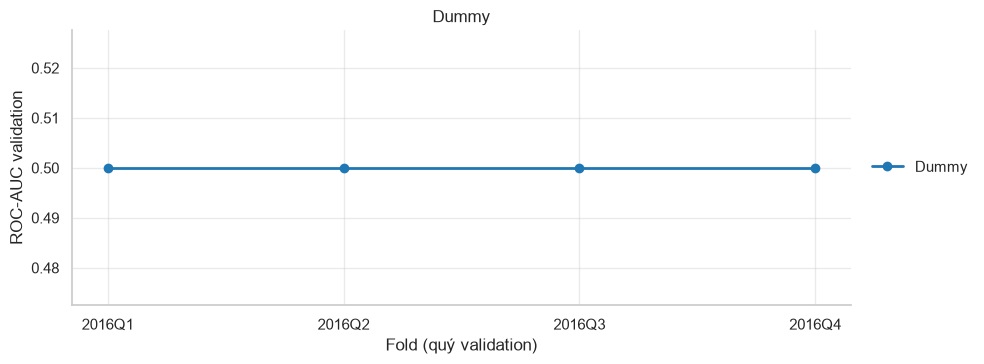

,fold,valid_rows,valid_cancel_rate,roc_auc,average_precision,roc_auc_booking,ap_booking,train_roc_auc,fit_seconds
0,2016Q1,10949,0.3076,0.5000,0.3076,0.5000,0.2058,0.5000,0.2337
1,2016Q2,16190,0.3750,0.5000,0.3750,0.5000,0.2661,0.5000,0.3257
2,2016Q3,15006,0.3559,0.5000,0.3559,0.5000,0.3034,0.5000,0.4625
3,2016Q4,14476,0.3829,0.5000,0.3829,0.5000,0.2866,0.5000,0.5864


WindowsPath('./models/experiments/dummy.json')

In [4]:
dummy_spec = experiments.model_spec("Dummy")
dummy_table, dummy_stage = run_stage({"Dummy": dummy_spec}, "Dummy")
display(dummy_stage["Dummy"].folds)
log.record("Dummy", dummy_spec, dummy_stage["Dummy"])

# 2. Logistic Regression

**Giả định:** ranh giới quyết định tuyến tính; mỗi đặc trưng đóng góp cộng dồn và đơn điệu vào
log-odds của việc hủy. Đây là mô hình đơn giản nhất có ý nghĩa nên đi trước (*start with the
simplest models*), làm mốc cho các mô hình phức tạp hơn và dễ giải thích qua hệ số.

**Hệ quả từ EDA (notebook 01):** cột số lệch phải mạnh (mục 10) làm hệ số bị vài giá trị cực
lớn chi phối → log1p; tỷ lệ hủy tăng đơn điệu nhưng không tuyến tính theo `lead_time` (mục 4)
→ chia khoảng; tỷ lệ hủy phụ thuộc vào tổ hợp khách sạn × phân khúc × đặt cọc (mục 4) mà mô
hình tuyến tính không tự học → ghép đặc trưng; `agent` nhiều nhóm (mục 11) → thử target
encoding.

## 2.1 Cấu hình mặc định

Tham số mặc định của dự án (`modeling.make_estimator`), mã hóa one-hot (CatBoost: chuỗi), chưa
đặt trọng số. Bảng từng fold cho biết tỷ lệ hủy của quý validation, ROC-AUC trên phần train và
thời gian fit.

Mặc định                                     ROC-AUC 0.8253 ± 0.0074  (4s)


,delta_vs_first,cv_roc_auc,cv_roc_auc_std,cv_average_precision,cv_roc_auc_booking,cv_ap_booking,train_roc_auc,overfit_gap,seconds
Mặc định,0.0000,0.8253,0.0074,0.7930,0.7606,0.5745,0.8964,0.0711,3.9007


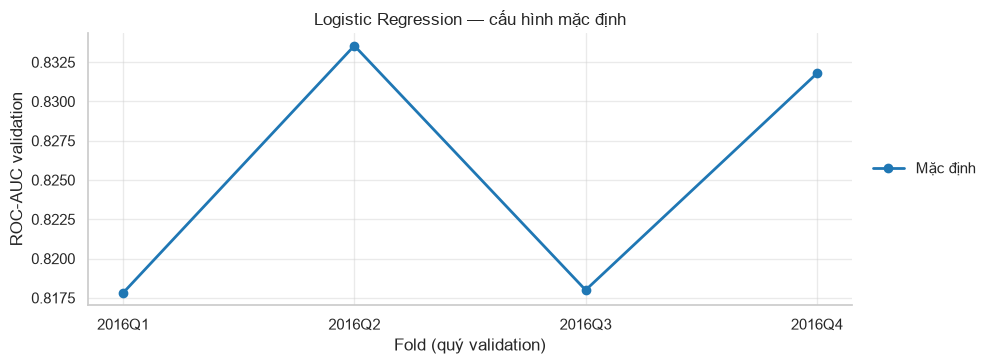

,fold,valid_rows,valid_cancel_rate,roc_auc,average_precision,roc_auc_booking,ap_booking,train_roc_auc,fit_seconds
0,2016Q1,10949,0.3076,0.8178,0.7646,0.7150,0.4371,0.9177,0.7519
1,2016Q2,16190,0.3750,0.8335,0.8191,0.7807,0.6006,0.8999,1.3085
2,2016Q3,15006,0.3559,0.8180,0.7763,0.7660,0.6218,0.8900,2.6018
3,2016Q4,14476,0.3829,0.8318,0.8118,0.7809,0.6386,0.8778,3.1813


In [5]:
lr_default = experiments.model_spec("Logistic Regression")
lr_table1, lr_stage1 = run_stage({"Mặc định": lr_default}, "Logistic Regression — cấu hình mặc định")
display(lr_stage1["Mặc định"].folds)
lr_progress = {"1. Mặc định": lr_stage1["Mặc định"]}

## 2.2 Xử lý dữ liệu theo giả định của mô hình

Mỗi biến thể thêm một kỹ thuật lên biến thể trước:

1. **log1p** các cột trong `modeling.LOG_FEATURES` trước khi chuẩn hóa z-score (scaling).
2. **Chia khoảng** `lead_time` theo các mốc 7 / 30 / 90 / 180 / 365 ngày (discretization).
3. **Ghép đặc trưng** `hotel × deposit_type`, `market_segment × deposit_type`, `hotel × market_segment` (feature crossing).
4. **Target encoding** thay one-hot cho mọi cột phân loại.

**Quy tắc chọn:** các biến thể xếp từ đơn giản đến phức tạp; chọn biến thể đầu tiên có
ROC-AUC cách biến thể tốt nhất không quá `TOLERANCE`. Có thể gán tay `LR_PREP` bằng một nhãn
trong bảng.

Mặc định                                     ROC-AUC 0.8253 ± 0.0074  (dùng lại)


+ log1p                                      ROC-AUC 0.8401 ± 0.0056  (4s)


+ log1p + chia khoảng lead_time              ROC-AUC 0.8400 ± 0.0058  (4s)


+ log1p + chia khoảng + ghép đặc trưng       ROC-AUC 0.8399 ± 0.0064  (5s)


+ log1p + chia khoảng + ghép + target encoding ROC-AUC 0.8293 ± 0.0065  (2s)


,delta_vs_first,cv_roc_auc,cv_roc_auc_std,cv_average_precision,cv_roc_auc_booking,cv_ap_booking,train_roc_auc,overfit_gap,seconds
Mặc định,0.0000,0.8253,0.0074,0.7930,0.7606,0.5745,0.8964,0.0711,3.9007
+ log1p,0.0149,0.8401,0.0056,0.8056,0.7848,0.6045,0.9035,0.0634,3.8706
+ log1p + chia khoảng lead_time,0.0147,0.8400,0.0058,0.8055,0.7840,0.6028,0.9065,0.0665,4.0370
+ log1p + chia khoảng + ghép đặc trưng,0.0147,0.8399,0.0064,0.8060,0.7840,0.6037,0.9069,0.0670,4.8993
+ log1p + chia khoảng + ghép + target encoding,0.0040,0.8293,0.0065,0.7967,0.7692,0.5815,0.8926,0.0634,1.9837


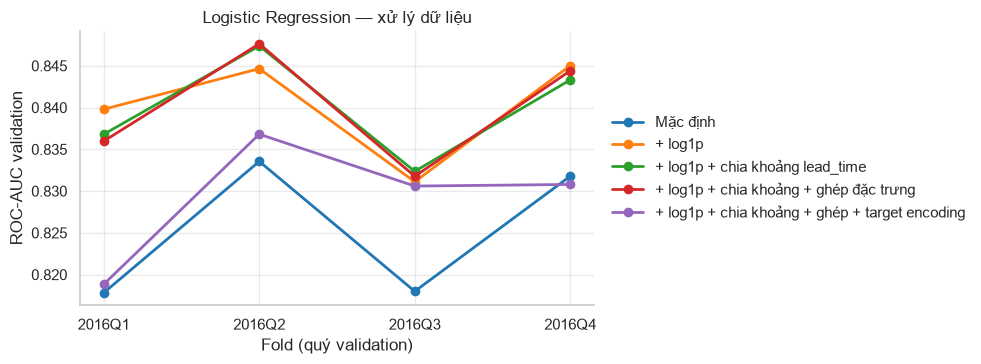

Chọn: + log1p


In [6]:
lr_variants = {
    "Mặc định": lr_default,
    "+ log1p": experiments.model_spec("Logistic Regression", pipeline={"log_skewed": True}),
    "+ log1p + chia khoảng lead_time": experiments.model_spec(
        "Logistic Regression", pipeline={"log_skewed": True, "lead_time_bins": True}),
    "+ log1p + chia khoảng + ghép đặc trưng": experiments.model_spec(
        "Logistic Regression", pipeline={"log_skewed": True, "lead_time_bins": True, "crosses": True}),
    "+ log1p + chia khoảng + ghép + target encoding": experiments.model_spec(
        "Logistic Regression", "target", pipeline={"log_skewed": True, "lead_time_bins": True, "crosses": True}),
}
lr_table2, lr_stage2 = run_stage(lr_variants, "Logistic Regression — xử lý dữ liệu", reuse=lr_stage1)
LR_PREP = experiments.pick_simplest(lr_table2)  # có thể gán tay một nhãn trong bảng
lr_prep = lr_variants[LR_PREP]
lr_progress["2. Xử lý dữ liệu"] = lr_stage2[LR_PREP]
print(f"Chọn: {LR_PREP}")

## 2.3 Trọng số theo thời gian

Hành vi hủy thay đổi theo thời gian (notebook 01 mục 3), nên lượt đặt gần đây được coi trọng
hơn (weighted sampling): trọng số giảm một nửa sau mỗi `half_life_days` ngày tính ngược từ ngày
đến mới nhất của phần train. Trong từng fold, mốc "mới nhất" là cuối phần train của fold đó,
nên không dùng thông tin tương lai. Chọn theo cùng quy tắc ("không trọng số" là đơn giản nhất);
có thể gán tay `LR_HALF_LIFE`.

Không trọng số                               ROC-AUC 0.8401 ± 0.0056  (dùng lại)


half-life 365 ngày                           ROC-AUC 0.8410 ± 0.0058  (4s)


half-life 180 ngày                           ROC-AUC 0.8417 ± 0.0062  (4s)


half-life 90 ngày                            ROC-AUC 0.8429 ± 0.0075  (5s)


half-life 45 ngày                            ROC-AUC 0.8437 ± 0.0083  (5s)


,delta_vs_first,cv_roc_auc,cv_roc_auc_std,cv_average_precision,cv_roc_auc_booking,cv_ap_booking,train_roc_auc,overfit_gap,seconds
Không trọng số,0.0000,0.8401,0.0056,0.8056,0.7848,0.6045,0.9035,0.0634,3.8706
half-life 365 ngày,0.0008,0.8410,0.0058,0.8067,0.7854,0.6064,0.9032,0.0622,4.1005
half-life 180 ngày,0.0016,0.8417,0.0062,0.8073,0.7857,0.6075,0.9026,0.0609,4.3402
half-life 90 ngày,0.0028,0.8429,0.0075,0.8084,0.7862,0.6087,0.9012,0.0582,4.5498
half-life 45 ngày,0.0036,0.8437,0.0083,0.8089,0.7861,0.6088,0.8975,0.0538,4.7246


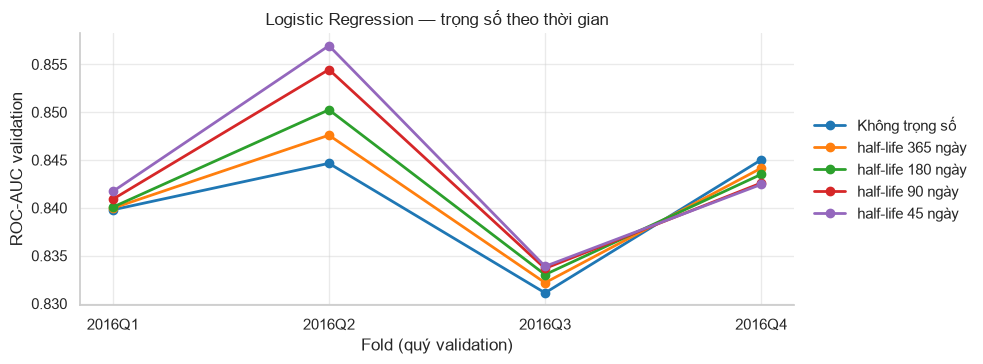

Chọn: half-life 365 ngày


In [7]:
lr_variants = experiments.half_life_variants(lr_prep, HALF_LIVES)
lr_table3, lr_stage3 = run_stage(lr_variants, "Logistic Regression — trọng số theo thời gian",
                                   reuse={"Không trọng số": lr_stage2[LR_PREP]})
LR_HALF_LIFE = experiments.pick_simplest(lr_table3)  # có thể gán tay một nhãn trong bảng
lr_weighted = lr_variants[LR_HALF_LIFE]
lr_progress["3. Trọng số thời gian"] = lr_stage3[LR_HALF_LIFE]
print(f"Chọn: {LR_HALF_LIFE}")

## 2.4 Tinh chỉnh tham số

`C` là nghịch đảo độ mạnh regularization L2 (thang log); `class_weight="balanced"` tăng trọng số
của lớp hủy trong hàm mất mát (class-balanced loss). 14 cấu hình là toàn bộ lưới.

`RandomizedSearchCV` trên đúng 4 fold thời gian, chấm bằng ROC-AUC theo dòng; cách xử lý dữ
liệu và trọng số giữ như các bước trước. Bảng hiện 8 cấu hình tốt nhất.

In [8]:
LR_SPACE = {"C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10], "class_weight": [None, "balanced"]}
LR_N_ITER = 14
lr_tuned = run_tuning(lr_weighted, LR_SPACE, LR_N_ITER)
print(json.dumps(lr_tuned, ensure_ascii=False))

14 cấu hình trong 25s. Tốt nhất: ROC-AUC 0.8443 ± 0.0098


,class_weight,C,mean_test_score,std_test_score,mean_fit_time,rank_test_score
0,NaN,0.0100,0.8443,0.0098,2.0170,1
1,NaN,0.0300,0.8443,0.0092,3.0629,2
2,balanced,0.0100,0.8438,0.0098,2.5590,3
3,NaN,0.1000,0.8436,0.0080,4.1982,4
4,balanced,0.0300,0.8433,0.0089,3.6002,5
5,NaN,0.3000,0.8423,0.0069,4.9660,6
6,balanced,0.1000,0.8422,0.0077,3.9734,7
7,NaN,1.0000,0.8409,0.0057,6.4296,8


{"name": "Logistic Regression", "encoding": "onehot", "half_life_days": 365, "booking_weights": false, "pipeline": {"log_skewed": true}, "params": {"class_weight": null, "C": 0.01}}


## 2.5 Kết quả qua từng giai đoạn

So sánh các giai đoạn trên cùng 4 fold. Cần xem:

- Mỗi bước giúp được bao nhiêu so với độ lệch chuẩn giữa các fold (`cv_roc_auc_std`).
- `cv_roc_auc_booking` / `cv_ap_booking` (mỗi lượt đặt tính một lần): nếu thấp hơn nhiều so với
  cột theo dòng, mô hình đang được lợi nhờ các lượt đặt theo đoàn dễ đoán.
- `overfit_gap` lớn hoặc tăng sau khi tinh chỉnh là dấu hiệu học thuộc phần train.

,delta_vs_first,cv_roc_auc,cv_roc_auc_std,cv_average_precision,cv_roc_auc_booking,cv_ap_booking,train_roc_auc,overfit_gap,seconds
1. Mặc định,0.0000,0.8253,0.0074,0.7930,0.7606,0.5745,0.8964,0.0711,3.9007
2. Xử lý dữ liệu,0.0149,0.8401,0.0056,0.8056,0.7848,0.6045,0.9035,0.0634,3.8706
3. Trọng số thời gian,0.0157,0.8410,0.0058,0.8067,0.7854,0.6064,0.9032,0.0622,4.1005
4. Tinh chỉnh,0.0191,0.8443,0.0098,0.8084,0.7883,0.6105,0.8949,0.0505,7.9134


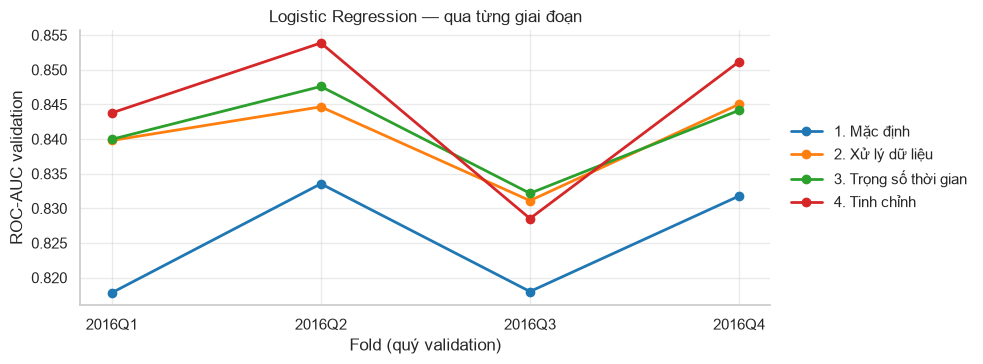

,fold,valid_rows,valid_cancel_rate,roc_auc,average_precision,roc_auc_booking,ap_booking,train_roc_auc,fit_seconds
0,2016Q1,10949,0.3076,0.8438,0.7760,0.7777,0.4870,0.9133,0.8130
1,2016Q2,16190,0.3750,0.8539,0.8355,0.7986,0.6385,0.8992,1.2086
2,2016Q3,15006,0.3559,0.8285,0.7944,0.7814,0.6548,0.8894,1.6857
3,2016Q4,14476,0.3829,0.8512,0.8276,0.7954,0.6619,0.8776,2.0416


In [9]:
lr_final = evaluate_final(lr_tuned, lr_progress, "Logistic Regression — qua từng giai đoạn")

### Hệ số của mô hình

Mô hình cuối được huấn luyện trên toàn bộ train để đọc hệ số. Hệ số dương (cam) làm tăng khả năng
hủy; độ lớn so sánh được với nhau vì đặc trưng đã được chuẩn hóa.

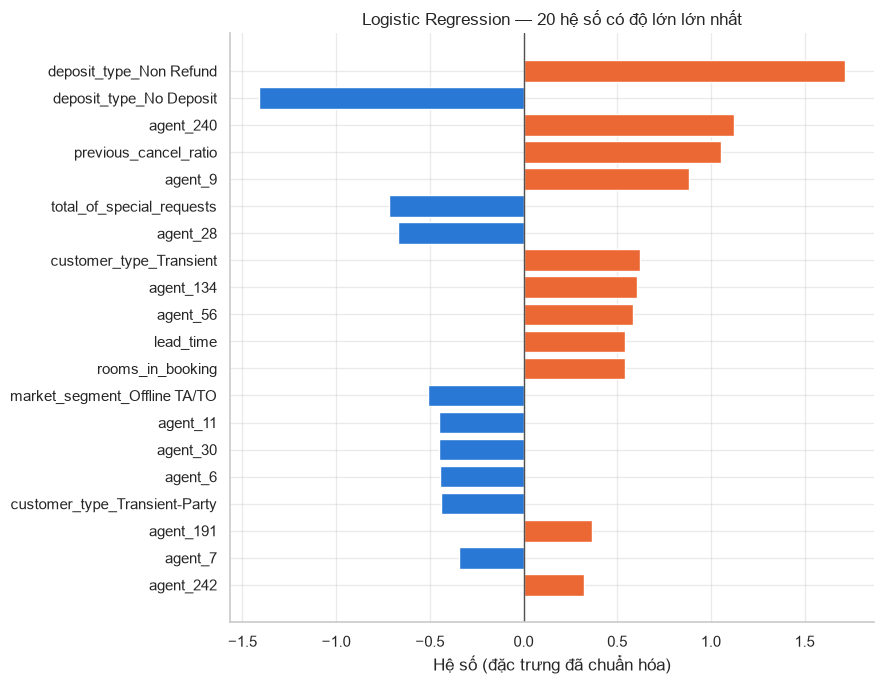

In [10]:
lr_fitted = modeling.build_from_spec(lr_tuned).fit(X_train, y_train)
lr_names = lr_fitted.estimator_.named_steps["preprocess"].get_feature_names_out()
lr_coef = pd.Series(lr_fitted.estimator_.named_steps["model"].coef_[0], index=lr_names)
lr_top = lr_coef.reindex(lr_coef.abs().sort_values(ascending=False).index).head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(lr_top.index, lr_top.values,
        color=[COLORS["canceled"] if value > 0 else COLORS["not_canceled"] for value in lr_top.values])
ax.axvline(0, color=COLORS["reference"], linewidth=1)
ax.set(title="Logistic Regression — 20 hệ số có độ lớn lớn nhất", xlabel="Hệ số (đặc trưng đã chuẩn hóa)")
plt.tight_layout()
plt.show()

## 2.6 Ghi kết quả

Lưu spec, điểm từng fold và dự đoán OOF vào `models/experiments/` để mục 11 trở đi đọc lại.

In [11]:
log.record("Logistic Regression", lr_tuned, lr_final,
           notes={"xử lý dữ liệu": LR_PREP, "trọng số thời gian": LR_HALF_LIFE})

WindowsPath('./models/experiments/logistic_regression.json')

# 3. KNN

**Giả định:** các lượt đặt *gần nhau* (khoảng cách Euclid trên đặc trưng đã chuẩn hóa) có cùng
kết quả (*smoothness*). Mọi cột đóng góp ngang nhau vào khoảng cách, nên thang đo và số chiều
quyết định chất lượng: gần 200 cột one-hot (riêng `agent` hơn 120 cột) làm khoảng cách kém ý
nghĩa. KNN không học tham số: dự đoán phải so với toàn bộ dữ liệu train nên chậm, và không nhận
trọng số mẫu.

**Hệ quả từ EDA:** log1p cột lệch (notebook 01 mục 10); target encoding thay one-hot để giảm số
chiều (mục 11). Không tính ROC-AUC trên train vì rất chậm và luôn gần 1 với `weights="distance"`.

## 3.1 Cấu hình mặc định

Tham số mặc định của dự án (`modeling.make_estimator`), mã hóa one-hot (CatBoost: chuỗi), chưa
đặt trọng số. Bảng từng fold cho biết tỷ lệ hủy của quý validation, ROC-AUC trên phần train và
thời gian fit.

Mặc định                                     ROC-AUC 0.7457 ± 0.0644  (6s)


,delta_vs_first,cv_roc_auc,cv_roc_auc_std,cv_average_precision,cv_roc_auc_booking,cv_ap_booking,train_roc_auc,overfit_gap,seconds
Mặc định,0.0000,0.7457,0.0644,0.7036,0.7175,0.5119,NaN,NaN,6.2812


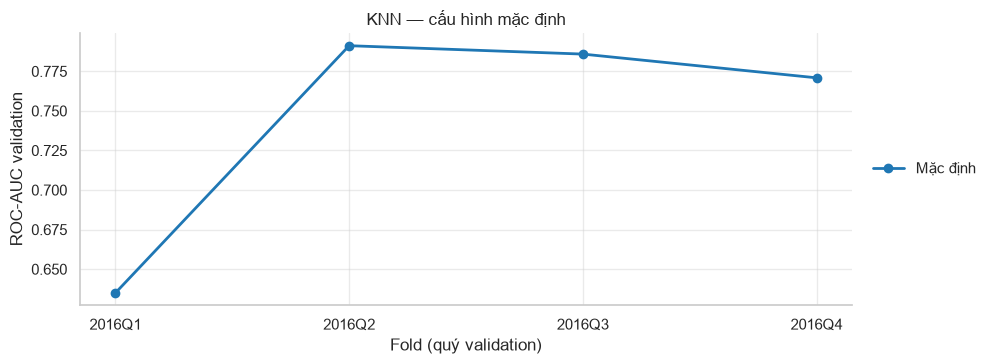

,fold,valid_rows,valid_cancel_rate,roc_auc,average_precision,roc_auc_booking,ap_booking,train_roc_auc,fit_seconds
0,2016Q1,10949,0.3076,0.6350,0.5434,0.6466,0.3171,NaN,0.3742
1,2016Q2,16190,0.3750,0.7912,0.7842,0.7611,0.5848,NaN,0.5646
2,2016Q3,15006,0.3559,0.7859,0.7358,0.7317,0.5776,NaN,0.9238
3,2016Q4,14476,0.3829,0.7709,0.7509,0.7305,0.5679,NaN,1.2753


In [12]:
knn_default = experiments.model_spec("KNN")
knn_table1, knn_stage1 = run_stage({"Mặc định": knn_default}, "KNN — cấu hình mặc định", train_score=False)
display(knn_stage1["Mặc định"].folds)
knn_progress = {"1. Mặc định": knn_stage1["Mặc định"]}

## 3.2 Xử lý dữ liệu theo giả định của mô hình

1. **log1p** các cột lệch trước khi chuẩn hóa.
2. **Target encoding**: mỗi cột phân loại thành một số, giảm số chiều từ gần 200 xuống 31.

**Quy tắc chọn:** các biến thể xếp từ đơn giản đến phức tạp; chọn biến thể đầu tiên có
ROC-AUC cách biến thể tốt nhất không quá `TOLERANCE`. Có thể gán tay `KNN_PREP` bằng một nhãn
trong bảng.

Mặc định                                     ROC-AUC 0.7457 ± 0.0644  (dùng lại)


+ log1p                                      ROC-AUC 0.7668 ± 0.0793  (6s)


+ log1p + target encoding                    ROC-AUC 0.7764 ± 0.0551  (3s)


,delta_vs_first,cv_roc_auc,cv_roc_auc_std,cv_average_precision,cv_roc_auc_booking,cv_ap_booking,train_roc_auc,overfit_gap,seconds
Mặc định,0.0000,0.7457,0.0644,0.7036,0.7175,0.5119,NaN,NaN,6.2812
+ log1p,0.0211,0.7668,0.0793,0.7254,0.7462,0.5504,NaN,NaN,6.0587
+ log1p + target encoding,0.0306,0.7764,0.0551,0.7387,0.7166,0.5185,NaN,NaN,2.6779


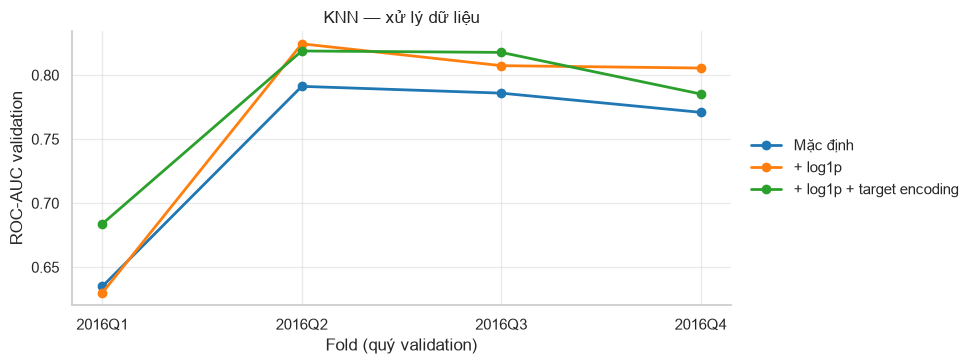

Chọn: + log1p + target encoding


In [13]:
knn_variants = {
    "Mặc định": knn_default,
    "+ log1p": experiments.model_spec("KNN", pipeline={"log_skewed": True}),
    "+ log1p + target encoding": experiments.model_spec("KNN", "target", pipeline={"log_skewed": True}),
}
knn_table2, knn_stage2 = run_stage(knn_variants, "KNN — xử lý dữ liệu", reuse=knn_stage1, train_score=False)
KNN_PREP = experiments.pick_simplest(knn_table2)  # có thể gán tay một nhãn trong bảng
knn_prep = knn_variants[KNN_PREP]
knn_progress["2. Xử lý dữ liệu"] = knn_stage2[KNN_PREP]
print(f"Chọn: {KNN_PREP}")

## 3.3 Trọng số theo thời gian

`KNeighborsClassifier` không nhận `sample_weight`, nên không áp dụng được trọng số theo thời gian
(một giới hạn của mô hình). Giữ nguyên cấu hình của bước 3.2.

In [14]:
KNN_HALF_LIFE = "Không trọng số"
knn_weighted = knn_prep

## 3.4 Tinh chỉnh tham số

Số láng giềng (nhiều hơn → ranh giới mượt hơn, ít overfit hơn) và cách tính phiếu. 8 cấu hình là
toàn bộ lưới; mỗi cấu hình phải tìm láng giềng cho cả fold validation nên bước này chậm.

`RandomizedSearchCV` trên đúng 4 fold thời gian, chấm bằng ROC-AUC theo dòng; cách xử lý dữ
liệu và trọng số giữ như các bước trước. Bảng hiện 8 cấu hình tốt nhất.

In [15]:
KNN_SPACE = {"n_neighbors": [15, 25, 50, 100], "weights": ["uniform", "distance"]}
KNN_N_ITER = 8
knn_tuned = run_tuning(knn_weighted, KNN_SPACE, KNN_N_ITER)
print(json.dumps(knn_tuned, ensure_ascii=False))

8 cấu hình trong 26s. Tốt nhất: ROC-AUC 0.7883 ± 0.0554


,weights,n_neighbors,mean_test_score,std_test_score,mean_fit_time,rank_test_score
0,distance,100,0.7883,0.0554,0.7995,1
1,uniform,100,0.7864,0.0546,0.8800,2
2,distance,50,0.7823,0.0563,0.7481,3
3,uniform,50,0.7808,0.0561,1.1213,4
4,distance,25,0.7764,0.0551,1.1045,5
5,uniform,25,0.7753,0.0552,0.8779,6
6,distance,15,0.7678,0.0542,0.7150,7
7,uniform,15,0.7667,0.0544,0.6209,8


{"name": "KNN", "encoding": "target", "half_life_days": null, "booking_weights": false, "pipeline": {"log_skewed": true}, "params": {"weights": "distance", "n_neighbors": 100}}


## 3.5 Kết quả qua từng giai đoạn

So sánh các giai đoạn trên cùng 4 fold. Cần xem:

- Mỗi bước giúp được bao nhiêu so với độ lệch chuẩn giữa các fold (`cv_roc_auc_std`).
- `cv_roc_auc_booking` / `cv_ap_booking` (mỗi lượt đặt tính một lần): nếu thấp hơn nhiều so với
  cột theo dòng, mô hình đang được lợi nhờ các lượt đặt theo đoàn dễ đoán.
- `overfit_gap` lớn hoặc tăng sau khi tinh chỉnh là dấu hiệu học thuộc phần train.

,delta_vs_first,cv_roc_auc,cv_roc_auc_std,cv_average_precision,cv_roc_auc_booking,cv_ap_booking,train_roc_auc,overfit_gap,seconds
1. Mặc định,0.0000,0.7457,0.0644,0.7036,0.7175,0.5119,NaN,NaN,6.2812
2. Xử lý dữ liệu,0.0306,0.7764,0.0551,0.7387,0.7166,0.5185,NaN,NaN,2.6779
4. Tinh chỉnh,0.0426,0.7883,0.0554,0.7479,0.7216,0.5281,NaN,NaN,5.4681


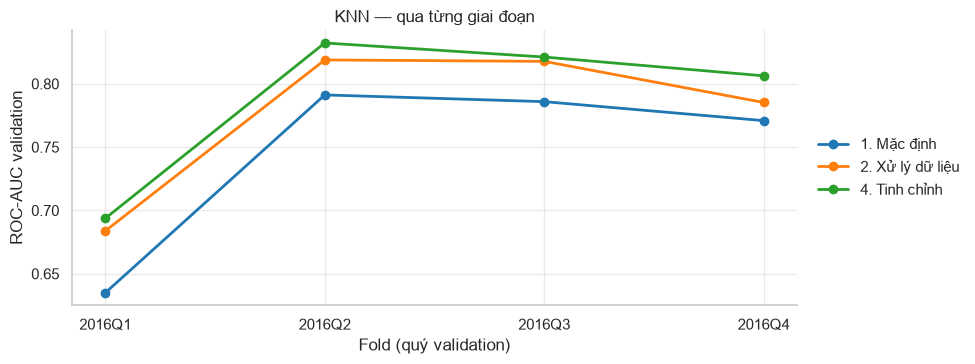

,fold,valid_rows,valid_cancel_rate,roc_auc,average_precision,roc_auc_booking,ap_booking,train_roc_auc,fit_seconds
0,2016Q1,10949,0.3076,0.6937,0.6067,0.6192,0.3073,NaN,0.2177
1,2016Q2,16190,0.3750,0.8322,0.8223,0.7791,0.6191,NaN,0.2845
2,2016Q3,15006,0.3559,0.8211,0.7744,0.7587,0.6092,NaN,0.3798
3,2016Q4,14476,0.3829,0.8063,0.7881,0.7295,0.5767,NaN,0.5508


In [16]:
knn_final = evaluate_final(knn_tuned, knn_progress, "KNN — qua từng giai đoạn", train_score=False)

KNN không có hệ số hay độ quan trọng đặc trưng; xem permutation importance của mô hình được chọn
ở mục 17.

## 3.6 Ghi kết quả

Lưu spec, điểm từng fold và dự đoán OOF vào `models/experiments/` để mục 11 trở đi đọc lại.

In [17]:
log.record("KNN", knn_tuned, knn_final,
           notes={"xử lý dữ liệu": KNN_PREP, "trọng số thời gian": KNN_HALF_LIFE})

WindowsPath('./models/experiments/knn.json')

# 4. SVM (RBF)

**Giả định:** tìm ranh giới có lề lớn nhất trong không gian kernel RBF; ranh giới phi tuyến nhưng
trơn. Kernel RBF dựa trên khoảng cách nên, giống KNN, thang đo và cột lệch ảnh hưởng trực tiếp.
`SVC` chính xác có thời gian huấn luyện tăng nhanh hơn bình phương số dòng, nên kernel được xấp xỉ
bằng Nystroem (mặc định 1500 điểm mốc) rồi huấn luyện LinearSVC; xác suất có được nhờ Platt
scaling (`modeling.KernelSVM`).

**Hệ quả từ EDA:** log1p cột lệch (notebook 01 mục 10); thử target encoding để giảm số chiều.

## 4.1 Cấu hình mặc định

Tham số mặc định của dự án (`modeling.make_estimator`), mã hóa one-hot (CatBoost: chuỗi), chưa
đặt trọng số. Bảng từng fold cho biết tỷ lệ hủy của quý validation, ROC-AUC trên phần train và
thời gian fit.

Mặc định                                     ROC-AUC 0.8366 ± 0.0155  (77s)


,delta_vs_first,cv_roc_auc,cv_roc_auc_std,cv_average_precision,cv_roc_auc_booking,cv_ap_booking,train_roc_auc,overfit_gap,seconds
Mặc định,0.0000,0.8366,0.0155,0.8036,0.7685,0.5917,0.9077,0.0711,76.5517


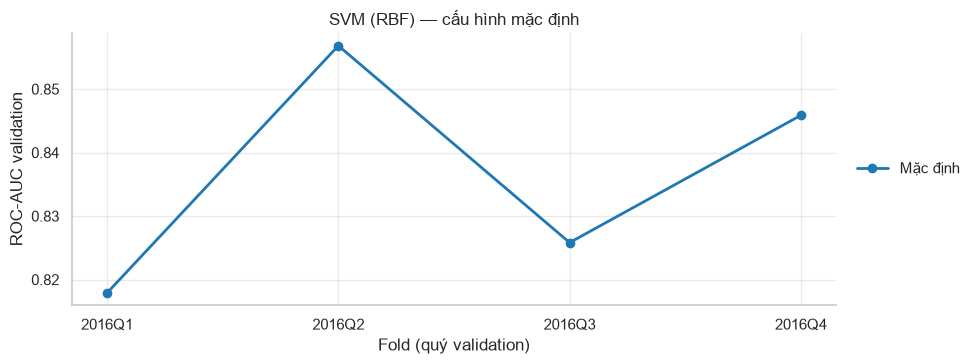

,fold,valid_rows,valid_cancel_rate,roc_auc,average_precision,roc_auc_booking,ap_booking,train_roc_auc,fit_seconds
0,2016Q1,10949,0.3076,0.8179,0.7655,0.7184,0.4522,0.9264,21.0948
1,2016Q2,16190,0.3750,0.8568,0.8399,0.7939,0.6265,0.9113,33.9692
2,2016Q3,15006,0.3559,0.8258,0.7891,0.7720,0.6400,0.9031,55.4582
3,2016Q4,14476,0.3829,0.8459,0.8199,0.7897,0.6483,0.8901,71.2856


In [18]:
svm_default = experiments.model_spec("SVM (RBF)")
svm_table1, svm_stage1 = run_stage({"Mặc định": svm_default}, "SVM (RBF) — cấu hình mặc định")
display(svm_stage1["Mặc định"].folds)
svm_progress = {"1. Mặc định": svm_stage1["Mặc định"]}

## 4.2 Xử lý dữ liệu theo giả định của mô hình

1. **log1p** các cột lệch trước khi chuẩn hóa.
2. **Target encoding** thay one-hot.

**Quy tắc chọn:** các biến thể xếp từ đơn giản đến phức tạp; chọn biến thể đầu tiên có
ROC-AUC cách biến thể tốt nhất không quá `TOLERANCE`. Có thể gán tay `SVM_PREP` bằng một nhãn
trong bảng.

Mặc định                                     ROC-AUC 0.8366 ± 0.0155  (dùng lại)


+ log1p                                      ROC-AUC 0.8471 ± 0.0148  (81s)


+ log1p + target encoding                    ROC-AUC 0.8231 ± 0.0261  (80s)


,delta_vs_first,cv_roc_auc,cv_roc_auc_std,cv_average_precision,cv_roc_auc_booking,cv_ap_booking,train_roc_auc,overfit_gap,seconds
Mặc định,0.0000,0.8366,0.0155,0.8036,0.7685,0.5917,0.9077,0.0711,76.5517
+ log1p,0.0105,0.8471,0.0148,0.8148,0.7895,0.6177,0.9144,0.0673,80.8451
+ log1p + target encoding,-0.0135,0.8231,0.0261,0.7860,0.7613,0.5680,0.9120,0.0889,79.9331


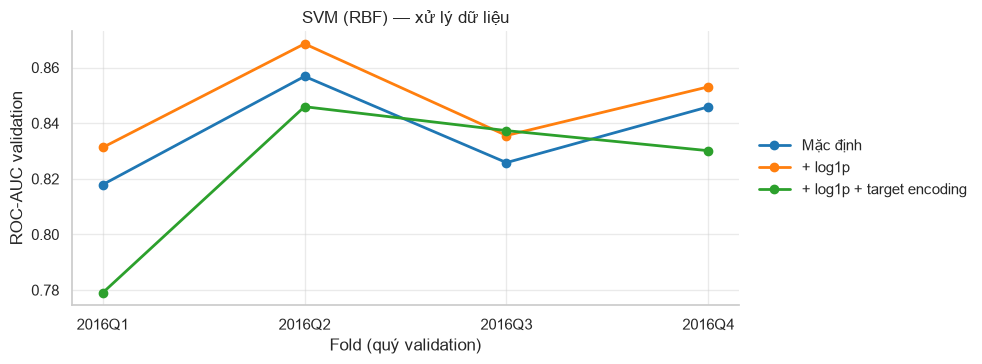

Chọn: + log1p


In [19]:
svm_variants = {
    "Mặc định": svm_default,
    "+ log1p": experiments.model_spec("SVM (RBF)", pipeline={"log_skewed": True}),
    "+ log1p + target encoding": experiments.model_spec("SVM (RBF)", "target", pipeline={"log_skewed": True}),
}
svm_table2, svm_stage2 = run_stage(svm_variants, "SVM (RBF) — xử lý dữ liệu", reuse=svm_stage1)
SVM_PREP = experiments.pick_simplest(svm_table2)  # có thể gán tay một nhãn trong bảng
svm_prep = svm_variants[SVM_PREP]
svm_progress["2. Xử lý dữ liệu"] = svm_stage2[SVM_PREP]
print(f"Chọn: {SVM_PREP}")

## 4.3 Trọng số theo thời gian

Hành vi hủy thay đổi theo thời gian (notebook 01 mục 3), nên lượt đặt gần đây được coi trọng
hơn (weighted sampling): trọng số giảm một nửa sau mỗi `half_life_days` ngày tính ngược từ ngày
đến mới nhất của phần train. Trong từng fold, mốc "mới nhất" là cuối phần train của fold đó,
nên không dùng thông tin tương lai. Chọn theo cùng quy tắc ("không trọng số" là đơn giản nhất);
có thể gán tay `SVM_HALF_LIFE`.

Không trọng số                               ROC-AUC 0.8471 ± 0.0148  (dùng lại)


half-life 365 ngày                           ROC-AUC 0.8478 ± 0.0150  (75s)


half-life 180 ngày                           ROC-AUC 0.8482 ± 0.0152  (59s)


half-life 90 ngày                            ROC-AUC 0.8487 ± 0.0159  (66s)


half-life 45 ngày                            ROC-AUC 0.8482 ± 0.0180  (83s)


,delta_vs_first,cv_roc_auc,cv_roc_auc_std,cv_average_precision,cv_roc_auc_booking,cv_ap_booking,train_roc_auc,overfit_gap,seconds
Không trọng số,0.0000,0.8471,0.0148,0.8148,0.7895,0.6177,0.9144,0.0673,80.8451
half-life 365 ngày,0.0007,0.8478,0.0150,0.8154,0.7899,0.6188,0.9138,0.0660,75.0104
half-life 180 ngày,0.0011,0.8482,0.0152,0.8159,0.7900,0.6192,0.9128,0.0646,58.6273
half-life 90 ngày,0.0016,0.8487,0.0159,0.8162,0.7894,0.6189,0.9104,0.0617,66.3761
half-life 45 ngày,0.0011,0.8482,0.0180,0.8153,0.7869,0.6159,0.9052,0.0570,82.5429


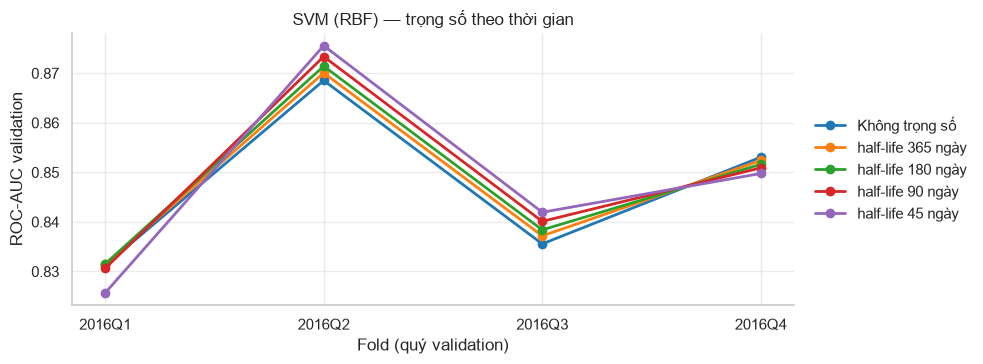

Chọn: Không trọng số


In [20]:
svm_variants = experiments.half_life_variants(svm_prep, HALF_LIVES)
svm_table3, svm_stage3 = run_stage(svm_variants, "SVM (RBF) — trọng số theo thời gian",
                                   reuse={"Không trọng số": svm_stage2[SVM_PREP]})
SVM_HALF_LIFE = experiments.pick_simplest(svm_table3)  # có thể gán tay một nhãn trong bảng
svm_weighted = svm_variants[SVM_HALF_LIFE]
svm_progress["3. Trọng số thời gian"] = svm_stage3[SVM_HALF_LIFE]
print(f"Chọn: {SVM_HALF_LIFE}")

## 4.4 Tinh chỉnh tham số

`C` (mức phạt lỗi), `gamma` (độ rộng kernel: lớn → ranh giới uốn lượn hơn), số điểm mốc
Nystroem và `class_weight`. Mỗi lần fit cần vài GB RAM nên chỉ chạy 3 fit song song
(`n_jobs=3`) và 6 cấu hình; tăng `SVM_N_ITER` nếu máy đủ mạnh.

`RandomizedSearchCV` trên đúng 4 fold thời gian, chấm bằng ROC-AUC theo dòng; cách xử lý dữ
liệu và trọng số giữ như các bước trước. Bảng hiện 8 cấu hình tốt nhất.

In [21]:
SVM_SPACE = {"C": [0.03, 0.1, 0.3, 1.0], "gamma": [0.003, 0.005, 0.01, 0.02], "n_components": [1000, 1500],
              "class_weight": [None, "balanced"]}
SVM_N_ITER = 6
svm_tuned = run_tuning(svm_weighted, SVM_SPACE, SVM_N_ITER, n_jobs=3)
print(json.dumps(svm_tuned, ensure_ascii=False))

6 cấu hình trong 313s. Tốt nhất: ROC-AUC 0.8474 ± 0.0130


,n_components,gamma,class_weight,C,mean_test_score,std_test_score,mean_fit_time,rank_test_score
0,1500,0.0100,NaN,0.0300,0.8474,0.0130,29.7293,1
1,1000,0.0030,NaN,0.0300,0.8447,0.0101,13.0089,2
2,1000,0.0100,NaN,0.3000,0.8447,0.0156,32.1573,3
3,1000,0.0050,balanced,1.0000,0.8442,0.0136,44.9436,4
4,1000,0.0100,balanced,0.3000,0.8437,0.0156,37.4537,5
5,1000,0.0100,NaN,1.0000,0.8404,0.0170,51.2368,6


{"name": "SVM (RBF)", "encoding": "onehot", "half_life_days": null, "booking_weights": false, "pipeline": {"log_skewed": true}, "params": {"n_components": 1500, "gamma": 0.01, "class_weight": null, "C": 0.03}}


## 4.5 Kết quả qua từng giai đoạn

So sánh các giai đoạn trên cùng 4 fold. Cần xem:

- Mỗi bước giúp được bao nhiêu so với độ lệch chuẩn giữa các fold (`cv_roc_auc_std`).
- `cv_roc_auc_booking` / `cv_ap_booking` (mỗi lượt đặt tính một lần): nếu thấp hơn nhiều so với
  cột theo dòng, mô hình đang được lợi nhờ các lượt đặt theo đoàn dễ đoán.
- `overfit_gap` lớn hoặc tăng sau khi tinh chỉnh là dấu hiệu học thuộc phần train.

,delta_vs_first,cv_roc_auc,cv_roc_auc_std,cv_average_precision,cv_roc_auc_booking,cv_ap_booking,train_roc_auc,overfit_gap,seconds
1. Mặc định,0.0000,0.8366,0.0155,0.8036,0.7685,0.5917,0.9077,0.0711,76.5517
2. Xử lý dữ liệu,0.0105,0.8471,0.0148,0.8148,0.7895,0.6177,0.9144,0.0673,80.8451
3. Trọng số thời gian,0.0105,0.8471,0.0148,0.8148,0.7895,0.6177,0.9144,0.0673,80.8451
4. Tinh chỉnh,0.0108,0.8474,0.0130,0.8145,0.7901,0.6201,0.9044,0.0570,51.7021


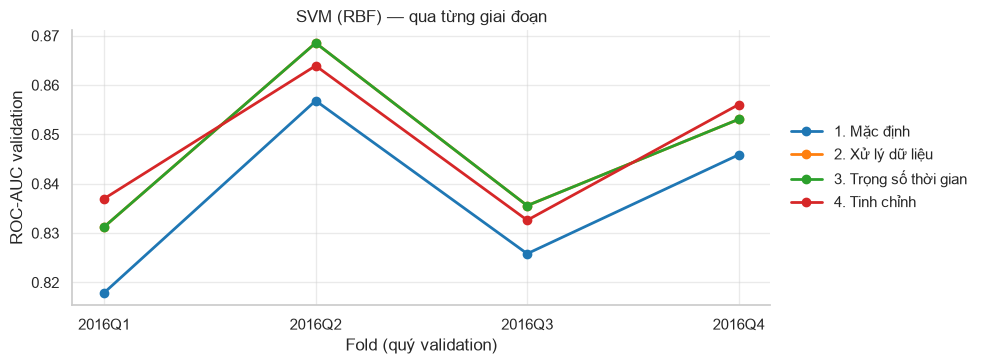

,fold,valid_rows,valid_cancel_rate,roc_auc,average_precision,roc_auc_booking,ap_booking,train_roc_auc,fit_seconds
0,2016Q1,10949,0.3076,0.8370,0.7808,0.7671,0.5040,0.9211,16.6910
1,2016Q2,16190,0.3750,0.8639,0.8465,0.8071,0.6547,0.9075,25.1526
2,2016Q3,15006,0.3559,0.8326,0.7976,0.7844,0.6557,0.9005,35.3620
3,2016Q4,14476,0.3829,0.8561,0.8330,0.8016,0.6660,0.8886,45.7770


In [22]:
svm_final = evaluate_final(svm_tuned, svm_progress, "SVM (RBF) — qua từng giai đoạn")

SVM với kernel xấp xỉ không có độ quan trọng đặc trưng trực tiếp; xem permutation importance của
mô hình được chọn ở mục 17.

## 4.6 Ghi kết quả

Lưu spec, điểm từng fold và dự đoán OOF vào `models/experiments/` để mục 11 trở đi đọc lại.

In [23]:
log.record("SVM (RBF)", svm_tuned, svm_final,
           notes={"xử lý dữ liệu": SVM_PREP, "trọng số thời gian": SVM_HALF_LIFE})

WindowsPath('./models/experiments/svm_rbf.json')

# 5. Decision Tree

**Giả định:** chia không gian đặc trưng bằng các ngưỡng trên từng cột. Một cây đơn có phương sai
cao (dễ học thuộc train), là nền tảng của Random Forest và boosting ở các mục sau.

Mô hình cây chỉ dùng **thứ tự** giá trị nên không cần chuẩn hóa hay log1p (notebook 01 mục 10)
và tự học được tương tác, nên bước X.2 chỉ so sánh cách mã hóa biến phân loại.

## 5.1 Cấu hình mặc định

Tham số mặc định của dự án (`modeling.make_estimator`), mã hóa one-hot (CatBoost: chuỗi), chưa
đặt trọng số. Bảng từng fold cho biết tỷ lệ hủy của quý validation, ROC-AUC trên phần train và
thời gian fit.

Mặc định                                     ROC-AUC 0.7881 ± 0.0272  (2s)


,delta_vs_first,cv_roc_auc,cv_roc_auc_std,cv_average_precision,cv_roc_auc_booking,cv_ap_booking,train_roc_auc,overfit_gap,seconds
Mặc định,0.0000,0.7881,0.0272,0.7213,0.7248,0.5118,0.9452,0.1571,1.7209


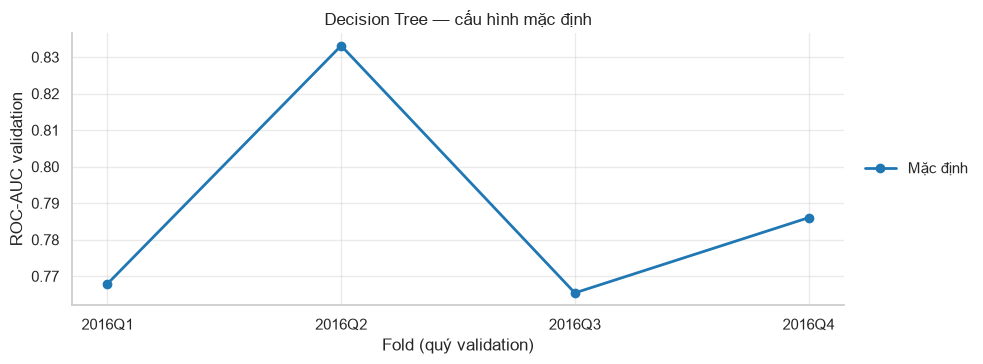

,fold,valid_rows,valid_cancel_rate,roc_auc,average_precision,roc_auc_booking,ap_booking,train_roc_auc,fit_seconds
0,2016Q1,10949,0.3076,0.7679,0.6046,0.6797,0.3569,0.9566,0.3866
1,2016Q2,16190,0.3750,0.8331,0.8175,0.7830,0.6209,0.9464,0.6046
2,2016Q3,15006,0.3559,0.7654,0.6871,0.6938,0.4738,0.9435,0.9074
3,2016Q4,14476,0.3829,0.7860,0.7761,0.7427,0.5957,0.9343,1.2057


In [24]:
dt_default = experiments.model_spec("Decision Tree")
dt_table1, dt_stage1 = run_stage({"Mặc định": dt_default}, "Decision Tree — cấu hình mặc định")
display(dt_stage1["Mặc định"].folds)
dt_progress = {"1. Mặc định": dt_stage1["Mặc định"]}

## 5.2 Xử lý dữ liệu theo giả định của mô hình

**One-hot** (mặc định, mỗi nhóm một cột nhị phân) so với **target encoding** (mỗi cột phân loại
một số; cây có thể tách các nhóm `agent` có tỷ lệ hủy cao bằng một ngưỡng duy nhất).

**Quy tắc chọn:** các biến thể xếp từ đơn giản đến phức tạp; chọn biến thể đầu tiên có
ROC-AUC cách biến thể tốt nhất không quá `TOLERANCE`. Có thể gán tay `DT_PREP` bằng một nhãn
trong bảng.

Mặc định                                     ROC-AUC 0.7881 ± 0.0272  (dùng lại)


Target encoding                              ROC-AUC 0.7858 ± 0.0253  (1s)


,delta_vs_first,cv_roc_auc,cv_roc_auc_std,cv_average_precision,cv_roc_auc_booking,cv_ap_booking,train_roc_auc,overfit_gap,seconds
Mặc định,0.0000,0.7881,0.0272,0.7213,0.7248,0.5118,0.9452,0.1571,1.7209
Target encoding,-0.0023,0.7858,0.0253,0.7419,0.7074,0.5094,0.9422,0.1564,1.0786


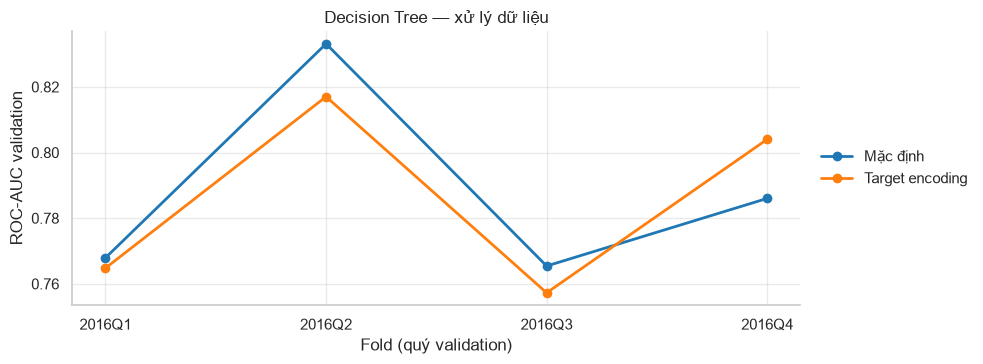

Chọn: Mặc định


In [25]:
dt_variants = {
    "Mặc định": dt_default,
    "Target encoding": experiments.model_spec("Decision Tree", "target"),
}
dt_table2, dt_stage2 = run_stage(dt_variants, "Decision Tree — xử lý dữ liệu", reuse=dt_stage1)
DT_PREP = experiments.pick_simplest(dt_table2)  # có thể gán tay một nhãn trong bảng
dt_prep = dt_variants[DT_PREP]
dt_progress["2. Xử lý dữ liệu"] = dt_stage2[DT_PREP]
print(f"Chọn: {DT_PREP}")

## 5.3 Trọng số theo thời gian

Hành vi hủy thay đổi theo thời gian (notebook 01 mục 3), nên lượt đặt gần đây được coi trọng
hơn (weighted sampling): trọng số giảm một nửa sau mỗi `half_life_days` ngày tính ngược từ ngày
đến mới nhất của phần train. Trong từng fold, mốc "mới nhất" là cuối phần train của fold đó,
nên không dùng thông tin tương lai. Chọn theo cùng quy tắc ("không trọng số" là đơn giản nhất);
có thể gán tay `DT_HALF_LIFE`.

Không trọng số                               ROC-AUC 0.7881 ± 0.0272  (dùng lại)


half-life 365 ngày                           ROC-AUC 0.7966 ± 0.0307  (2s)


half-life 180 ngày                           ROC-AUC 0.8036 ± 0.0165  (2s)


half-life 90 ngày                            ROC-AUC 0.8089 ± 0.0174  (2s)


half-life 45 ngày                            ROC-AUC 0.8108 ± 0.0069  (2s)


,delta_vs_first,cv_roc_auc,cv_roc_auc_std,cv_average_precision,cv_roc_auc_booking,cv_ap_booking,train_roc_auc,overfit_gap,seconds
Không trọng số,0.0000,0.7881,0.0272,0.7213,0.7248,0.5118,0.9452,0.1571,1.7209
half-life 365 ngày,0.0085,0.7966,0.0307,0.7279,0.7342,0.5179,0.9450,0.1484,1.7420
half-life 180 ngày,0.0155,0.8036,0.0165,0.7608,0.7404,0.5368,0.9442,0.1406,1.7112
half-life 90 ngày,0.0208,0.8089,0.0174,0.7386,0.7421,0.5259,0.9410,0.1321,1.7959
half-life 45 ngày,0.0227,0.8108,0.0069,0.7712,0.7375,0.5324,0.9304,0.1195,1.7818


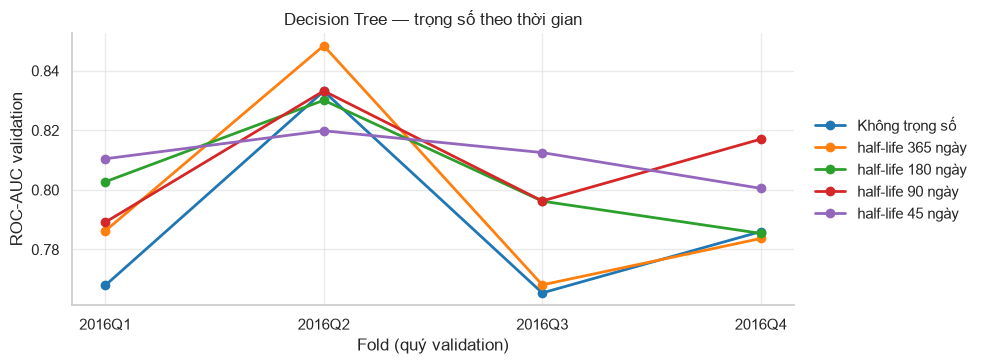

Chọn: half-life 90 ngày


In [26]:
dt_variants = experiments.half_life_variants(dt_prep, HALF_LIVES)
dt_table3, dt_stage3 = run_stage(dt_variants, "Decision Tree — trọng số theo thời gian",
                                   reuse={"Không trọng số": dt_stage2[DT_PREP]})
DT_HALF_LIFE = experiments.pick_simplest(dt_table3)  # có thể gán tay một nhãn trong bảng
dt_weighted = dt_variants[DT_HALF_LIFE]
dt_progress["3. Trọng số thời gian"] = dt_stage3[DT_HALF_LIFE]
print(f"Chọn: {DT_HALF_LIFE}")

## 5.4 Tinh chỉnh tham số

Độ sâu tối đa và số mẫu tối thiểu ở mỗi lá kiểm soát độ phức tạp (cây càng nông, lá càng lớn thì
càng ít overfit); `class_weight` như ở Logistic Regression.

`RandomizedSearchCV` trên đúng 4 fold thời gian, chấm bằng ROC-AUC theo dòng; cách xử lý dữ
liệu và trọng số giữ như các bước trước. Bảng hiện 8 cấu hình tốt nhất.

In [27]:
DT_SPACE = {"max_depth": [6, 8, 10, 12, 16, None], "min_samples_leaf": [10, 20, 50, 100, 200],
             "class_weight": [None, "balanced"]}
DT_N_ITER = 20
dt_tuned = run_tuning(dt_weighted, DT_SPACE, DT_N_ITER)
print(json.dumps(dt_tuned, ensure_ascii=False))

20 cấu hình trong 14s. Tốt nhất: ROC-AUC 0.8311 ± 0.0232


,min_samples_leaf,max_depth,class_weight,mean_test_score,std_test_score,mean_fit_time,rank_test_score
0,100,8,NaN,0.8311,0.0232,1.5458,1
1,20,8,balanced,0.8309,0.0205,1.5715,2
2,10,10,balanced,0.8282,0.0297,1.4549,3
3,100,6,NaN,0.8266,0.0213,1.5507,4
4,100,6,balanced,0.8257,0.0208,1.3146,5
5,10,8,NaN,0.8257,0.0167,1.6823,6
6,200,6,NaN,0.8244,0.0219,1.0443,7
7,20,8,NaN,0.8243,0.0187,1.4266,8


{"name": "Decision Tree", "encoding": "onehot", "half_life_days": 90, "booking_weights": false, "pipeline": {}, "params": {"min_samples_leaf": 100, "max_depth": 8, "class_weight": null}}


## 5.5 Kết quả qua từng giai đoạn

So sánh các giai đoạn trên cùng 4 fold. Cần xem:

- Mỗi bước giúp được bao nhiêu so với độ lệch chuẩn giữa các fold (`cv_roc_auc_std`).
- `cv_roc_auc_booking` / `cv_ap_booking` (mỗi lượt đặt tính một lần): nếu thấp hơn nhiều so với
  cột theo dòng, mô hình đang được lợi nhờ các lượt đặt theo đoàn dễ đoán.
- `overfit_gap` lớn hoặc tăng sau khi tinh chỉnh là dấu hiệu học thuộc phần train.

,delta_vs_first,cv_roc_auc,cv_roc_auc_std,cv_average_precision,cv_roc_auc_booking,cv_ap_booking,train_roc_auc,overfit_gap,seconds
1. Mặc định,0.0000,0.7881,0.0272,0.7213,0.7248,0.5118,0.9452,0.1571,1.7209
2. Xử lý dữ liệu,0.0000,0.7881,0.0272,0.7213,0.7248,0.5118,0.9452,0.1571,1.7209
3. Trọng số thời gian,0.0208,0.8089,0.0174,0.7386,0.7421,0.5259,0.9410,0.1321,1.7959
4. Tinh chỉnh,0.0429,0.8311,0.0232,0.7747,0.7624,0.5576,0.9007,0.0696,4.1152


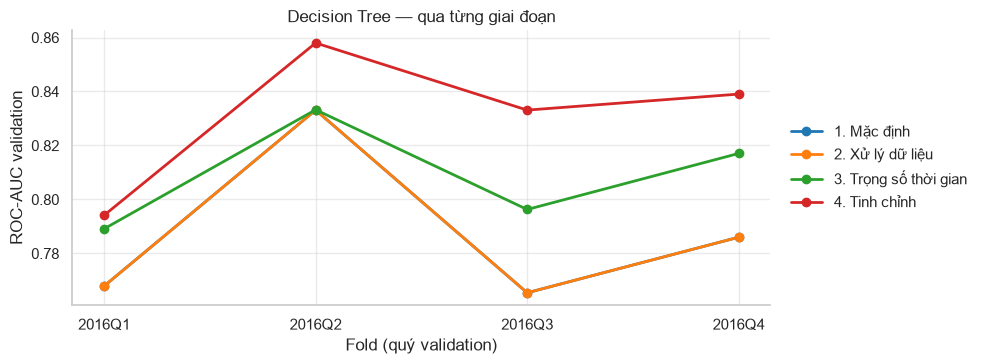

,fold,valid_rows,valid_cancel_rate,roc_auc,average_precision,roc_auc_booking,ap_booking,train_roc_auc,fit_seconds
0,2016Q1,10949,0.3076,0.7941,0.6961,0.6844,0.3569,0.9244,0.3728
1,2016Q2,16190,0.3750,0.8580,0.8213,0.7913,0.6180,0.8982,0.5634
2,2016Q3,15006,0.3559,0.8331,0.7734,0.7805,0.6188,0.8941,0.8531
3,2016Q4,14476,0.3829,0.8390,0.8080,0.7935,0.6368,0.8861,1.0328


In [28]:
dt_final = evaluate_final(dt_tuned, dt_progress, "Decision Tree — qua từng giai đoạn")

### Cấu trúc cây và độ quan trọng đặc trưng

Độ quan trọng sẵn có của cây là tổng mức giảm impurity tại các nút chia theo từng cột (tính trên
train, nên thiên vị cột có nhiều giá trị). Permutation importance của mô hình được chọn ở mục 17
đáng tin hơn.

Độ sâu: 8, số lá: 78


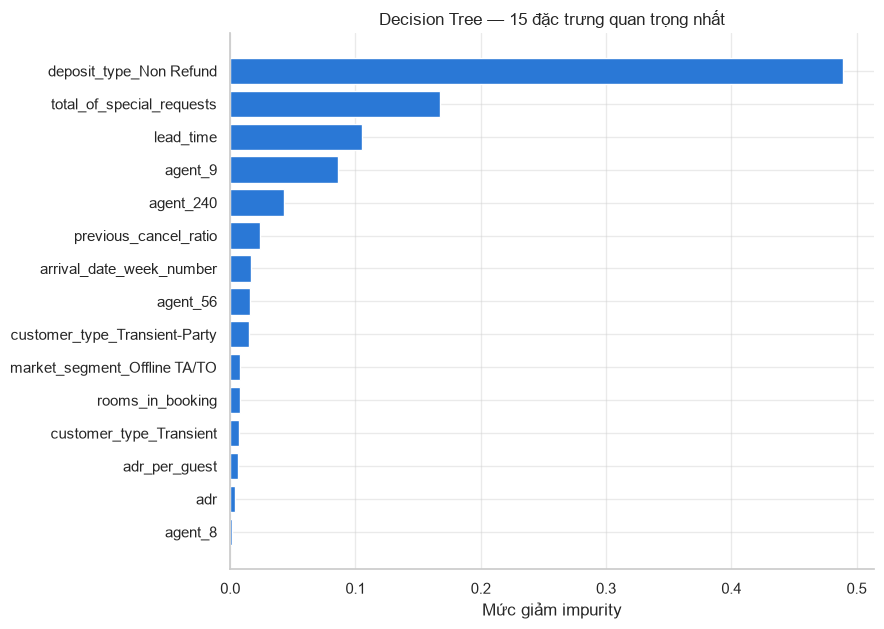

In [29]:
dt_fitted = modeling.build_from_spec(dt_tuned).fit(X_train, y_train)
dt_tree = dt_fitted.estimator_.named_steps["model"]
print(f"Độ sâu: {dt_tree.get_depth()}, số lá: {dt_tree.get_n_leaves()}")
plot_bar(top_importances(dt_fitted), "Decision Tree — 15 đặc trưng quan trọng nhất", "Mức giảm impurity")

## 5.6 Ghi kết quả

Lưu spec, điểm từng fold và dự đoán OOF vào `models/experiments/` để mục 11 trở đi đọc lại.

In [30]:
log.record("Decision Tree", dt_tuned, dt_final,
           notes={"xử lý dữ liệu": DT_PREP, "trọng số thời gian": DT_HALF_LIFE})

WindowsPath('./models/experiments/decision_tree.json')

# 6. Random Forest

**Bagging:** nhiều cây sâu, mỗi cây học trên một mẫu bootstrap (lấy mẫu có hoàn lại) và chỉ xét
ngẫu nhiên một phần cột ở mỗi lần chia; trung bình các cây làm giảm phương sai của cây đơn (tài
liệu: bagging cải thiện các phương pháp không ổn định như cây). Khoảng cách train–validation lớn
là bình thường với Random Forest; điều cần xem là ROC-AUC validation.

Mô hình cây chỉ dùng **thứ tự** giá trị nên không cần chuẩn hóa hay log1p (notebook 01 mục 10)
và tự học được tương tác, nên bước X.2 chỉ so sánh cách mã hóa biến phân loại.

## 6.1 Cấu hình mặc định

Tham số mặc định của dự án (`modeling.make_estimator`), mã hóa one-hot (CatBoost: chuỗi), chưa
đặt trọng số. Bảng từng fold cho biết tỷ lệ hủy của quý validation, ROC-AUC trên phần train và
thời gian fit.

Mặc định                                     ROC-AUC 0.8407 ± 0.0241  (9s)


,delta_vs_first,cv_roc_auc,cv_roc_auc_std,cv_average_precision,cv_roc_auc_booking,cv_ap_booking,train_roc_auc,overfit_gap,seconds
Mặc định,0.0000,0.8407,0.0241,0.7999,0.7799,0.5869,0.9849,0.1441,8.6698


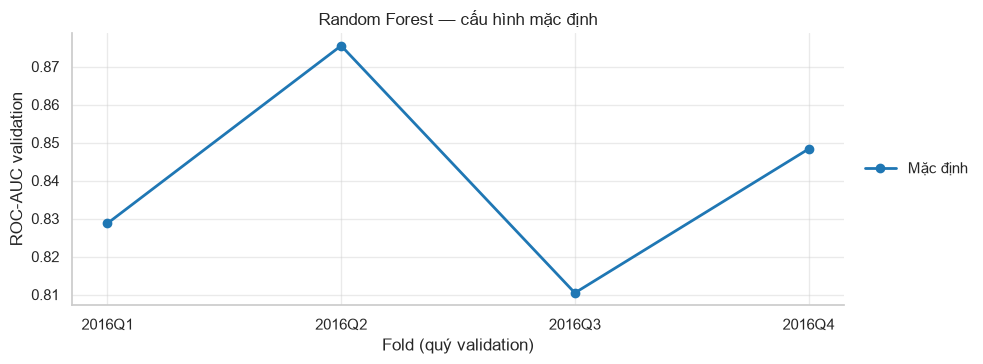

,fold,valid_rows,valid_cancel_rate,roc_auc,average_precision,roc_auc_booking,ap_booking,train_roc_auc,fit_seconds
0,2016Q1,10949,0.3076,0.8287,0.7633,0.7543,0.4579,0.9901,0.8937
1,2016Q2,16190,0.3750,0.8755,0.8606,0.8171,0.6758,0.9872,1.2795
2,2016Q3,15006,0.3559,0.8104,0.7544,0.7440,0.5707,0.9835,1.8959
3,2016Q4,14476,0.3829,0.8483,0.8211,0.8041,0.6431,0.9787,2.5651


In [31]:
rf_default = experiments.model_spec("Random Forest")
rf_table1, rf_stage1 = run_stage({"Mặc định": rf_default}, "Random Forest — cấu hình mặc định")
display(rf_stage1["Mặc định"].folds)
rf_progress = {"1. Mặc định": rf_stage1["Mặc định"]}

## 6.2 Xử lý dữ liệu theo giả định của mô hình

**One-hot** so với **target encoding**. Với one-hot và `max_features="sqrt"`, mỗi lần chia chỉ xét
khoảng căn bậc hai của số cột, nên các cột mạnh nhưng chỉ chiếm vài cột one-hot (như
`deposit_type`) ít khi được xét; target encoding giảm số cột từ gần 200 xuống 31.

**Quy tắc chọn:** các biến thể xếp từ đơn giản đến phức tạp; chọn biến thể đầu tiên có
ROC-AUC cách biến thể tốt nhất không quá `TOLERANCE`. Có thể gán tay `RF_PREP` bằng một nhãn
trong bảng.

Mặc định                                     ROC-AUC 0.8407 ± 0.0241  (dùng lại)


Target encoding                              ROC-AUC 0.8413 ± 0.0234  (8s)


,delta_vs_first,cv_roc_auc,cv_roc_auc_std,cv_average_precision,cv_roc_auc_booking,cv_ap_booking,train_roc_auc,overfit_gap,seconds
Mặc định,0.0000,0.8407,0.0241,0.7999,0.7799,0.5869,0.9849,0.1441,8.6698
Target encoding,0.0006,0.8413,0.0234,0.8015,0.7780,0.5886,0.9813,0.1399,7.7402


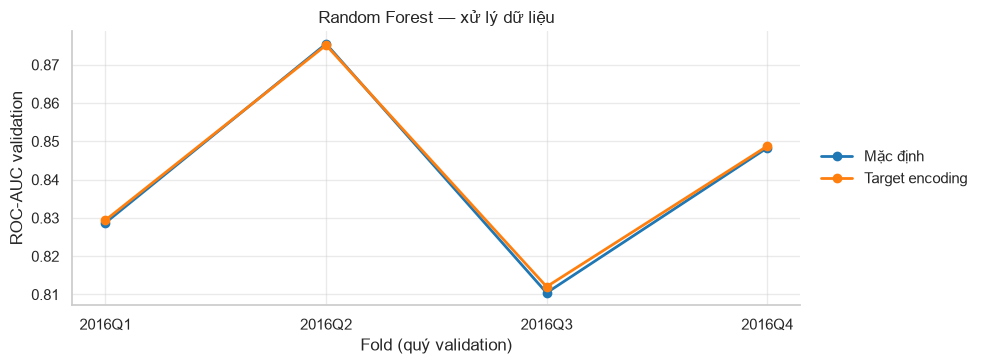

Chọn: Mặc định


In [32]:
rf_variants = {
    "Mặc định": rf_default,
    "Target encoding": experiments.model_spec("Random Forest", "target"),
}
rf_table2, rf_stage2 = run_stage(rf_variants, "Random Forest — xử lý dữ liệu", reuse=rf_stage1)
RF_PREP = experiments.pick_simplest(rf_table2)  # có thể gán tay một nhãn trong bảng
rf_prep = rf_variants[RF_PREP]
rf_progress["2. Xử lý dữ liệu"] = rf_stage2[RF_PREP]
print(f"Chọn: {RF_PREP}")

## 6.3 Trọng số theo thời gian

Hành vi hủy thay đổi theo thời gian (notebook 01 mục 3), nên lượt đặt gần đây được coi trọng
hơn (weighted sampling): trọng số giảm một nửa sau mỗi `half_life_days` ngày tính ngược từ ngày
đến mới nhất của phần train. Trong từng fold, mốc "mới nhất" là cuối phần train của fold đó,
nên không dùng thông tin tương lai. Chọn theo cùng quy tắc ("không trọng số" là đơn giản nhất);
có thể gán tay `RF_HALF_LIFE`.

Không trọng số                               ROC-AUC 0.8407 ± 0.0241  (dùng lại)


half-life 365 ngày                           ROC-AUC 0.8433 ± 0.0230  (9s)


half-life 180 ngày                           ROC-AUC 0.8470 ± 0.0194  (9s)


half-life 90 ngày                            ROC-AUC 0.8512 ± 0.0148  (9s)


half-life 45 ngày                            ROC-AUC 0.8549 ± 0.0150  (8s)


,delta_vs_first,cv_roc_auc,cv_roc_auc_std,cv_average_precision,cv_roc_auc_booking,cv_ap_booking,train_roc_auc,overfit_gap,seconds
Không trọng số,0.0000,0.8407,0.0241,0.7999,0.7799,0.5869,0.9849,0.1441,8.6698
half-life 365 ngày,0.0026,0.8433,0.0230,0.8032,0.7830,0.5929,0.9846,0.1413,9.3436
half-life 180 ngày,0.0062,0.8470,0.0194,0.8091,0.7878,0.6035,0.9837,0.1367,9.1890
half-life 90 ngày,0.0105,0.8512,0.0148,0.8154,0.7938,0.6169,0.9802,0.1289,8.7406
half-life 45 ngày,0.0142,0.8549,0.0150,0.8175,0.7956,0.6170,0.9690,0.1141,7.9992


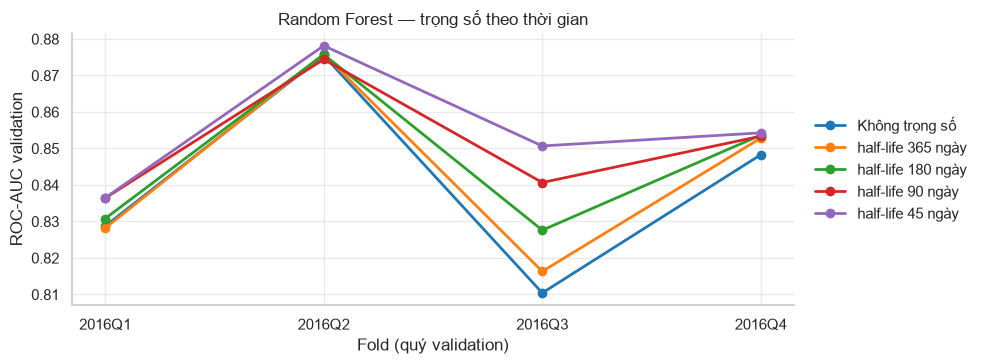

Chọn: half-life 45 ngày


In [33]:
rf_variants = experiments.half_life_variants(rf_prep, HALF_LIVES)
rf_table3, rf_stage3 = run_stage(rf_variants, "Random Forest — trọng số theo thời gian",
                                   reuse={"Không trọng số": rf_stage2[RF_PREP]})
RF_HALF_LIFE = experiments.pick_simplest(rf_table3)  # có thể gán tay một nhãn trong bảng
rf_weighted = rf_variants[RF_HALF_LIFE]
rf_progress["3. Trọng số thời gian"] = rf_stage3[RF_HALF_LIFE]
print(f"Chọn: {RF_HALF_LIFE}")

## 6.4 Tinh chỉnh tham số

Số cây, độ sâu, số mẫu tối thiểu ở lá, tỷ lệ cột xét ở mỗi lần chia và `class_weight`.

`RandomizedSearchCV` trên đúng 4 fold thời gian, chấm bằng ROC-AUC theo dòng; cách xử lý dữ
liệu và trọng số giữ như các bước trước. Bảng hiện 8 cấu hình tốt nhất.

In [34]:
RF_SPACE = {"n_estimators": [200, 300], "max_depth": [None, 16, 24, 32], "min_samples_leaf": [1, 3, 5, 10],
             "max_features": ["sqrt", 0.2, 0.35], "class_weight": [None, "balanced_subsample"]}
RF_N_ITER = 10
rf_tuned = run_tuning(rf_weighted, RF_SPACE, RF_N_ITER)
print(json.dumps(rf_tuned, ensure_ascii=False))

10 cấu hình trong 101s. Tốt nhất: ROC-AUC 0.8554 ± 0.0152


,n_estimators,min_samples_leaf,max_features,max_depth,class_weight,mean_test_score,std_test_score,mean_fit_time,rank_test_score
0,300,10,0.2000,None,NaN,0.8554,0.0152,31.6292,1
1,200,5,sqrt,32,NaN,0.8538,0.0162,12.3748,2
2,300,10,0.3500,16,balanced_subsample,0.8512,0.0173,44.7642,3
3,300,5,0.3500,16,NaN,0.8509,0.0139,45.7107,4
4,200,1,0.3500,16,balanced_subsample,0.8506,0.0148,31.8814,5
5,200,3,0.3500,None,NaN,0.8490,0.0137,35.1283,6
6,300,1,0.2000,32,balanced_subsample,0.8488,0.0184,37.4894,7
7,300,1,0.2000,None,NaN,0.8479,0.0149,31.0099,8


{"name": "Random Forest", "encoding": "onehot", "half_life_days": 45, "booking_weights": false, "pipeline": {}, "params": {"n_estimators": 300, "min_samples_leaf": 10, "max_features": 0.2, "max_depth": null, "class_weight": null}}


## 6.5 Kết quả qua từng giai đoạn

So sánh các giai đoạn trên cùng 4 fold. Cần xem:

- Mỗi bước giúp được bao nhiêu so với độ lệch chuẩn giữa các fold (`cv_roc_auc_std`).
- `cv_roc_auc_booking` / `cv_ap_booking` (mỗi lượt đặt tính một lần): nếu thấp hơn nhiều so với
  cột theo dòng, mô hình đang được lợi nhờ các lượt đặt theo đoàn dễ đoán.
- `overfit_gap` lớn hoặc tăng sau khi tinh chỉnh là dấu hiệu học thuộc phần train.

,delta_vs_first,cv_roc_auc,cv_roc_auc_std,cv_average_precision,cv_roc_auc_booking,cv_ap_booking,train_roc_auc,overfit_gap,seconds
1. Mặc định,0.0000,0.8407,0.0241,0.7999,0.7799,0.5869,0.9849,0.1441,8.6698
2. Xử lý dữ liệu,0.0000,0.8407,0.0241,0.7999,0.7799,0.5869,0.9849,0.1441,8.6698
3. Trọng số thời gian,0.0142,0.8549,0.0150,0.8175,0.7956,0.6170,0.9690,0.1141,7.9992
4. Tinh chỉnh,0.0147,0.8554,0.0152,0.8188,0.7959,0.6187,0.9563,0.1009,9.9331


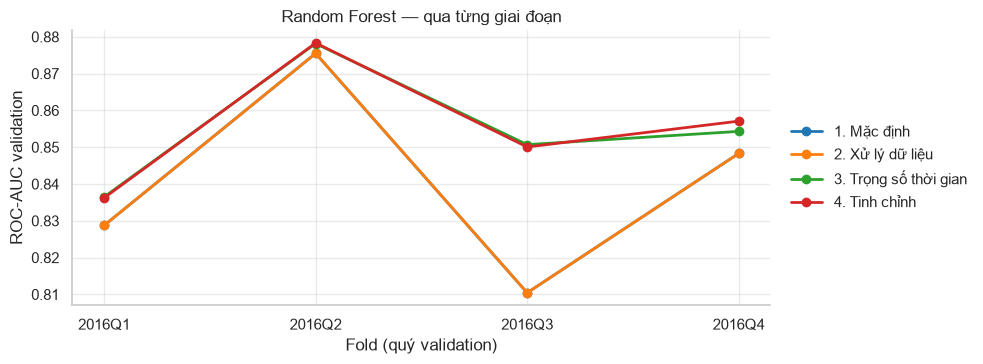

,fold,valid_rows,valid_cancel_rate,roc_auc,average_precision,roc_auc_booking,ap_booking,train_roc_auc,fit_seconds
0,2016Q1,10949,0.3076,0.8362,0.7740,0.7509,0.4622,0.9763,1.1396
1,2016Q2,16190,0.3750,0.8783,0.8624,0.8247,0.6826,0.9617,1.6159
2,2016Q3,15006,0.3559,0.8501,0.8075,0.7978,0.6598,0.9499,2.1407
3,2016Q4,14476,0.3829,0.8571,0.8313,0.8102,0.6702,0.9374,2.8867


In [35]:
rf_final = evaluate_final(rf_tuned, rf_progress, "Random Forest — qua từng giai đoạn")

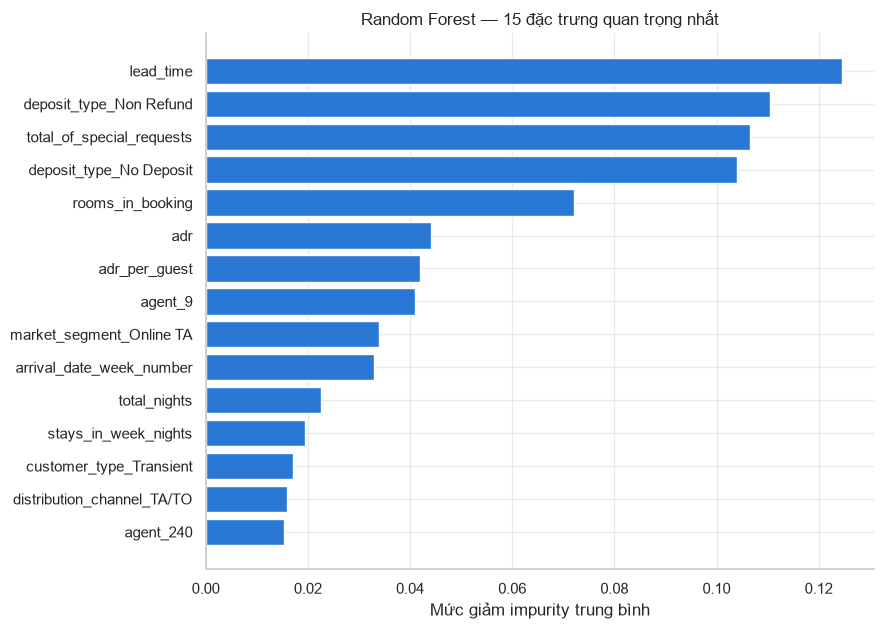

In [36]:
rf_fitted = modeling.build_from_spec(rf_tuned).fit(X_train, y_train)
plot_bar(top_importances(rf_fitted), "Random Forest — 15 đặc trưng quan trọng nhất", "Mức giảm impurity trung bình")

## 6.6 Ghi kết quả

Lưu spec, điểm từng fold và dự đoán OOF vào `models/experiments/` để mục 11 trở đi đọc lại.

In [37]:
log.record("Random Forest", rf_tuned, rf_final,
           notes={"xử lý dữ liệu": RF_PREP, "trọng số thời gian": RF_HALF_LIFE})

WindowsPath('./models/experiments/random_forest.json')

# 7. Hist Gradient Boosting

**Boosting:** các cây nông được thêm nối tiếp, cây sau tập trung sửa lỗi của các cây trước. Bản
histogram của scikit-learn chia giá trị số thành tối đa 255 khoảng nên huấn luyện nhanh, tự xử
lý giá trị thiếu và biến phân loại (native).

Mô hình cây chỉ dùng **thứ tự** giá trị nên không cần chuẩn hóa hay log1p (notebook 01 mục 10)
và tự học được tương tác, nên bước X.2 chỉ so sánh cách mã hóa biến phân loại.

## 7.1 Cấu hình mặc định

Tham số mặc định của dự án (`modeling.make_estimator`), mã hóa one-hot (CatBoost: chuỗi), chưa
đặt trọng số. Bảng từng fold cho biết tỷ lệ hủy của quý validation, ROC-AUC trên phần train và
thời gian fit.

Mặc định                                     ROC-AUC 0.8409 ± 0.0181  (8s)


,delta_vs_first,cv_roc_auc,cv_roc_auc_std,cv_average_precision,cv_roc_auc_booking,cv_ap_booking,train_roc_auc,overfit_gap,seconds
Mặc định,0.0000,0.8409,0.0181,0.8062,0.7793,0.5953,0.9560,0.1150,7.5811


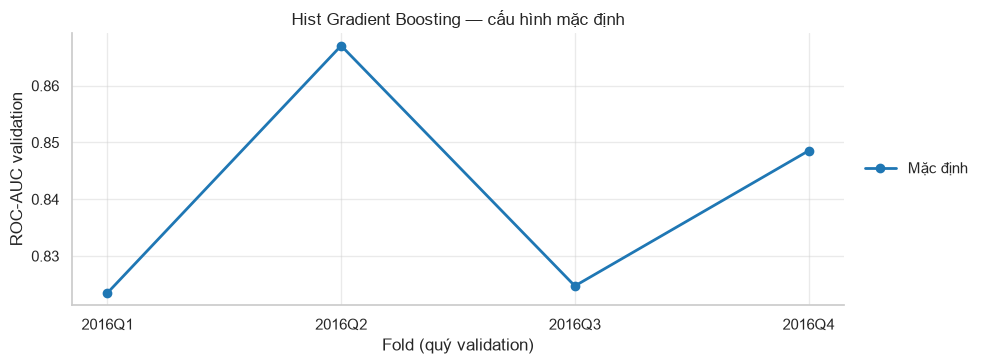

,fold,valid_rows,valid_cancel_rate,roc_auc,average_precision,roc_auc_booking,ap_booking,train_roc_auc,fit_seconds
0,2016Q1,10949,0.3076,0.8235,0.7696,0.7314,0.4473,0.9769,1.9708
1,2016Q2,16190,0.3750,0.8670,0.8545,0.8165,0.6714,0.9616,2.7953
2,2016Q3,15006,0.3559,0.8247,0.7770,0.7668,0.6136,0.9502,3.8190
3,2016Q4,14476,0.3829,0.8485,0.8236,0.8026,0.6491,0.9352,4.3358


In [38]:
hgb_default = experiments.model_spec("Hist Gradient Boosting")
hgb_table1, hgb_stage1 = run_stage({"Mặc định": hgb_default}, "Hist Gradient Boosting — cấu hình mặc định")
display(hgb_stage1["Mặc định"].folds)
hgb_progress = {"1. Mặc định": hgb_stage1["Mặc định"]}

## 7.2 Xử lý dữ liệu theo giả định của mô hình

Ba cách mã hóa biến phân loại: **one-hot**, **native categorical** (mô hình tự chia theo nhóm trên
cột phân loại gốc, nhóm hiếm được gộp) và **target encoding**.

**Quy tắc chọn:** các biến thể xếp từ đơn giản đến phức tạp; chọn biến thể đầu tiên có
ROC-AUC cách biến thể tốt nhất không quá `TOLERANCE`. Có thể gán tay `HGB_PREP` bằng một nhãn
trong bảng.

Mặc định                                     ROC-AUC 0.8409 ± 0.0181  (dùng lại)


Native categorical                           ROC-AUC 0.8290 ± 0.0164  (3s)


Target encoding                              ROC-AUC 0.8310 ± 0.0166  (2s)


,delta_vs_first,cv_roc_auc,cv_roc_auc_std,cv_average_precision,cv_roc_auc_booking,cv_ap_booking,train_roc_auc,overfit_gap,seconds
Mặc định,0.0000,0.8409,0.0181,0.8062,0.7793,0.5953,0.9560,0.1150,7.5811
Native categorical,-0.0120,0.8290,0.0164,0.7952,0.7709,0.5849,0.9604,0.1315,2.9763
Target encoding,-0.0099,0.8310,0.0166,0.8023,0.7732,0.6001,0.9535,0.1224,1.9557


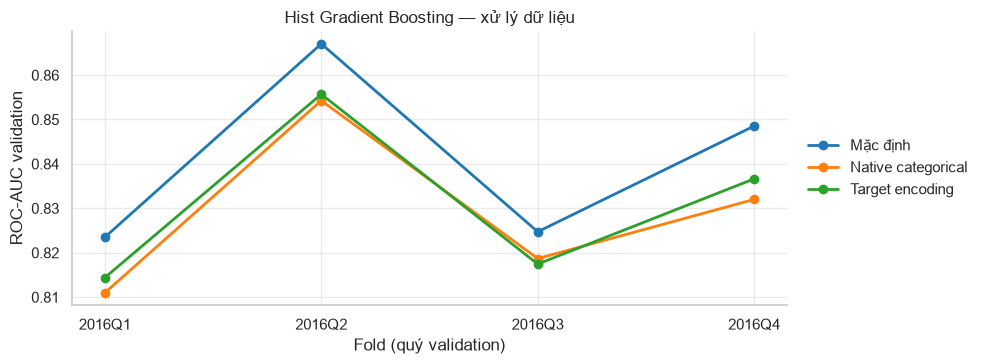

Chọn: Mặc định


In [39]:
hgb_variants = {
    "Mặc định": hgb_default,
    "Native categorical": experiments.model_spec("Hist Gradient Boosting", "native"),
    "Target encoding": experiments.model_spec("Hist Gradient Boosting", "target"),
}
hgb_table2, hgb_stage2 = run_stage(hgb_variants, "Hist Gradient Boosting — xử lý dữ liệu", reuse=hgb_stage1)
HGB_PREP = experiments.pick_simplest(hgb_table2)  # có thể gán tay một nhãn trong bảng
hgb_prep = hgb_variants[HGB_PREP]
hgb_progress["2. Xử lý dữ liệu"] = hgb_stage2[HGB_PREP]
print(f"Chọn: {HGB_PREP}")

## 7.3 Trọng số theo thời gian

Hành vi hủy thay đổi theo thời gian (notebook 01 mục 3), nên lượt đặt gần đây được coi trọng
hơn (weighted sampling): trọng số giảm một nửa sau mỗi `half_life_days` ngày tính ngược từ ngày
đến mới nhất của phần train. Trong từng fold, mốc "mới nhất" là cuối phần train của fold đó,
nên không dùng thông tin tương lai. Chọn theo cùng quy tắc ("không trọng số" là đơn giản nhất);
có thể gán tay `HGB_HALF_LIFE`.

Không trọng số                               ROC-AUC 0.8409 ± 0.0181  (dùng lại)


half-life 365 ngày                           ROC-AUC 0.8414 ± 0.0174  (6s)


half-life 180 ngày                           ROC-AUC 0.8435 ± 0.0180  (6s)


half-life 90 ngày                            ROC-AUC 0.8504 ± 0.0142  (7s)


half-life 45 ngày                            ROC-AUC 0.8501 ± 0.0146  (7s)


,delta_vs_first,cv_roc_auc,cv_roc_auc_std,cv_average_precision,cv_roc_auc_booking,cv_ap_booking,train_roc_auc,overfit_gap,seconds
Không trọng số,0.0000,0.8409,0.0181,0.8062,0.7793,0.5953,0.9560,0.1150,7.5811
half-life 365 ngày,0.0004,0.8414,0.0174,0.8059,0.7835,0.6020,0.9555,0.1141,5.6754
half-life 180 ngày,0.0026,0.8435,0.0180,0.8090,0.7854,0.6068,0.9546,0.1110,5.8294
half-life 90 ngày,0.0094,0.8504,0.0142,0.8152,0.7931,0.6154,0.9521,0.1017,6.9940
half-life 45 ngày,0.0091,0.8501,0.0146,0.8169,0.7901,0.6145,0.9439,0.0938,6.7017


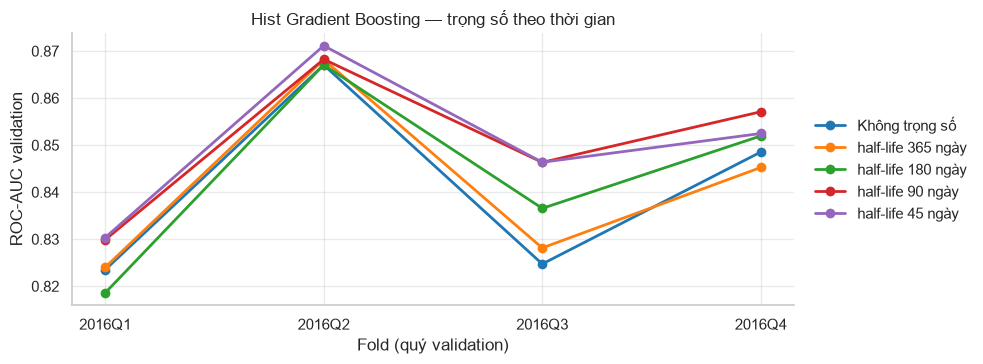

Chọn: half-life 90 ngày


In [40]:
hgb_variants = experiments.half_life_variants(hgb_prep, HALF_LIVES)
hgb_table3, hgb_stage3 = run_stage(hgb_variants, "Hist Gradient Boosting — trọng số theo thời gian",
                                   reuse={"Không trọng số": hgb_stage2[HGB_PREP]})
HGB_HALF_LIFE = experiments.pick_simplest(hgb_table3)  # có thể gán tay một nhãn trong bảng
hgb_weighted = hgb_variants[HGB_HALF_LIFE]
hgb_progress["3. Trọng số thời gian"] = hgb_stage3[HGB_HALF_LIFE]
print(f"Chọn: {HGB_HALF_LIFE}")

## 7.4 Tinh chỉnh tham số

Tốc độ học và số vòng boosting (học chậm hơn cần nhiều cây hơn), số lá mỗi cây, số mẫu tối thiểu
ở lá, regularization L2 và `class_weight`.

`RandomizedSearchCV` trên đúng 4 fold thời gian, chấm bằng ROC-AUC theo dòng; cách xử lý dữ
liệu và trọng số giữ như các bước trước. Bảng hiện 8 cấu hình tốt nhất.

In [41]:
HGB_SPACE = {"learning_rate": [0.03, 0.05, 0.08, 0.1], "max_iter": [200, 400, 700], "max_leaf_nodes": [15, 31, 63],
              "min_samples_leaf": [20, 50, 100], "l2_regularization": [0.0, 0.1, 1.0],
              "class_weight": [None, "balanced"]}
HGB_N_ITER = 20
hgb_tuned = run_tuning(hgb_weighted, HGB_SPACE, HGB_N_ITER)
print(json.dumps(hgb_tuned, ensure_ascii=False))

20 cấu hình trong 171s. Tốt nhất: ROC-AUC 0.8528 ± 0.0159


,min_samples_leaf,max_leaf_nodes,max_iter,learning_rate,l2_regularization,class_weight,mean_test_score,std_test_score,mean_fit_time,rank_test_score
0,50,31,200,0.0300,1.0000,NaN,0.8528,0.0159,29.6958,1
1,50,15,400,0.0300,0.0000,NaN,0.8516,0.0108,25.5848,2
2,20,15,200,0.1000,0.0000,NaN,0.8514,0.0089,14.4882,3
3,50,31,200,0.0500,1.0000,NaN,0.8511,0.0136,21.5699,4
4,20,15,700,0.0800,0.0000,NaN,0.8504,0.0101,39.5187,5
5,100,15,400,0.0500,0.0000,balanced,0.8501,0.0140,28.3430,6
6,50,31,200,0.0500,0.1000,balanced,0.8482,0.0148,20.9339,7
7,50,31,200,0.0800,1.0000,balanced,0.8466,0.0141,20.4445,8


{"name": "Hist Gradient Boosting", "encoding": "onehot", "half_life_days": 90, "booking_weights": false, "pipeline": {}, "params": {"min_samples_leaf": 50, "max_leaf_nodes": 31, "max_iter": 200, "learning_rate": 0.03, "l2_regularization": 1.0, "class_weight": null}}


## 7.5 Kết quả qua từng giai đoạn

So sánh các giai đoạn trên cùng 4 fold. Cần xem:

- Mỗi bước giúp được bao nhiêu so với độ lệch chuẩn giữa các fold (`cv_roc_auc_std`).
- `cv_roc_auc_booking` / `cv_ap_booking` (mỗi lượt đặt tính một lần): nếu thấp hơn nhiều so với
  cột theo dòng, mô hình đang được lợi nhờ các lượt đặt theo đoàn dễ đoán.
- `overfit_gap` lớn hoặc tăng sau khi tinh chỉnh là dấu hiệu học thuộc phần train.

,delta_vs_first,cv_roc_auc,cv_roc_auc_std,cv_average_precision,cv_roc_auc_booking,cv_ap_booking,train_roc_auc,overfit_gap,seconds
1. Mặc định,0.0000,0.8409,0.0181,0.8062,0.7793,0.5953,0.9560,0.1150,7.5811
2. Xử lý dữ liệu,0.0000,0.8409,0.0181,0.8062,0.7793,0.5953,0.9560,0.1150,7.5811
3. Trọng số thời gian,0.0094,0.8504,0.0142,0.8152,0.7931,0.6154,0.9521,0.1017,6.9940
4. Tinh chỉnh,0.0119,0.8528,0.0159,0.8185,0.7944,0.6191,0.9411,0.0882,13.2075


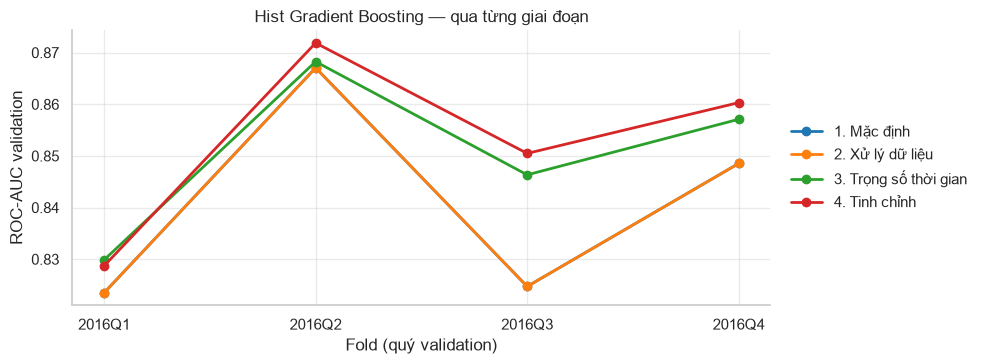

,fold,valid_rows,valid_cancel_rate,roc_auc,average_precision,roc_auc_booking,ap_booking,train_roc_auc,fit_seconds
0,2016Q1,10949,0.3076,0.8287,0.7734,0.7344,0.4552,0.9660,5.4907
1,2016Q2,16190,0.3750,0.8719,0.8583,0.8256,0.6834,0.9472,7.0039
2,2016Q3,15006,0.3559,0.8505,0.8079,0.8003,0.6643,0.9338,8.8258
3,2016Q4,14476,0.3829,0.8603,0.8345,0.8173,0.6735,0.9174,9.7628


In [42]:
hgb_final = evaluate_final(hgb_tuned, hgb_progress, "Hist Gradient Boosting — qua từng giai đoạn")

HistGradientBoosting không có độ quan trọng đặc trưng sẵn; xem permutation importance của mô hình
được chọn ở mục 17.

## 7.6 Ghi kết quả

Lưu spec, điểm từng fold và dự đoán OOF vào `models/experiments/` để mục 11 trở đi đọc lại.

In [43]:
log.record("Hist Gradient Boosting", hgb_tuned, hgb_final,
           notes={"xử lý dữ liệu": HGB_PREP, "trọng số thời gian": HGB_HALF_LIFE})

WindowsPath('./models/experiments/hist_gradient_boosting.json')

# 8. LightGBM

**Boosting** (LightGBM): cây phát triển theo lá (leaf-wise) nên với cùng số lá có thể sâu hơn và
khớp dữ liệu nhanh hơn; cần `min_child_samples` và regularization để không overfit.

Mô hình cây chỉ dùng **thứ tự** giá trị nên không cần chuẩn hóa hay log1p (notebook 01 mục 10)
và tự học được tương tác, nên bước X.2 chỉ so sánh cách mã hóa biến phân loại.

## 8.1 Cấu hình mặc định

Tham số mặc định của dự án (`modeling.make_estimator`), mã hóa one-hot (CatBoost: chuỗi), chưa
đặt trọng số. Bảng từng fold cho biết tỷ lệ hủy của quý validation, ROC-AUC trên phần train và
thời gian fit.

Mặc định                                     ROC-AUC 0.8356 ± 0.0165  (6s)


,delta_vs_first,cv_roc_auc,cv_roc_auc_std,cv_average_precision,cv_roc_auc_booking,cv_ap_booking,train_roc_auc,overfit_gap,seconds
Mặc định,0.0000,0.8356,0.0165,0.7990,0.7772,0.5883,0.9638,0.1282,6.4845


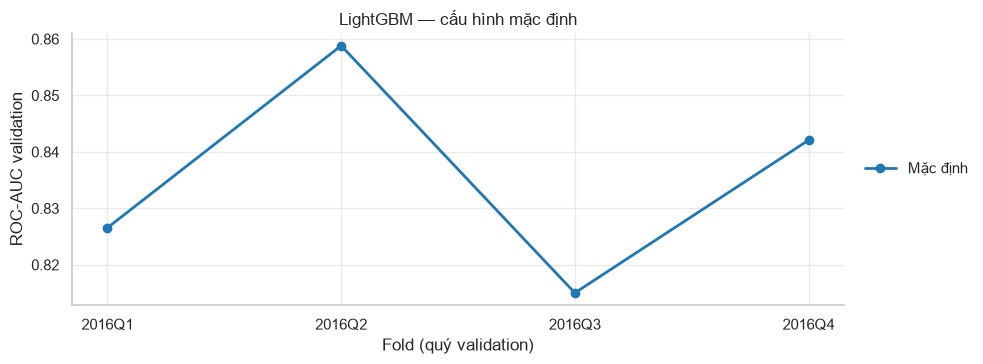

,fold,valid_rows,valid_cancel_rate,roc_auc,average_precision,roc_auc_booking,ap_booking,train_roc_auc,fit_seconds
0,2016Q1,10949,0.3076,0.8265,0.7682,0.7401,0.4540,0.9832,1.1874
1,2016Q2,16190,0.3750,0.8588,0.8492,0.8138,0.6713,0.9702,1.0794
2,2016Q3,15006,0.3559,0.8150,0.7578,0.7532,0.5772,0.9585,1.2066
3,2016Q4,14476,0.3829,0.8421,0.8209,0.8019,0.6508,0.9432,1.3779


In [44]:
lgbm_default = experiments.model_spec("LightGBM")
lgbm_table1, lgbm_stage1 = run_stage({"Mặc định": lgbm_default}, "LightGBM — cấu hình mặc định")
display(lgbm_stage1["Mặc định"].folds)
lgbm_progress = {"1. Mặc định": lgbm_stage1["Mặc định"]}

## 8.2 Xử lý dữ liệu theo giả định của mô hình

Ba cách mã hóa biến phân loại: **one-hot**, **native categorical** (mô hình tự chia theo nhóm trên
cột phân loại gốc, nhóm hiếm được gộp) và **target encoding**.

**Quy tắc chọn:** các biến thể xếp từ đơn giản đến phức tạp; chọn biến thể đầu tiên có
ROC-AUC cách biến thể tốt nhất không quá `TOLERANCE`. Có thể gán tay `LGBM_PREP` bằng một nhãn
trong bảng.

Mặc định                                     ROC-AUC 0.8356 ± 0.0165  (dùng lại)


Native categorical                           ROC-AUC 0.8352 ± 0.0132  (6s)


Target encoding                              ROC-AUC 0.8281 ± 0.0189  (5s)


,delta_vs_first,cv_roc_auc,cv_roc_auc_std,cv_average_precision,cv_roc_auc_booking,cv_ap_booking,train_roc_auc,overfit_gap,seconds
Mặc định,0.0000,0.8356,0.0165,0.7990,0.7772,0.5883,0.9638,0.1282,6.4845
Native categorical,-0.0004,0.8352,0.0132,0.8019,0.7771,0.5955,0.9677,0.1325,6.1833
Target encoding,-0.0076,0.8281,0.0189,0.7990,0.7678,0.5915,0.9604,0.1323,5.2603


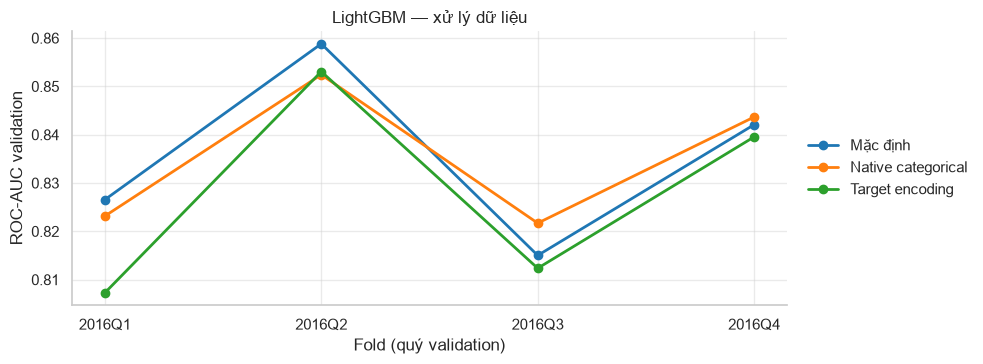

Chọn: Mặc định


In [45]:
lgbm_variants = {
    "Mặc định": lgbm_default,
    "Native categorical": experiments.model_spec("LightGBM", "native"),
    "Target encoding": experiments.model_spec("LightGBM", "target"),
}
lgbm_table2, lgbm_stage2 = run_stage(lgbm_variants, "LightGBM — xử lý dữ liệu", reuse=lgbm_stage1)
LGBM_PREP = experiments.pick_simplest(lgbm_table2)  # có thể gán tay một nhãn trong bảng
lgbm_prep = lgbm_variants[LGBM_PREP]
lgbm_progress["2. Xử lý dữ liệu"] = lgbm_stage2[LGBM_PREP]
print(f"Chọn: {LGBM_PREP}")

## 8.3 Trọng số theo thời gian

Hành vi hủy thay đổi theo thời gian (notebook 01 mục 3), nên lượt đặt gần đây được coi trọng
hơn (weighted sampling): trọng số giảm một nửa sau mỗi `half_life_days` ngày tính ngược từ ngày
đến mới nhất của phần train. Trong từng fold, mốc "mới nhất" là cuối phần train của fold đó,
nên không dùng thông tin tương lai. Chọn theo cùng quy tắc ("không trọng số" là đơn giản nhất);
có thể gán tay `LGBM_HALF_LIFE`.

Không trọng số                               ROC-AUC 0.8356 ± 0.0165  (dùng lại)


half-life 365 ngày                           ROC-AUC 0.8407 ± 0.0142  (8s)


half-life 180 ngày                           ROC-AUC 0.8429 ± 0.0134  (7s)


half-life 90 ngày                            ROC-AUC 0.8512 ± 0.0119  (6s)


half-life 45 ngày                            ROC-AUC 0.8511 ± 0.0097  (6s)


,delta_vs_first,cv_roc_auc,cv_roc_auc_std,cv_average_precision,cv_roc_auc_booking,cv_ap_booking,train_roc_auc,overfit_gap,seconds
Không trọng số,0.0000,0.8356,0.0165,0.7990,0.7772,0.5883,0.9638,0.1282,6.4845
half-life 365 ngày,0.0051,0.8407,0.0142,0.8060,0.7836,0.6013,0.9632,0.1225,8.0739
half-life 180 ngày,0.0073,0.8429,0.0134,0.8096,0.7859,0.6065,0.9625,0.1195,7.3109
half-life 90 ngày,0.0156,0.8512,0.0119,0.8173,0.7943,0.6176,0.9598,0.1086,6.3385
half-life 45 ngày,0.0155,0.8511,0.0097,0.8187,0.7945,0.6193,0.9519,0.1008,6.4324


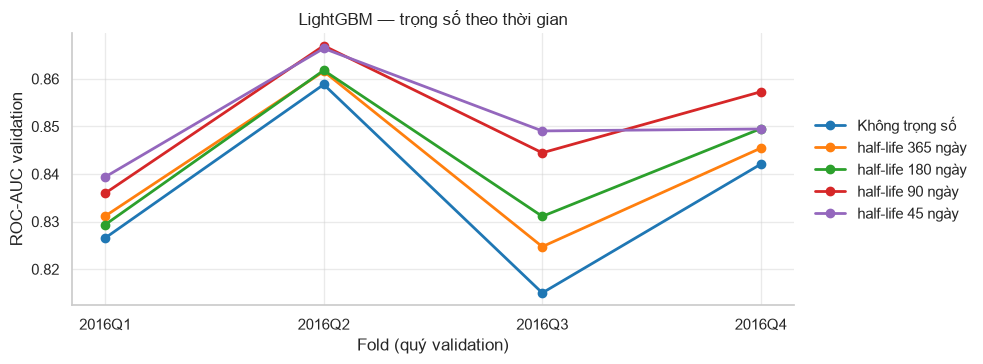

Chọn: half-life 90 ngày


In [46]:
lgbm_variants = experiments.half_life_variants(lgbm_prep, HALF_LIVES)
lgbm_table3, lgbm_stage3 = run_stage(lgbm_variants, "LightGBM — trọng số theo thời gian",
                                   reuse={"Không trọng số": lgbm_stage2[LGBM_PREP]})
LGBM_HALF_LIFE = experiments.pick_simplest(lgbm_table3)  # có thể gán tay một nhãn trong bảng
lgbm_weighted = lgbm_variants[LGBM_HALF_LIFE]
lgbm_progress["3. Trọng số thời gian"] = lgbm_stage3[LGBM_HALF_LIFE]
print(f"Chọn: {LGBM_HALF_LIFE}")

## 8.4 Tinh chỉnh tham số

Số cây và tốc độ học, số lá, số mẫu tối thiểu ở lá, lấy mẫu dòng / cột cho mỗi cây (thêm tính
ngẫu nhiên như bagging), regularization L2 và `class_weight`.

`RandomizedSearchCV` trên đúng 4 fold thời gian, chấm bằng ROC-AUC theo dòng; cách xử lý dữ
liệu và trọng số giữ như các bước trước. Bảng hiện 8 cấu hình tốt nhất.

In [47]:
LGBM_SPACE = {"n_estimators": [200, 400, 700, 1000], "learning_rate": [0.02, 0.03, 0.05, 0.1],
               "num_leaves": [15, 31, 63, 127], "min_child_samples": [20, 50, 100, 200],
               "subsample": [0.7, 0.85, 1.0], "subsample_freq": [1], "colsample_bytree": [0.5, 0.7, 1.0],
               "reg_lambda": [0.0, 1.0, 5.0, 10.0], "class_weight": [None, "balanced"]}
LGBM_N_ITER = 25
lgbm_tuned = run_tuning(lgbm_weighted, LGBM_SPACE, LGBM_N_ITER)
print(json.dumps(lgbm_tuned, ensure_ascii=False))

25 cấu hình trong 50s. Tốt nhất: ROC-AUC 0.8534 ± 0.0143


,subsample_freq,subsample,reg_lambda,num_leaves,n_estimators,min_child_samples,learning_rate,colsample_bytree,class_weight,mean_test_score,std_test_score,mean_fit_time,rank_test_score
0,1,0.7000,1.0000,15,400,100,0.0200,1.0000,balanced,0.8534,0.0143,3.8493,1
1,1,0.8500,0.0000,15,200,20,0.0300,0.5000,NaN,0.8529,0.0113,3.0833,2
2,1,0.7000,0.0000,31,400,50,0.0200,1.0000,NaN,0.8508,0.0181,4.4086,3
3,1,1.0000,1.0000,15,1000,20,0.0500,0.5000,NaN,0.8496,0.0104,7.0273,4
4,1,0.8500,10.0000,15,200,200,0.0300,0.7000,NaN,0.8495,0.0174,2.4760,5
5,1,1.0000,10.0000,15,400,100,0.0500,0.7000,NaN,0.8488,0.0160,3.1288,6
6,1,1.0000,10.0000,31,200,200,0.0500,0.7000,balanced,0.8470,0.0152,3.2002,7
7,1,1.0000,0.0000,31,200,20,0.1000,0.7000,NaN,0.8469,0.0112,2.6511,8


{"name": "LightGBM", "encoding": "onehot", "half_life_days": 90, "booking_weights": false, "pipeline": {}, "params": {"subsample_freq": 1, "subsample": 0.7, "reg_lambda": 1.0, "num_leaves": 15, "n_estimators": 400, "min_child_samples": 100, "learning_rate": 0.02, "colsample_bytree": 1.0, "class_weight": "balanced"}}


## 8.5 Kết quả qua từng giai đoạn

So sánh các giai đoạn trên cùng 4 fold. Cần xem:

- Mỗi bước giúp được bao nhiêu so với độ lệch chuẩn giữa các fold (`cv_roc_auc_std`).
- `cv_roc_auc_booking` / `cv_ap_booking` (mỗi lượt đặt tính một lần): nếu thấp hơn nhiều so với
  cột theo dòng, mô hình đang được lợi nhờ các lượt đặt theo đoàn dễ đoán.
- `overfit_gap` lớn hoặc tăng sau khi tinh chỉnh là dấu hiệu học thuộc phần train.

,delta_vs_first,cv_roc_auc,cv_roc_auc_std,cv_average_precision,cv_roc_auc_booking,cv_ap_booking,train_roc_auc,overfit_gap,seconds
1. Mặc định,0.0000,0.8356,0.0165,0.7990,0.7772,0.5883,0.9638,0.1282,6.4845
2. Xử lý dữ liệu,0.0000,0.8356,0.0165,0.7990,0.7772,0.5883,0.9638,0.1282,6.4845
3. Trọng số thời gian,0.0156,0.8512,0.0119,0.8173,0.7943,0.6176,0.9598,0.1086,6.3385
4. Tinh chỉnh,0.0178,0.8534,0.0143,0.8196,0.7960,0.6215,0.9329,0.0795,5.6984


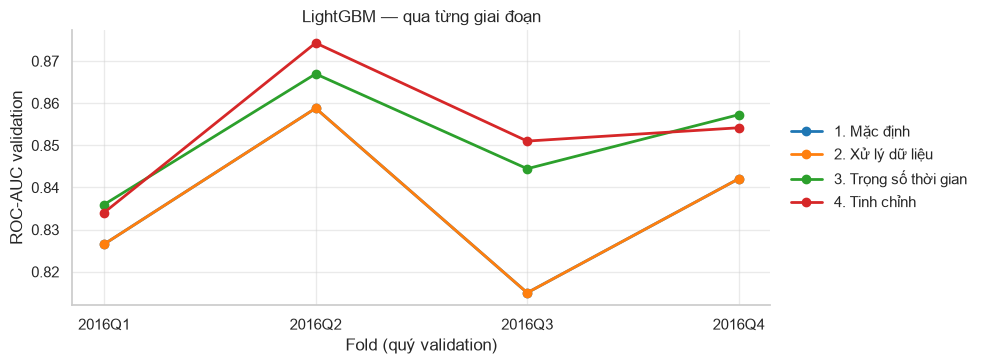

,fold,valid_rows,valid_cancel_rate,roc_auc,average_precision,roc_auc_booking,ap_booking,train_roc_auc,fit_seconds
0,2016Q1,10949,0.3076,0.8341,0.7807,0.7426,0.4716,0.9578,0.6853
1,2016Q2,16190,0.3750,0.8743,0.8597,0.8250,0.6824,0.9387,0.8540
2,2016Q3,15006,0.3559,0.8510,0.8100,0.8016,0.6671,0.9257,1.1114
3,2016Q4,14476,0.3829,0.8542,0.8281,0.8150,0.6648,0.9092,1.3336


In [48]:
lgbm_final = evaluate_final(lgbm_tuned, lgbm_progress, "LightGBM — qua từng giai đoạn")

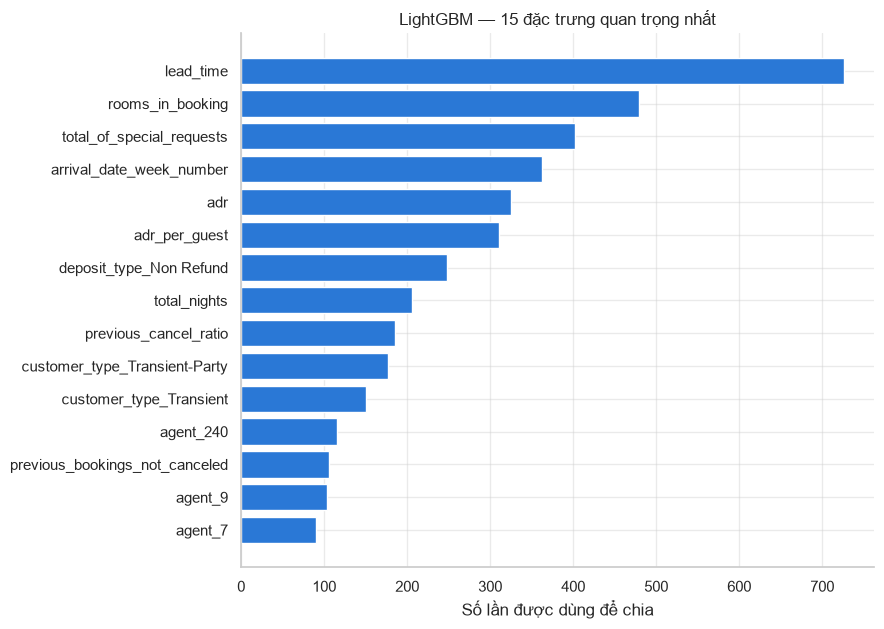

In [49]:
lgbm_fitted = modeling.build_from_spec(lgbm_tuned).fit(X_train, y_train)
plot_bar(top_importances(lgbm_fitted), "LightGBM — 15 đặc trưng quan trọng nhất", "Số lần được dùng để chia")

## 8.6 Ghi kết quả

Lưu spec, điểm từng fold và dự đoán OOF vào `models/experiments/` để mục 11 trở đi đọc lại.

In [50]:
log.record("LightGBM", lgbm_tuned, lgbm_final,
           notes={"xử lý dữ liệu": LGBM_PREP, "trọng số thời gian": LGBM_HALF_LIFE})

WindowsPath('./models/experiments/lightgbm.json')

# 9. XGBoost

**Boosting** (XGBoost): cây phát triển theo độ sâu (level-wise) với regularization L2 trên trọng
số lá; `subsample` và `colsample_bytree` thêm tính ngẫu nhiên như bagging.

Mô hình cây chỉ dùng **thứ tự** giá trị nên không cần chuẩn hóa hay log1p (notebook 01 mục 10)
và tự học được tương tác, nên bước X.2 chỉ so sánh cách mã hóa biến phân loại.

## 9.1 Cấu hình mặc định

Tham số mặc định của dự án (`modeling.make_estimator`), mã hóa one-hot (CatBoost: chuỗi), chưa
đặt trọng số. Bảng từng fold cho biết tỷ lệ hủy của quý validation, ROC-AUC trên phần train và
thời gian fit.

Mặc định                                     ROC-AUC 0.8405 ± 0.0139  (6s)


,delta_vs_first,cv_roc_auc,cv_roc_auc_std,cv_average_precision,cv_roc_auc_booking,cv_ap_booking,train_roc_auc,overfit_gap,seconds
Mặc định,0.0000,0.8405,0.0139,0.8061,0.7809,0.6008,0.9608,0.1202,6.1832


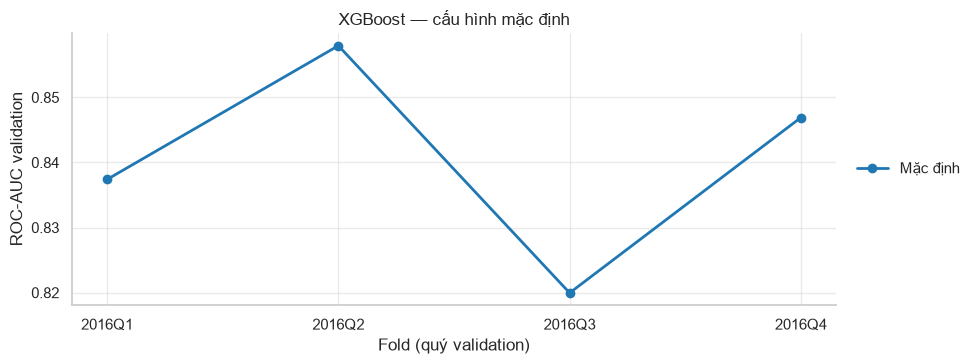

,fold,valid_rows,valid_cancel_rate,roc_auc,average_precision,roc_auc_booking,ap_booking,train_roc_auc,fit_seconds
0,2016Q1,10949,0.3076,0.8374,0.7831,0.7479,0.4707,0.9808,0.9186
1,2016Q2,16190,0.3750,0.8579,0.8444,0.8133,0.6701,0.9670,0.9668
2,2016Q3,15006,0.3559,0.8200,0.7699,0.7571,0.6013,0.9559,1.3839
3,2016Q4,14476,0.3829,0.8469,0.8269,0.8053,0.6612,0.9395,1.6886


In [51]:
xgb_default = experiments.model_spec("XGBoost")
xgb_table1, xgb_stage1 = run_stage({"Mặc định": xgb_default}, "XGBoost — cấu hình mặc định")
display(xgb_stage1["Mặc định"].folds)
xgb_progress = {"1. Mặc định": xgb_stage1["Mặc định"]}

## 9.2 Xử lý dữ liệu theo giả định của mô hình

Ba cách mã hóa biến phân loại: **one-hot**, **native categorical** (mô hình tự chia theo nhóm trên
cột phân loại gốc, nhóm hiếm được gộp) và **target encoding**.

**Quy tắc chọn:** các biến thể xếp từ đơn giản đến phức tạp; chọn biến thể đầu tiên có
ROC-AUC cách biến thể tốt nhất không quá `TOLERANCE`. Có thể gán tay `XGB_PREP` bằng một nhãn
trong bảng.

Mặc định                                     ROC-AUC 0.8405 ± 0.0139  (dùng lại)


Native categorical                           ROC-AUC 0.8263 ± 0.0130  (5s)


Target encoding                              ROC-AUC 0.8237 ± 0.0191  (4s)


,delta_vs_first,cv_roc_auc,cv_roc_auc_std,cv_average_precision,cv_roc_auc_booking,cv_ap_booking,train_roc_auc,overfit_gap,seconds
Mặc định,0.0000,0.8405,0.0139,0.8061,0.7809,0.6008,0.9608,0.1202,6.1832
Native categorical,-0.0142,0.8263,0.0130,0.7914,0.7657,0.5770,0.9763,0.1500,5.0255
Target encoding,-0.0169,0.8237,0.0191,0.7961,0.7615,0.5870,0.9640,0.1403,3.8156


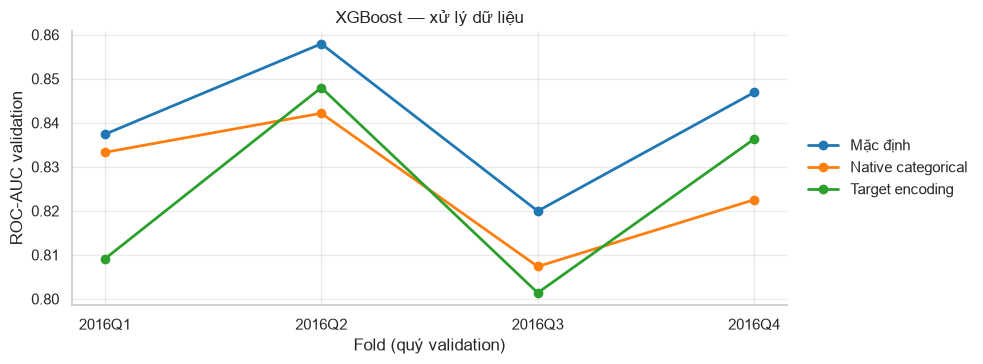

Chọn: Mặc định


In [52]:
xgb_variants = {
    "Mặc định": xgb_default,
    "Native categorical": experiments.model_spec("XGBoost", "native"),
    "Target encoding": experiments.model_spec("XGBoost", "target"),
}
xgb_table2, xgb_stage2 = run_stage(xgb_variants, "XGBoost — xử lý dữ liệu", reuse=xgb_stage1)
XGB_PREP = experiments.pick_simplest(xgb_table2)  # có thể gán tay một nhãn trong bảng
xgb_prep = xgb_variants[XGB_PREP]
xgb_progress["2. Xử lý dữ liệu"] = xgb_stage2[XGB_PREP]
print(f"Chọn: {XGB_PREP}")

## 9.3 Trọng số theo thời gian

Hành vi hủy thay đổi theo thời gian (notebook 01 mục 3), nên lượt đặt gần đây được coi trọng
hơn (weighted sampling): trọng số giảm một nửa sau mỗi `half_life_days` ngày tính ngược từ ngày
đến mới nhất của phần train. Trong từng fold, mốc "mới nhất" là cuối phần train của fold đó,
nên không dùng thông tin tương lai. Chọn theo cùng quy tắc ("không trọng số" là đơn giản nhất);
có thể gán tay `XGB_HALF_LIFE`.

Không trọng số                               ROC-AUC 0.8405 ± 0.0139  (dùng lại)


half-life 365 ngày                           ROC-AUC 0.8467 ± 0.0095  (8s)


half-life 180 ngày                           ROC-AUC 0.8487 ± 0.0081  (7s)


half-life 90 ngày                            ROC-AUC 0.8499 ± 0.0079  (6s)


half-life 45 ngày                            ROC-AUC 0.8459 ± 0.0109  (7s)


,delta_vs_first,cv_roc_auc,cv_roc_auc_std,cv_average_precision,cv_roc_auc_booking,cv_ap_booking,train_roc_auc,overfit_gap,seconds
Không trọng số,0.0000,0.8405,0.0139,0.8061,0.7809,0.6008,0.9608,0.1202,6.1832
half-life 365 ngày,0.0061,0.8467,0.0095,0.8144,0.7902,0.6161,0.9612,0.1145,8.2074
half-life 180 ngày,0.0081,0.8487,0.0081,0.8162,0.7945,0.6211,0.9602,0.1115,6.7048
half-life 90 ngày,0.0094,0.8499,0.0079,0.8174,0.7947,0.6212,0.9585,0.1085,6.4147
half-life 45 ngày,0.0054,0.8459,0.0109,0.8171,0.7877,0.6142,0.9514,0.1055,6.7134


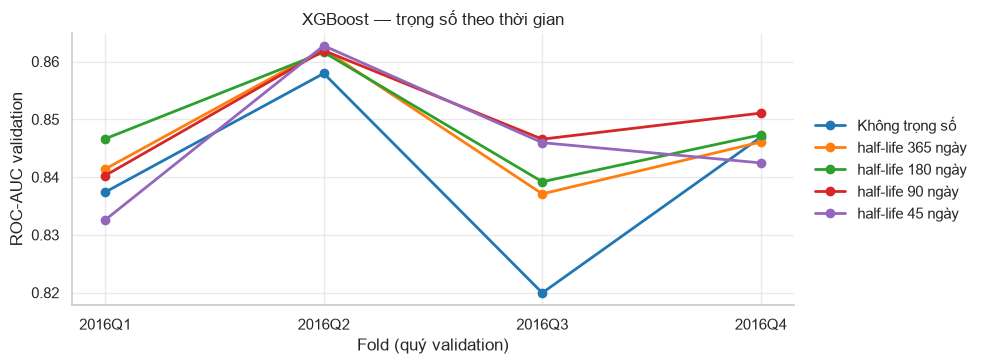

Chọn: half-life 180 ngày


In [53]:
xgb_variants = experiments.half_life_variants(xgb_prep, HALF_LIVES)
xgb_table3, xgb_stage3 = run_stage(xgb_variants, "XGBoost — trọng số theo thời gian",
                                   reuse={"Không trọng số": xgb_stage2[XGB_PREP]})
XGB_HALF_LIFE = experiments.pick_simplest(xgb_table3)  # có thể gán tay một nhãn trong bảng
xgb_weighted = xgb_variants[XGB_HALF_LIFE]
xgb_progress["3. Trọng số thời gian"] = xgb_stage3[XGB_HALF_LIFE]
print(f"Chọn: {XGB_HALF_LIFE}")

## 9.4 Tinh chỉnh tham số

Số cây và tốc độ học, độ sâu, trọng số tối thiểu ở nút con, lấy mẫu dòng / cột, regularization
L2 và `scale_pos_weight` (trọng số của lớp hủy).

`RandomizedSearchCV` trên đúng 4 fold thời gian, chấm bằng ROC-AUC theo dòng; cách xử lý dữ
liệu và trọng số giữ như các bước trước. Bảng hiện 8 cấu hình tốt nhất.

In [54]:
XGB_SPACE = {"n_estimators": [200, 400, 700], "learning_rate": [0.03, 0.05, 0.1], "max_depth": [4, 6, 8],
              "min_child_weight": [1, 5, 10], "subsample": [0.7, 0.85, 1.0], "colsample_bytree": [0.5, 0.7, 1.0],
              "reg_lambda": [1.0, 5.0, 10.0],
              # Tỷ lệ không hủy / hủy trên train khoảng 1,75: tương đương class_weight="balanced".
              "scale_pos_weight": [1.0, 1.75]}
XGB_N_ITER = 25
xgb_tuned = run_tuning(xgb_weighted, XGB_SPACE, XGB_N_ITER)
print(json.dumps(xgb_tuned, ensure_ascii=False))

25 cấu hình trong 64s. Tốt nhất: ROC-AUC 0.8548 ± 0.0089


,subsample,scale_pos_weight,reg_lambda,n_estimators,min_child_weight,max_depth,learning_rate,colsample_bytree,mean_test_score,std_test_score,mean_fit_time,rank_test_score
0,0.8500,1.7500,1.0000,400,10,4,0.0300,0.5000,0.8548,0.0089,9.4178,1
1,0.7000,1.0000,5.0000,700,1,4,0.0500,1.0000,0.8545,0.0086,16.2526,2
2,0.7000,1.7500,1.0000,200,1,4,0.1000,0.7000,0.8536,0.0071,5.8077,3
3,1.0000,1.0000,10.0000,200,1,6,0.0300,1.0000,0.8535,0.0110,6.1636,4
4,0.8500,1.0000,10.0000,200,10,6,0.0500,0.5000,0.8534,0.0132,6.8063,5
5,0.7000,1.7500,5.0000,400,1,6,0.0300,0.5000,0.8533,0.0102,8.9253,6
6,0.8500,1.0000,10.0000,700,5,4,0.0500,0.7000,0.8531,0.0083,13.7419,7
7,0.7000,1.7500,1.0000,200,1,4,0.0300,1.0000,0.8528,0.0088,6.0867,8


{"name": "XGBoost", "encoding": "onehot", "half_life_days": 180, "booking_weights": false, "pipeline": {}, "params": {"subsample": 0.85, "scale_pos_weight": 1.75, "reg_lambda": 1.0, "n_estimators": 400, "min_child_weight": 10, "max_depth": 4, "learning_rate": 0.03, "colsample_bytree": 0.5}}


## 9.5 Kết quả qua từng giai đoạn

So sánh các giai đoạn trên cùng 4 fold. Cần xem:

- Mỗi bước giúp được bao nhiêu so với độ lệch chuẩn giữa các fold (`cv_roc_auc_std`).
- `cv_roc_auc_booking` / `cv_ap_booking` (mỗi lượt đặt tính một lần): nếu thấp hơn nhiều so với
  cột theo dòng, mô hình đang được lợi nhờ các lượt đặt theo đoàn dễ đoán.
- `overfit_gap` lớn hoặc tăng sau khi tinh chỉnh là dấu hiệu học thuộc phần train.

,delta_vs_first,cv_roc_auc,cv_roc_auc_std,cv_average_precision,cv_roc_auc_booking,cv_ap_booking,train_roc_auc,overfit_gap,seconds
1. Mặc định,0.0000,0.8405,0.0139,0.8061,0.7809,0.6008,0.9608,0.1202,6.1832
2. Xử lý dữ liệu,0.0000,0.8405,0.0139,0.8061,0.7809,0.6008,0.9608,0.1202,6.1832
3. Trọng số thời gian,0.0081,0.8487,0.0081,0.8162,0.7945,0.6211,0.9602,0.1115,6.7048
4. Tinh chỉnh,0.0130,0.8536,0.0101,0.8192,0.7966,0.6193,0.9268,0.0732,7.2099


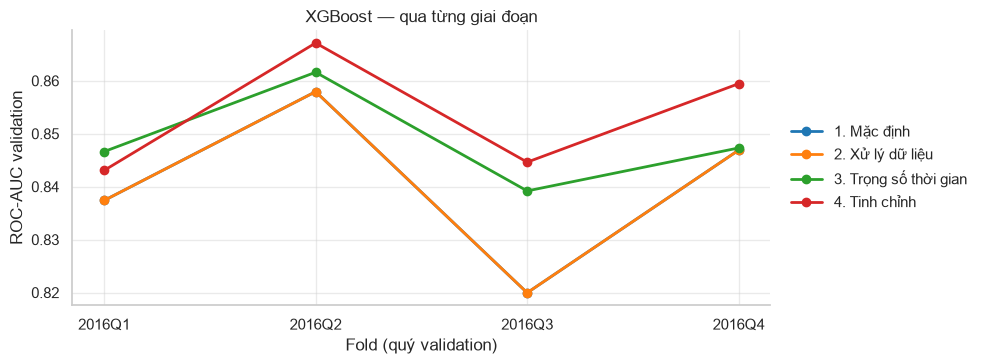

,fold,valid_rows,valid_cancel_rate,roc_auc,average_precision,roc_auc_booking,ap_booking,train_roc_auc,fit_seconds
0,2016Q1,10949,0.3076,0.8431,0.7871,0.7570,0.4719,0.9484,0.9049
1,2016Q2,16190,0.3750,0.8671,0.8530,0.8187,0.6774,0.9320,1.2253
2,2016Q3,15006,0.3559,0.8446,0.8062,0.7960,0.6653,0.9202,1.8585
3,2016Q4,14476,0.3829,0.8595,0.8307,0.8146,0.6626,0.9066,1.9815


In [55]:
xgb_final = evaluate_final(xgb_tuned, xgb_progress, "XGBoost — qua từng giai đoạn")

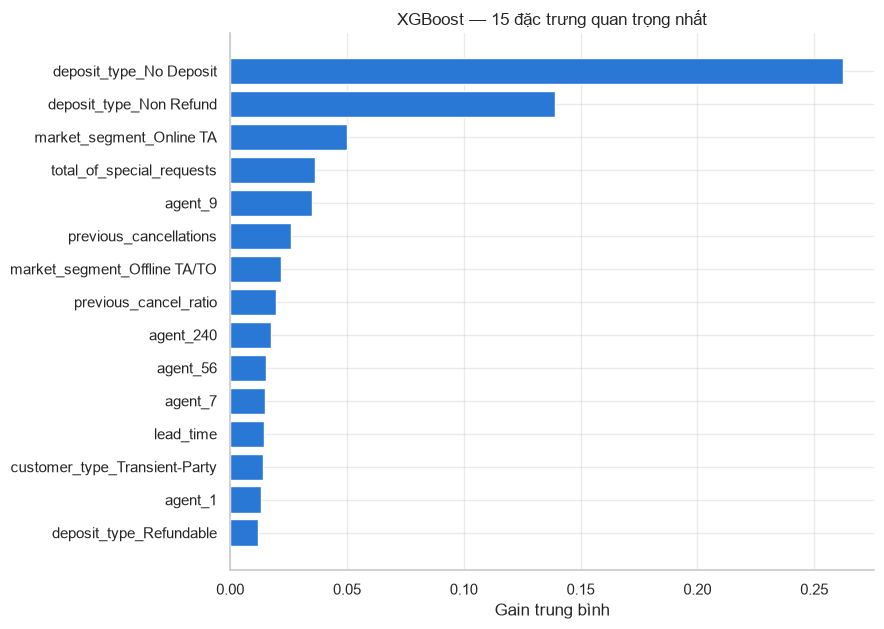

In [56]:
xgb_fitted = modeling.build_from_spec(xgb_tuned).fit(X_train, y_train)
plot_bar(top_importances(xgb_fitted), "XGBoost — 15 đặc trưng quan trọng nhất", "Gain trung bình")

## 9.6 Ghi kết quả

Lưu spec, điểm từng fold và dự đoán OOF vào `models/experiments/` để mục 11 trở đi đọc lại.

In [57]:
log.record("XGBoost", xgb_tuned, xgb_final,
           notes={"xử lý dữ liệu": XGB_PREP, "trọng số thời gian": XGB_HALF_LIFE})

WindowsPath('./models/experiments/xgboost.json')

# 10. CatBoost

**Boosting** (CatBoost): cây đối xứng (mọi nút cùng tầng dùng chung một điều kiện chia) và
*ordered boosting*. Biến phân loại được mã hóa bằng *ordered target statistics*, một dạng target
encoding chỉ dùng các dòng đứng trước nên không rò nhãn. Chậm nhất trong các mô hình boosting ở
đây.

## 10.1 Cấu hình mặc định

Tham số mặc định của dự án (`modeling.make_estimator`), mã hóa one-hot (CatBoost: chuỗi), chưa
đặt trọng số. Bảng từng fold cho biết tỷ lệ hủy của quý validation, ROC-AUC trên phần train và
thời gian fit.

Mặc định                                     ROC-AUC 0.8332 ± 0.0226  (157s)


,delta_vs_first,cv_roc_auc,cv_roc_auc_std,cv_average_precision,cv_roc_auc_booking,cv_ap_booking,train_roc_auc,overfit_gap,seconds
Mặc định,0.0000,0.8332,0.0226,0.7942,0.7750,0.5795,0.9584,0.1253,156.8772


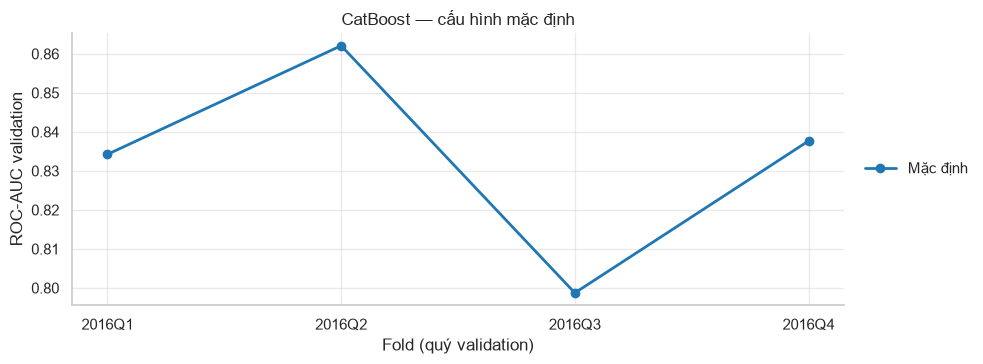

,fold,valid_rows,valid_cancel_rate,roc_auc,average_precision,roc_auc_booking,ap_booking,train_roc_auc,fit_seconds
0,2016Q1,10949,0.3076,0.8342,0.7753,0.7483,0.4654,0.9753,26.2764
1,2016Q2,16190,0.3750,0.8621,0.8468,0.8125,0.6498,0.9627,32.6088
2,2016Q3,15006,0.3559,0.7987,0.7350,0.7296,0.5374,0.9550,45.7927
3,2016Q4,14476,0.3829,0.8377,0.8197,0.8098,0.6655,0.9408,50.6298


In [58]:
cat_default = experiments.model_spec("CatBoost")
cat_table1, cat_stage1 = run_stage({"Mặc định": cat_default}, "CatBoost — cấu hình mặc định")
display(cat_stage1["Mặc định"].folds)
cat_progress = {"1. Mặc định": cat_stage1["Mặc định"]}

## 10.2 Xử lý dữ liệu theo giả định của mô hình

CatBoost tự mã hóa mọi cột phân loại dạng chuỗi bằng ordered target statistics, nên không thử
one-hot hay target encoding bên ngoài. Bỏ qua bước này.

In [59]:
CAT_PREP = "Mặc định"
cat_prep = cat_default
cat_stage2 = cat_stage1

## 10.3 Trọng số theo thời gian

Hành vi hủy thay đổi theo thời gian (notebook 01 mục 3), nên lượt đặt gần đây được coi trọng
hơn (weighted sampling): trọng số giảm một nửa sau mỗi `half_life_days` ngày tính ngược từ ngày
đến mới nhất của phần train. Trong từng fold, mốc "mới nhất" là cuối phần train của fold đó,
nên không dùng thông tin tương lai. Chọn theo cùng quy tắc ("không trọng số" là đơn giản nhất);
có thể gán tay `CAT_HALF_LIFE`.

Không trọng số                               ROC-AUC 0.8332 ± 0.0226  (dùng lại)


half-life 365 ngày                           ROC-AUC 0.8321 ± 0.0191  (166s)


half-life 180 ngày                           ROC-AUC 0.8320 ± 0.0210  (158s)


half-life 90 ngày                            ROC-AUC 0.8438 ± 0.0193  (172s)


half-life 45 ngày                            ROC-AUC 0.8534 ± 0.0154  (229s)


,delta_vs_first,cv_roc_auc,cv_roc_auc_std,cv_average_precision,cv_roc_auc_booking,cv_ap_booking,train_roc_auc,overfit_gap,seconds
Không trọng số,0.0000,0.8332,0.0226,0.7942,0.7750,0.5795,0.9584,0.1253,156.8772
half-life 365 ngày,-0.0011,0.8321,0.0191,0.7940,0.7711,0.5720,0.9583,0.1262,165.5379
half-life 180 ngày,-0.0012,0.8320,0.0210,0.7992,0.7746,0.5914,0.9570,0.1250,157.6907
half-life 90 ngày,0.0106,0.8438,0.0193,0.8118,0.7866,0.6108,0.9535,0.1097,171.6908
half-life 45 ngày,0.0202,0.8534,0.0154,0.8195,0.7984,0.6192,0.9453,0.0919,229.2719


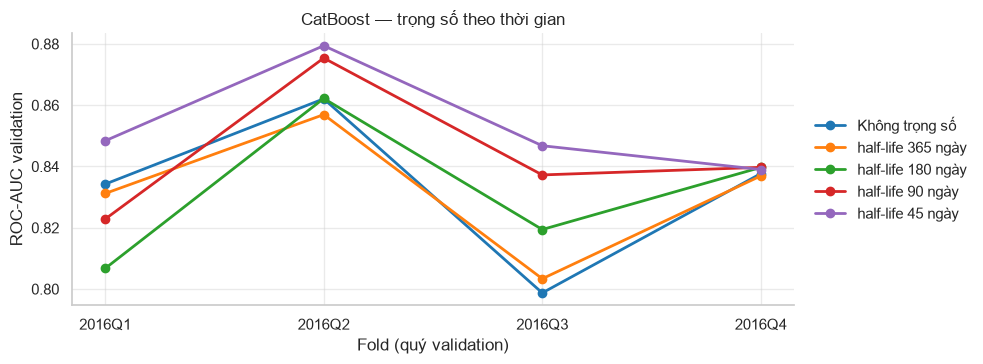

Chọn: half-life 45 ngày


In [60]:
cat_variants = experiments.half_life_variants(cat_prep, HALF_LIVES)
cat_table3, cat_stage3 = run_stage(cat_variants, "CatBoost — trọng số theo thời gian",
                                   reuse={"Không trọng số": cat_stage2[CAT_PREP]})
CAT_HALF_LIFE = experiments.pick_simplest(cat_table3)  # có thể gán tay một nhãn trong bảng
cat_weighted = cat_variants[CAT_HALF_LIFE]
cat_progress["3. Trọng số thời gian"] = cat_stage3[CAT_HALF_LIFE]
print(f"Chọn: {CAT_HALF_LIFE}")

## 10.4 Tinh chỉnh tham số

Số vòng và tốc độ học, độ sâu cây, regularization L2 và trọng số lớp. Chỉ 6 cấu hình vì mỗi lần
fit chậm; tăng `CAT_N_ITER` nếu có thời gian.

`RandomizedSearchCV` trên đúng 4 fold thời gian, chấm bằng ROC-AUC theo dòng; cách xử lý dữ
liệu và trọng số giữ như các bước trước. Bảng hiện 8 cấu hình tốt nhất.

In [61]:
CAT_SPACE = {"iterations": [300, 600, 1000], "learning_rate": [0.03, 0.05, 0.1], "depth": [4, 6, 8],
             "l2_leaf_reg": [1.0, 3.0, 10.0], "auto_class_weights": [None, "Balanced"]}
CAT_N_ITER = 6
cat_tuned = run_tuning(cat_weighted, CAT_SPACE, CAT_N_ITER)
print(json.dumps(cat_tuned, ensure_ascii=False))

6 cấu hình trong 511s. Tốt nhất: ROC-AUC 0.8515 ± 0.0163


,learning_rate,l2_leaf_reg,iterations,depth,auto_class_weights,mean_test_score,std_test_score,mean_fit_time,rank_test_score
0,0.0500,3.0000,600,4,Balanced,0.8515,0.0163,127.7085,1
1,0.0500,1.0000,300,6,Balanced,0.8512,0.0143,95.3463,2
2,0.0500,1.0000,300,8,NaN,0.8496,0.0168,136.2119,3
3,0.1000,1.0000,300,6,NaN,0.8449,0.0224,87.3073,4
4,0.1000,3.0000,1000,6,Balanced,0.8417,0.0123,287.8227,5
5,0.1000,3.0000,1000,8,Balanced,0.8332,0.0131,404.5378,6


{"name": "CatBoost", "encoding": "string", "half_life_days": 45, "booking_weights": false, "pipeline": {}, "params": {"learning_rate": 0.05, "l2_leaf_reg": 3.0, "iterations": 600, "depth": 4, "auto_class_weights": "Balanced"}}


## 10.5 Kết quả qua từng giai đoạn

So sánh các giai đoạn trên cùng 4 fold. Cần xem:

- Mỗi bước giúp được bao nhiêu so với độ lệch chuẩn giữa các fold (`cv_roc_auc_std`).
- `cv_roc_auc_booking` / `cv_ap_booking` (mỗi lượt đặt tính một lần): nếu thấp hơn nhiều so với
  cột theo dòng, mô hình đang được lợi nhờ các lượt đặt theo đoàn dễ đoán.
- `overfit_gap` lớn hoặc tăng sau khi tinh chỉnh là dấu hiệu học thuộc phần train.

,delta_vs_first,cv_roc_auc,cv_roc_auc_std,cv_average_precision,cv_roc_auc_booking,cv_ap_booking,train_roc_auc,overfit_gap,seconds
1. Mặc định,0.0000,0.8332,0.0226,0.7942,0.7750,0.5795,0.9584,0.1253,156.8772
3. Trọng số thời gian,0.0202,0.8534,0.0154,0.8195,0.7984,0.6192,0.9453,0.0919,229.2719
4. Tinh chỉnh,0.0182,0.8514,0.0165,0.8189,0.7960,0.6251,0.9299,0.0785,251.1010


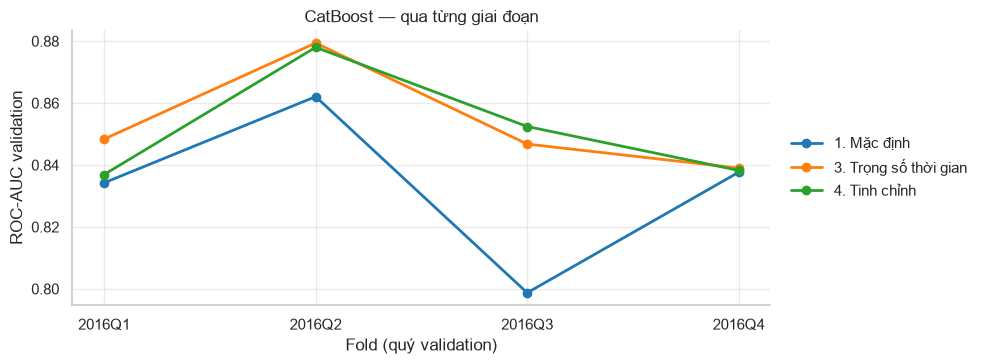

,fold,valid_rows,valid_cancel_rate,roc_auc,average_precision,roc_auc_booking,ap_booking,train_roc_auc,fit_seconds
0,2016Q1,10949,0.3076,0.8369,0.7811,0.7505,0.4813,0.9579,38.3774
1,2016Q2,16190,0.3750,0.8780,0.8621,0.8269,0.6837,0.9345,62.2097
2,2016Q3,15006,0.3559,0.8524,0.8108,0.8031,0.6683,0.9231,74.8658
3,2016Q4,14476,0.3829,0.8382,0.8215,0.8034,0.6672,0.9041,72.9135


In [62]:
cat_final = evaluate_final(cat_tuned, cat_progress, "CatBoost — qua từng giai đoạn")

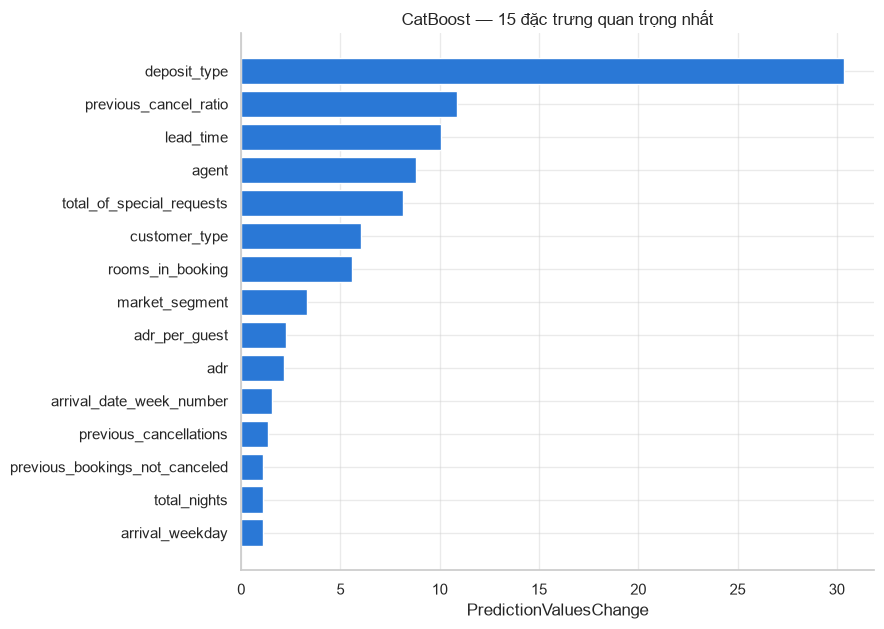

In [63]:
cat_fitted = modeling.build_from_spec(cat_tuned).fit(X_train, y_train)
plot_bar(top_importances(cat_fitted), "CatBoost — 15 đặc trưng quan trọng nhất", "PredictionValuesChange")

## 10.6 Ghi kết quả

Lưu spec, điểm từng fold và dự đoán OOF vào `models/experiments/` để mục 11 trở đi đọc lại.

In [64]:
log.record("CatBoost", cat_tuned, cat_final,
           notes={"xử lý dữ liệu": CAT_PREP, "trọng số thời gian": CAT_HALF_LIFE})

WindowsPath('./models/experiments/catboost.json')

# 11. Tổng hợp các mô hình

Đọc lại kết quả cuối (sau tinh chỉnh) của từng mô hình từ `models/experiments/`. Cột `saved_at`
cho biết kết quả được ghi lúc nào, để tránh so sánh nhầm với kết quả cũ.

In [65]:
records = log.load()
missing = [name for name in MODEL_ORDER if name not in records]
if missing:
    print("Chưa có kết quả của:", ", ".join(missing), "→ chạy section tương ứng trước.")
board = log.leaderboard()
board["saved_at"] = [records[name]["saved_at"] for name in board.index]
display(board[["cv_roc_auc", "cv_roc_auc_std", "cv_average_precision", "cv_roc_auc_booking", "cv_ap_booking",
               "train_roc_auc", "overfit_gap", "seconds", "artifact_mb", "saved_at"]])

,cv_roc_auc,cv_roc_auc_std,cv_average_precision,cv_roc_auc_booking,cv_ap_booking,train_roc_auc,overfit_gap,seconds,artifact_mb,saved_at
Random Forest,0.8554,0.0152,0.8188,0.7959,0.6187,0.9563,0.1009,9.9331,61.5462,2026-10-29T14:51:40+00:00
XGBoost,0.8536,0.0101,0.8192,0.7966,0.6193,0.9268,0.0732,7.2099,0.5833,2026-10-29T14:59:04+00:00
LightGBM,0.8534,0.0143,0.8196,0.7960,0.6215,0.9329,0.0795,5.6984,0.7439,2026-10-29T14:57:07+00:00
Hist Gradient Boosting,0.8528,0.0159,0.8185,0.7944,0.6191,0.9411,0.0882,13.2075,0.7502,2026-10-29T14:55:22+00:00
CatBoost,0.8514,0.0165,0.8189,0.7960,0.6251,0.9299,0.0785,251.1010,1.1657,2026-10-29T15:27:49+00:00
SVM (RBF),0.8474,0.0130,0.8145,0.7901,0.6201,0.9044,0.0570,51.7021,20.3111,2026-10-29T14:48:23+00:00
Logistic Regression,0.8443,0.0098,0.8084,0.7883,0.6105,0.8949,0.0505,7.9134,0.0197,2026-10-29T14:32:51+00:00
Decision Tree,0.8311,0.0232,0.7747,0.7624,0.5576,0.9007,0.0696,4.1152,0.0290,2026-10-29T14:48:53+00:00
KNN,0.7883,0.0554,0.7479,0.7216,0.5281,NaN,NaN,5.4681,16.4251,2026-10-29T14:33:38+00:00
Dummy,0.5000,0.0000,0.3554,0.5000,0.2655,0.5000,0.0000,2.9191,0.0158,2026-10-29T14:31:39+00:00


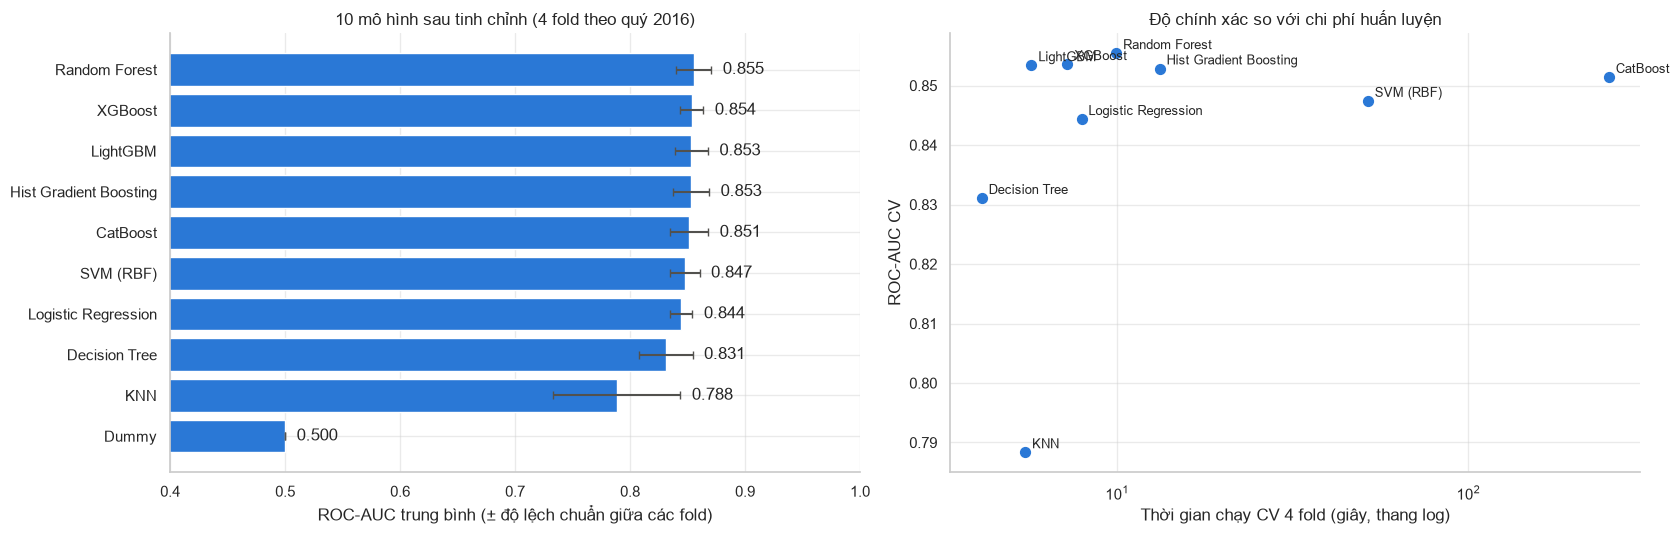

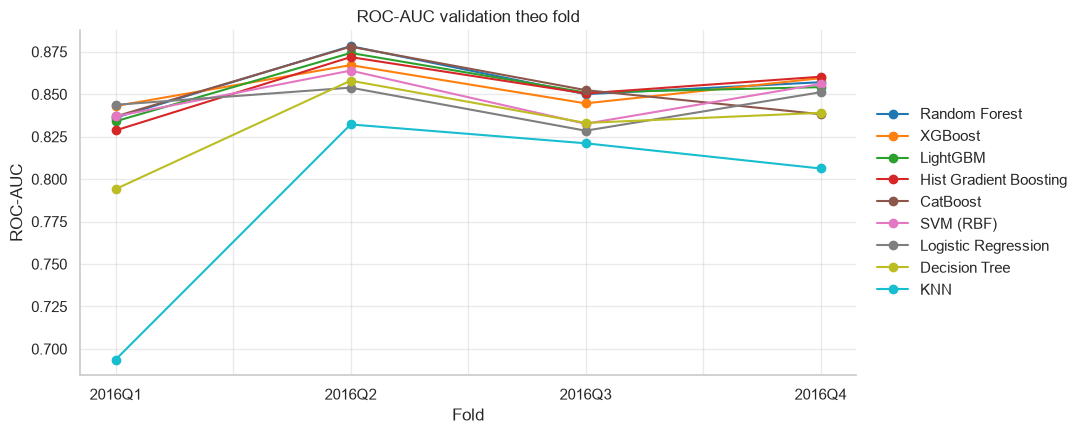

In [66]:
plot_df = board.sort_values("cv_roc_auc")
models_only = board.drop(index="Dummy", errors="ignore")
fig, axes = plt.subplots(1, 2, figsize=(17, 5.5))
axes[0].barh(plot_df.index, plot_df["cv_roc_auc"], xerr=plot_df["cv_roc_auc_std"],
             color=COLORS["primary"], error_kw={"ecolor": COLORS["reference"], "capsize": 3})
for y, (value, std) in enumerate(zip(plot_df["cv_roc_auc"], plot_df["cv_roc_auc_std"])):
    axes[0].text(value + std + 0.01, y, f"{value:.3f}", va="center")
axes[0].set(xlabel="ROC-AUC trung bình (± độ lệch chuẩn giữa các fold)", xlim=(0.4, 1.0),
            title=f"{len(plot_df)} mô hình sau tinh chỉnh (4 fold theo quý 2016)")
axes[1].scatter(models_only["seconds"], models_only["cv_roc_auc"], color=COLORS["primary"], s=50)
for name, row in models_only.iterrows():
    axes[1].annotate(name, (row["seconds"], row["cv_roc_auc"]), xytext=(5, 3), textcoords="offset points", fontsize=9)
axes[1].set(xscale="log", xlabel="Thời gian chạy CV 4 fold (giây, thang log)", ylabel="ROC-AUC CV",
            title="Độ chính xác so với chi phí huấn luyện")
plt.tight_layout()
plt.show()

fold_auc = pd.DataFrame({name: records[name]["folds"].set_index("fold")["roc_auc"] for name in models_only.index})
ax = fold_auc.plot(marker="o", figsize=(11, 4.5), colormap="tab10")
ax.set(title="ROC-AUC validation theo fold", xlabel="Fold", ylabel="ROC-AUC")
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False)
plt.tight_layout()
plt.show()

**Đọc kết quả:**

- Hai mô hình chênh nhau ít hơn độ lệch chuẩn giữa các fold thì chưa phân biệt được; xem thêm
  mô hình nào tốt **ổn định qua cả 4 quý**.
- Biểu đồ thời gian cho thấy đánh đổi giữa độ chính xác và chi phí (*evaluate trade-offs*):
  mô hình rẻ hơn nhiều mà chỉ kém một chút thường đáng chọn hơn.
- So sánh `cv_roc_auc` với `cv_roc_auc_booking`: thứ hạng có giữ nguyên khi mỗi lượt đặt chỉ
  tính một lần không?

# 12. Kết hợp mô hình (ensemble)

Ensemble hiệu quả khi các mô hình thành phần **ít tương quan** (tài liệu, phần Ensembles: ba mô
hình độc lập, mỗi mô hình đúng 70%, bỏ phiếu đúng 78,4%). Mọi phép thử dưới đây chỉ dùng dự đoán
OOF đã lưu, không train lại.

## 12.1 Tương quan giữa dự đoán OOF

Dùng tương quan hạng (Spearman) vì ROC-AUC chỉ phụ thuộc thứ hạng. Các mô hình boosting thường
tương quan rất cao với nhau; mô hình khác họ (LR, SVM, Random Forest) có thể bổ sung thông tin.

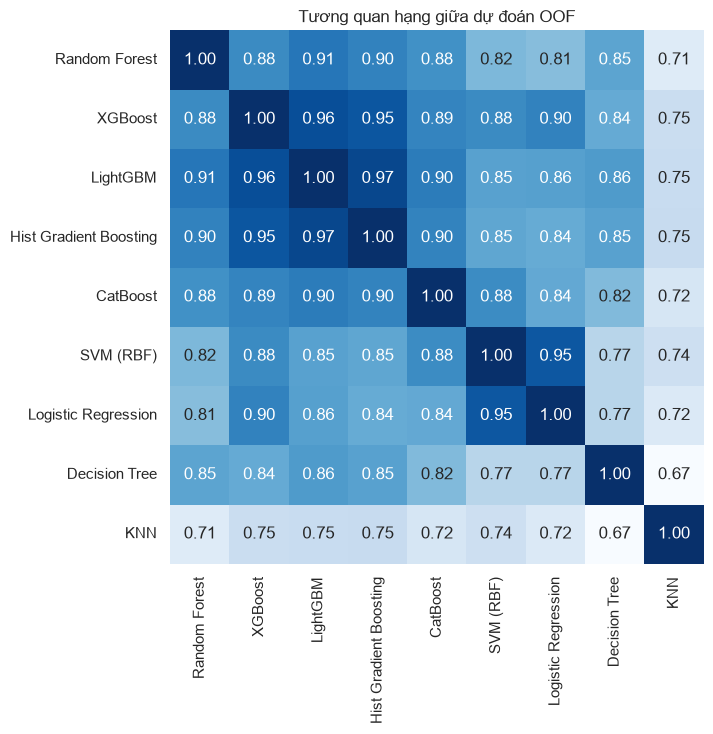

In [67]:
candidate_oof = {name: records[name]["oof"] for name in board.index if name != "Dummy"}
has_oof = ~np.isnan(next(iter(candidate_oof.values())))
oof_corr = pd.DataFrame({name: proba[has_oof] for name, proba in candidate_oof.items()}).corr(method="spearman")
plt.figure(figsize=(9, 7.5))
sns.heatmap(oof_corr, annot=True, fmt=".2f", cmap="Blues", vmin=oof_corr.min().min(), vmax=1, square=True, cbar=False)
plt.title("Tương quan hạng giữa dự đoán OOF")
plt.tight_layout()
plt.show()

## 12.2 Trung bình xác suất (soft voting)

Hai cách chọn thành phần:

- **Top 3 theo CV:** thường là ba mô hình boosting rất giống nhau.
- **Chọn tham lam:** bắt đầu từ mô hình tốt nhất, mỗi bước thêm mô hình làm ROC-AUC của trung
  bình xác suất tăng nhiều nhất, dừng khi mức tăng nhỏ hơn 0,0005. Cách này tự ưu tiên mô hình ít
  tương quan nếu chúng thật sự bổ sung thông tin.

Hai cách cho cùng một tập thành phần thì chỉ giữ một.

In [68]:
greedy_members, greedy_history = experiments.greedy_selection(candidate_oof, y_train, cv_folds)
display(greedy_history)

ensemble_members, seen = {}, set()
for label, members in {"Top 3 theo CV": list(candidate_oof)[:3], "Chọn tham lam": greedy_members}.items():
    if len(members) >= 2 and frozenset(members) not in seen:
        seen.add(frozenset(members))
        ensemble_members[f"Ensemble ({label}): " + " + ".join(members)] = members

ensemble_results = {}
for label, members in ensemble_members.items():
    proba = np.mean([candidate_oof[name] for name in members], axis=0)
    ensemble_results[label] = experiments.CVResult(
        experiments.score_folds(proba, y_train, X_train, cv_folds, FOLD_NAMES), proba,
        sum(records[name]["summary"]["seconds"] for name in members),
        sum(records[name]["summary"]["artifact_mb"] or 0 for name in members))
if ensemble_results:
    display(experiments.compare(ensemble_results)[SUMMARY_COLUMNS])
else:
    print("Chọn tham lam chỉ giữ một mô hình: trung bình xác suất không giúp thêm.")

,step,added,cv_roc_auc,gain
0,1,Random Forest,0.8554,NaN
1,2,SVM (RBF),0.8593,0.0039
2,3,LightGBM,0.8608,0.0015


,delta_vs_first,cv_roc_auc,cv_roc_auc_std,cv_average_precision,cv_roc_auc_booking,cv_ap_booking,train_roc_auc,overfit_gap,seconds
Ensemble (Top 3 theo CV): Random Forest + XGBoost + LightGBM,0.0000,0.8582,0.0123,0.8233,0.8012,0.6264,NaN,NaN,22.8414
Ensemble (Chọn tham lam): Random Forest + SVM (RBF) + LightGBM,0.0026,0.8608,0.0119,0.8254,0.8050,0.6330,NaN,NaN,67.3336


## 12.3 Stacking theo thời gian (chỉ để phân tích)

Thay vì trung bình đều, một Logistic Regression (mô hình tầng trên) học cách kết hợp logit xác
suất OOF. Để không học từ tương lai, mô hình tầng trên của fold k chỉ học từ OOF của các fold
trước k; vì vậy fold 2016Q1 không có dự đoán và phép so sánh chỉ dùng 3 fold sau.

Stacking không được đưa vào danh sách chọn champion: muốn huấn luyện lại một mô hình stacking
phải tạo lại OOF theo thời gian, không còn là một lần `fit()`. Nếu stacking hơn trung bình đều
quá `TOLERANCE`, đó là hướng cải tiến đáng làm tiếp.

In [69]:
stack_members = greedy_members if len(greedy_members) >= 2 else list(candidate_oof)[:3]
stack_inputs = {name: candidate_oof[name] for name in stack_members}
stack_proba = experiments.stacked_oof(stack_inputs, y_train, cv_folds)
average_proba = np.mean(list(stack_inputs.values()), axis=0)
later_folds, later_names = cv_folds[1:], FOLD_NAMES[1:]
stacking_table = pd.DataFrame({
    "Trung bình đều": experiments.score_folds(average_proba, y_train, X_train, later_folds, later_names)
                      .set_index("fold")["roc_auc"],
    "Stacking (LR trên logit OOF)": experiments.score_folds(stack_proba, y_train, X_train, later_folds, later_names)
                                    .set_index("fold")["roc_auc"],
})
stacking_table.loc["Trung bình 3 fold"] = stacking_table.mean()
print("Thành phần:", " + ".join(stack_members))
display(stacking_table)

Thành phần: Random Forest + SVM (RBF) + LightGBM


,Trung bình đều,Stacking (LR trên logit OOF)
fold,,
2016Q2,0.8795,0.8779
2016Q3,0.8522,0.8527
2016Q4,0.8627,0.8618
Trung bình 3 fold,0.8648,0.8641


# 13. Chọn mô hình (champion)

Ứng viên: mọi mô hình đơn (mục 2–10) và các ensemble ở mục 12.2. Các lựa chọn có ROC-AUC cách
lựa chọn tốt nhất không quá `TOLERANCE` được coi là ngang nhau; khi đó ưu tiên **mô hình đơn**,
rồi **mô hình nhỏ hơn** (*evaluate trade-offs*: mô hình đơn chỉ cần một lần huấn luyện, dễ giải
thích và lưu trữ hơn).

In [70]:
selection = pd.concat([
    board.drop(index="Dummy", errors="ignore").assign(kind="Mô hình đơn", single=True),
    experiments.compare(ensemble_results).assign(kind="Ensemble", single=False) if ensemble_results else None,
]).sort_values("cv_roc_auc", ascending=False)
selection["within_tolerance"] = selection["cv_roc_auc"] >= selection["cv_roc_auc"].max() - TOLERANCE
display(selection[["kind", "cv_roc_auc", "cv_roc_auc_std", "cv_average_precision", "cv_roc_auc_booking",
                   "cv_ap_booking", "artifact_mb", "within_tolerance"]])

CHAMPION = selection[selection["within_tolerance"]].sort_values(["single", "artifact_mb"],
                                                                ascending=[False, True]).index[0]
print(f"Champion: {CHAMPION}")

,kind,cv_roc_auc,cv_roc_auc_std,cv_average_precision,cv_roc_auc_booking,cv_ap_booking,artifact_mb,within_tolerance
Ensemble (Chọn tham lam): Random Forest + SVM (RBF) + LightGBM,Ensemble,0.8608,0.0119,0.8254,0.8050,0.6330,82.6011,True
Ensemble (Top 3 theo CV): Random Forest + XGBoost + LightGBM,Ensemble,0.8582,0.0123,0.8233,0.8012,0.6264,62.8734,True
Random Forest,Mô hình đơn,0.8554,0.0152,0.8188,0.7959,0.6187,61.5462,False
XGBoost,Mô hình đơn,0.8536,0.0101,0.8192,0.7966,0.6193,0.5833,False
LightGBM,Mô hình đơn,0.8534,0.0143,0.8196,0.7960,0.6215,0.7439,False
Hist Gradient Boosting,Mô hình đơn,0.8528,0.0159,0.8185,0.7944,0.6191,0.7502,False
CatBoost,Mô hình đơn,0.8514,0.0165,0.8189,0.7960,0.6251,1.1657,False
SVM (RBF),Mô hình đơn,0.8474,0.0130,0.8145,0.7901,0.6201,20.3111,False
Logistic Regression,Mô hình đơn,0.8443,0.0098,0.8084,0.7883,0.6105,0.0197,False
Decision Tree,Mô hình đơn,0.8311,0.0232,0.7747,0.7624,0.5576,0.0290,False


Champion: Ensemble (Top 3 theo CV): Random Forest + XGBoost + LightGBM


Có thể gán tay `CHAMPION` bằng một nhãn trong bảng trên rồi chạy cell dưới.

In [71]:
if CHAMPION in ensemble_members:
    selected_spec = {"ensemble": [records[name]["spec"] for name in ensemble_members[CHAMPION]]}
    selected_result = ensemble_results[CHAMPION]
else:
    selected_spec = records[CHAMPION]["spec"]
    selected_result = experiments.CVResult.from_record(records[CHAMPION])
print(f"Champion: {CHAMPION}")
print(json.dumps(selected_spec, indent=2, ensure_ascii=False))

Champion: Ensemble (Top 3 theo CV): Random Forest + XGBoost + LightGBM
{
  "ensemble": [
    {
      "name": "Random Forest",
      "encoding": "onehot",
      "half_life_days": 45,
      "booking_weights": false,
      "pipeline": {},
      "params": {
        "n_estimators": 300,
        "min_samples_leaf": 10,
        "max_features": 0.2,
        "max_depth": null,
        "class_weight": null
      }
    },
    {
      "name": "XGBoost",
      "encoding": "onehot",
      "half_life_days": 180,
      "booking_weights": false,
      "pipeline": {},
      "params": {
        "subsample": 0.85,
        "scale_pos_weight": 1.75,
        "reg_lambda": 1.0,
        "n_estimators": 400,
        "min_child_weight": 10,
        "max_depth": 4,
        "learning_rate": 0.03,
        "colsample_bytree": 0.5
      }
    },
    {
      "name": "LightGBM",
      "encoding": "onehot",
      "half_life_days": 90,
      "booking_weights": false,
      "pipeline": {},
      "params": {
        "subsa

# 14. Phân tích đặc trưng và dữ liệu trên champion

Các thí nghiệm dưới đây chỉ chạy trên champion (đỡ tốn thời gian) và vẫn chỉ dùng train + CV.

## 14.1 Ablation theo nhóm đặc trưng

Bỏ cả một nhóm đặc trưng (`features.FEATURE_GROUPS`) rồi chạy lại CV (tài liệu: *feature
ablation study* để phát hiện rò rỉ và hiểu độ quan trọng). Nhóm làm điểm giảm mạnh là nhóm mô
hình phụ thuộc nhiều nhất và cần hiểu vì sao, ví dụ `deposit_type` (notebook 01 mục 7). Nếu bỏ
một nhóm mà điểm **tăng** quá `TOLERANCE`, nhóm đó có thể không tổng quát hóa sang giai đoạn sau
và là ứng viên để loại (best practice #9: *remove stale features*). Bước này chỉ để chẩn đoán,
không tự thay đổi champion.

Đầy đủ                                       ROC-AUC 0.8582 ± 0.0123  (dùng lại)


Bỏ: Đặt cọc                                  ROC-AUC 0.8578 ± 0.0124  (38s)


Bỏ: Thời gian đặt trước                      ROC-AUC 0.8423 ± 0.0176  (33s)


Bỏ: Yêu cầu đặc biệt                         ROC-AUC 0.8266 ± 0.0187  (33s)


Bỏ: Đại lý / công ty                         ROC-AUC 0.8439 ± 0.0160  (32s)


Bỏ: Phân khúc / kênh / loại khách            ROC-AUC 0.8520 ± 0.0114  (34s)


... (2 outputs left out)

Bỏ: Giá phòng                                ROC-AUC 0.8577 ± 0.0121  (35s)


Bỏ: Ngày đến                                 ROC-AUC 0.8568 ± 0.0116  (34s)


Bỏ: Số khách / số đêm                        ROC-AUC 0.8564 ± 0.0120  (34s)


,delta_vs_first,cv_roc_auc,cv_roc_auc_std,cv_average_precision,cv_roc_auc_booking,cv_ap_booking,train_roc_auc,overfit_gap,seconds
Đầy đủ,0.0000,0.8582,0.0123,0.8233,0.8012,0.6264,NaN,NaN,22.8414
Bỏ: Đặt cọc,-0.0004,0.8578,0.0124,0.8195,0.8010,0.6252,NaN,NaN,38.3512
Bỏ: Thời gian đặt trước,-0.0158,0.8423,0.0176,0.8086,0.7782,0.5996,NaN,NaN,33.4765
Bỏ: Yêu cầu đặc biệt,-0.0316,0.8266,0.0187,0.7824,0.7540,0.5311,NaN,NaN,32.9106
Bỏ: Đại lý / công ty,-0.0143,0.8439,0.0160,0.8097,0.7807,0.6028,NaN,NaN,32.1151
Bỏ: Phân khúc / kênh / loại khách,-0.0062,0.8520,0.0114,0.8150,0.7933,0.6107,NaN,NaN,34.0878
Bỏ: Đặt theo đoàn,-0.0033,0.8549,0.0155,0.8187,0.7997,0.6237,NaN,NaN,39.0006
Bỏ: Lịch sử của khách,-0.0043,0.8538,0.0139,0.8131,0.7999,0.6150,NaN,NaN,37.6491
Bỏ: Giá phòng,-0.0005,0.8577,0.0121,0.8230,0.8006,0.6266,NaN,NaN,34.7468
Bỏ: Ngày đến,-0.0013,0.8568,0.0116,0.8221,0.7989,0.6270,NaN,NaN,33.9391


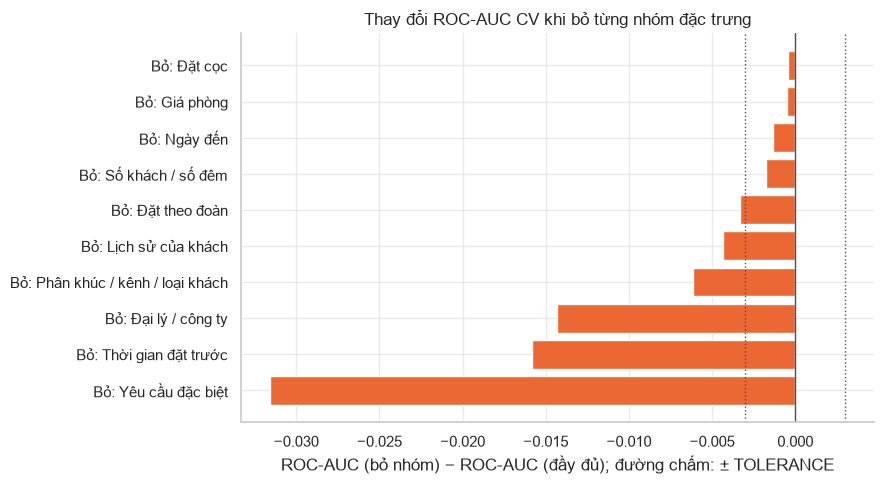

In [72]:
ablation_variants = {"Đầy đủ": selected_spec}
ablation_variants.update({f"Bỏ: {group}": modeling.spec_with(selected_spec, drop_features=tuple(names))
                          for group, names in FEATURE_GROUPS.items()})
ablation_table, ablation_results = run_stage(ablation_variants, "Ablation", train_score=False,
                                             reuse={"Đầy đủ": selected_result}, plot=False)

ablation_delta = ablation_table["delta_vs_first"].drop("Đầy đủ").sort_values()
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(ablation_delta.index, ablation_delta.values,
        color=[COLORS["canceled"] if value < 0 else COLORS["secondary"] for value in ablation_delta.values])
ax.axvline(0, color=COLORS["reference"], linewidth=1)
for edge in (-TOLERANCE, TOLERANCE):
    ax.axvline(edge, color=COLORS["reference"], linestyle=":", linewidth=1)
ax.set(title="Thay đổi ROC-AUC CV khi bỏ từng nhóm đặc trưng",
       xlabel="ROC-AUC (bỏ nhóm) − ROC-AUC (đầy đủ); đường chấm: ± TOLERANCE")
plt.tight_layout()
plt.show()

## 14.2 Thêm giá tương đối

Giá phòng tăng qua các năm (notebook 01 mục 3: giá trung vị quý 3 tăng từ khoảng 90 lên khoảng
119 EUR), nên cùng một mức `adr` có ý nghĩa khác nhau ở các năm khác nhau. `adr_relative` = adr /
giá trung vị của cùng khách sạn, loại phòng và tháng đến; giá trung vị học từ phần train của từng
fold (best practice #3: thống kê chỉ lấy từ train). Giữ đặc trưng này nếu ROC-AUC tăng quá
`TOLERANCE`; có thể gán tay `PRICE_CHOICE`.

Hiện tại                                     ROC-AUC 0.8582 ± 0.0123  (dùng lại)


+ adr_relative                               ROC-AUC 0.8570 ± 0.0132  (44s)


,delta_vs_first,cv_roc_auc,cv_roc_auc_std,cv_average_precision,cv_roc_auc_booking,cv_ap_booking,train_roc_auc,overfit_gap,seconds
Hiện tại,0.0000,0.8582,0.0123,0.8233,0.8012,0.6264,NaN,NaN,22.8414
+ adr_relative,-0.0012,0.8570,0.0132,0.8224,0.8003,0.6265,0.9435,0.0865,43.6921


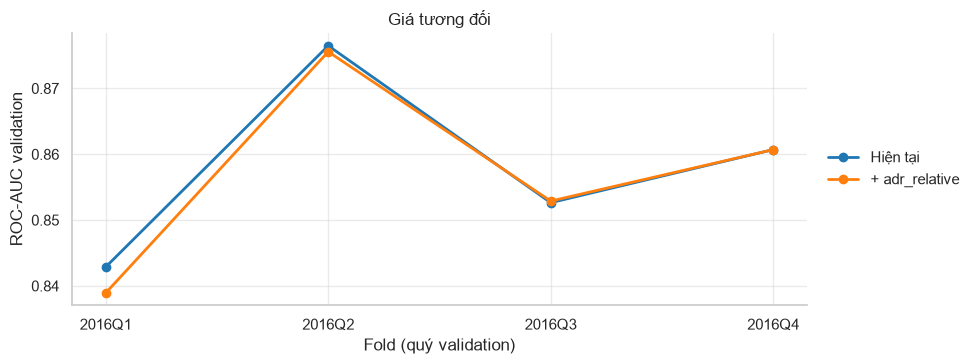

Chọn: Hiện tại


In [73]:
price_variants = {"Hiện tại": selected_spec, "+ adr_relative": modeling.spec_with(selected_spec, relative_adr=True)}
price_table, price_results = run_stage(price_variants, "Giá tương đối", reuse={"Hiện tại": selected_result})
PRICE_CHOICE = experiments.pick_simplest(price_table)  # có thể gán tay một nhãn trong bảng
priced_spec, priced_result = price_variants[PRICE_CHOICE], price_results[PRICE_CHOICE]
print(f"Chọn: {PRICE_CHOICE}")

## 14.3 Huấn luyện theo lượt đặt thay vì theo phòng

Khoảng 23% dòng train thuộc lượt đặt từ 10 phòng trở lên và các dòng này hủy khoảng 69%
(notebook 01 mục 5). Khi mỗi phòng là một mẫu, cả mô hình lẫn độ đo đều bị các khối phòng đoàn
chi phối. Biến thể thứ hai đặt trọng số 1 / số phòng khi huấn luyện, để mỗi lượt đặt đóng góp như
nhau. So sánh cả hai nhóm cột: theo dòng (`cv_roc_auc`, `cv_average_precision`) và theo lượt đặt
(`cv_roc_auc_booking`, `cv_ap_booking`).

Chọn cách nào là **quyết định nghiệp vụ**: khách sạn quan tâm số phòng bị hủy hay số lượt đặt bị
hủy. Mặc định giữ mỗi phòng một mẫu (như các mục trước); đặt `USE_BOOKING_WEIGHTS = True` để đổi.

Mỗi phòng một mẫu                            ROC-AUC 0.8582 ± 0.0123  (dùng lại)


Mỗi lượt đặt một mẫu (trọng số 1 / số phòng) ROC-AUC 0.8608 ± 0.0161  (39s)


,delta_vs_first,cv_roc_auc,cv_roc_auc_std,cv_average_precision,cv_roc_auc_booking,cv_ap_booking,train_roc_auc,overfit_gap,seconds
Mỗi phòng một mẫu,0.0000,0.8582,0.0123,0.8233,0.8012,0.6264,NaN,NaN,22.8414
Mỗi lượt đặt một mẫu (trọng số 1 / số phòng),0.0026,0.8608,0.0161,0.8233,0.8054,0.6306,0.9338,0.0730,39.3850


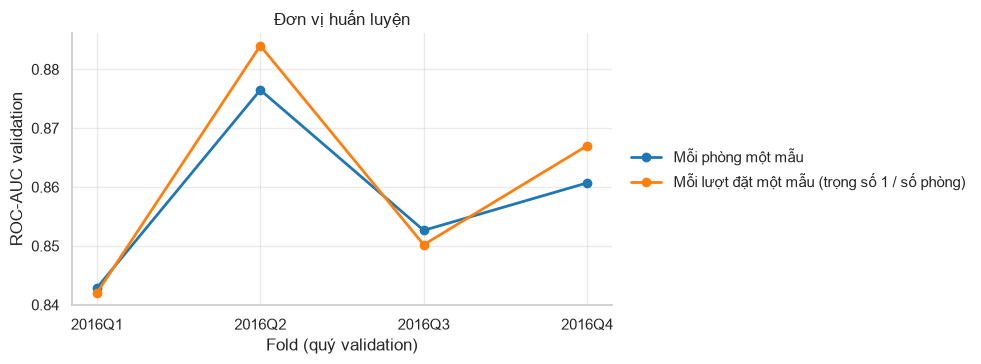

Dùng: Mỗi phòng một mẫu
{
  "ensemble": [
    {
      "name": "Random Forest",
      "encoding": "onehot",
      "half_life_days": 45,
      "booking_weights": false,
      "pipeline": {},
      "params": {
        "n_estimators": 300,
        "min_samples_leaf": 10,
        "max_features": 0.2,
        "max_depth": null,
        "class_weight": null
      }
    },
    {
      "name": "XGBoost",
      "encoding": "onehot",
      "half_life_days": 180,
      "booking_weights": false,
      "pipeline": {},
      "params": {
        "subsample": 0.85,
        "scale_pos_weight": 1.75,
        "reg_lambda": 1.0,
        "n_estimators": 400,
        "min_child_weight": 10,
        "max_depth": 4,
        "learning_rate": 0.03,
        "colsample_bytree": 0.5
      }
    },
    {
      "name": "LightGBM",
      "encoding": "onehot",
      "half_life_days": 90,
      "booking_weights": false,
      "pipeline": {},
      "params": {
        "subsample_freq": 1,
        "subsample": 0.7,
      

In [74]:
booking_variants = {
    "Mỗi phòng một mẫu": priced_spec,
    "Mỗi lượt đặt một mẫu (trọng số 1 / số phòng)": modeling.spec_with(priced_spec, booking_weights=True),
}
booking_table, booking_results = run_stage(booking_variants, "Đơn vị huấn luyện",
                                           reuse={"Mỗi phòng một mẫu": priced_result})
USE_BOOKING_WEIGHTS = False
champion_label = list(booking_variants)[int(USE_BOOKING_WEIGHTS)]
champion_spec, champion_result = booking_variants[champion_label], booking_results[champion_label]
champion_summary = champion_result.summary()
print(f"Dùng: {champion_label}")
print(json.dumps(champion_spec, indent=2, ensure_ascii=False))

## 14.4 Độ dài lịch sử huấn luyện

Huấn luyện lại champion cho fold cuối (validation 2016Q4) với 3, 6, 9, 12 và 15 tháng gần nhất
trước đó (15 tháng là toàn bộ). Đây là learning curve theo thời gian (tài liệu: *better now vs.
better later*, learning curve): nếu ROC-AUC còn tăng khi thêm tháng cũ, có thêm dữ liệu sẽ còn
giúp; nếu đi ngang hoặc giảm, dữ liệu cũ ít giá trị, khớp với lý do dùng trọng số theo thời gian.

 3 tháng (15,006 dòng): ROC-AUC 0.8368


 6 tháng (31,196 dòng): ROC-AUC 0.8510


 9 tháng (42,145 dòng): ROC-AUC 0.8587


12 tháng (52,345 dòng): ROC-AUC 0.8586


15 tháng (64,110 dòng): ROC-AUC 0.8607


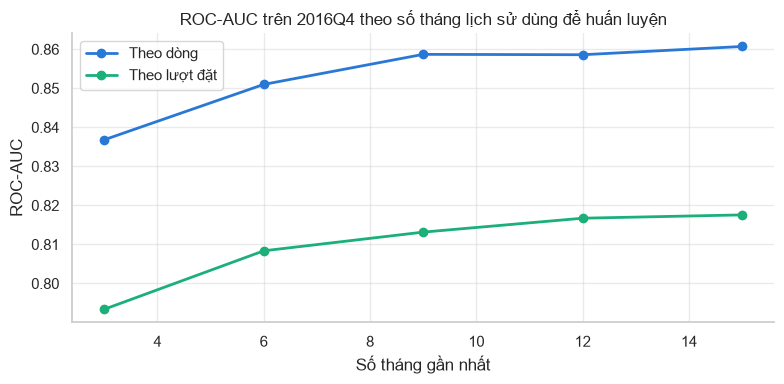

In [75]:
arrival = train_df[config.TIME_COLUMN]
_, last_valid = cv_folds[-1]
valid_start = arrival.iloc[last_valid].min()
valid_weights = experiments.booking_weights(X_train.iloc[last_valid])
curve_rows = []
for months in [3, 6, 9, 12, 15]:
    window = np.flatnonzero((arrival >= valid_start - pd.DateOffset(months=months)) & (arrival < valid_start))
    model = modeling.build_from_spec(champion_spec).fit(X_train.iloc[window], y_train.iloc[window])
    proba = model.predict_proba(X_train.iloc[last_valid])[:, 1]
    curve_rows.append({"months": months, "train_rows": len(window),
                       "roc_auc": roc_auc_score(y_train.iloc[last_valid], proba),
                       "roc_auc_booking": roc_auc_score(y_train.iloc[last_valid], proba, sample_weight=valid_weights)})
    print(f"{months:>2} tháng ({len(window):,} dòng): ROC-AUC {curve_rows[-1]['roc_auc']:.4f}")
history_curve = pd.DataFrame(curve_rows)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(history_curve["months"], history_curve["roc_auc"], marker="o", linewidth=2, color=COLORS["primary"],
        label="Theo dòng")
ax.plot(history_curve["months"], history_curve["roc_auc_booking"], marker="o", linewidth=2,
        color=COLORS["secondary"], label="Theo lượt đặt")
ax.set(title="ROC-AUC trên 2016Q4 theo số tháng lịch sử dùng để huấn luyện", xlabel="Số tháng gần nhất",
       ylabel="ROC-AUC")
ax.legend()
plt.tight_layout()
plt.show()

# 15. Ngưỡng phân loại, hiệu chỉnh xác suất và huấn luyện cuối

Ngưỡng tối đa F1 được chọn trên dự đoán OOF của champion; test set vẫn chưa được mở. F1 tính cho
lớp hủy (*asymmetric metric*), phù hợp khi lớp hủy là lớp cần phát hiện. Biểu đồ hiệu chỉnh cho
biết xác suất dự đoán có khớp với tỷ lệ hủy thực tế hay không.

Ngưỡng chọn: 0.456  (F1 out-of-fold = 0.7164, precision = 0.8189, recall = 0.6367)


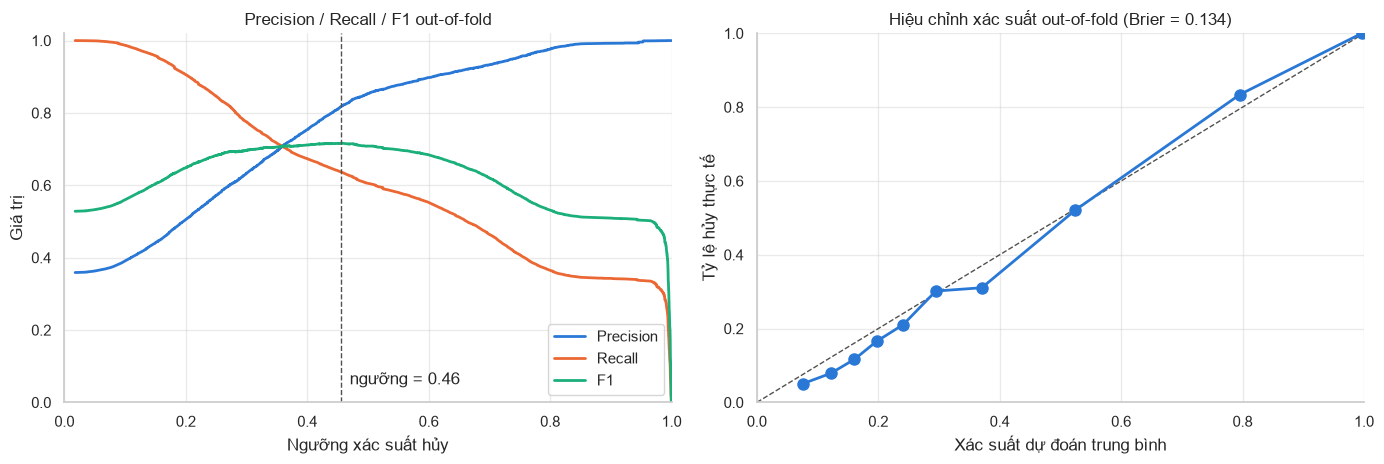

In [76]:
champion_oof = champion_result.oof
has_oof = ~np.isnan(champion_oof)
decision_threshold, threshold_curve = evaluation.best_f1_threshold(y_train[has_oof], champion_oof[has_oof])
best_row = threshold_curve.loc[threshold_curve["f1"].idxmax()]
print(f"Ngưỡng chọn: {decision_threshold:.3f}  (F1 out-of-fold = {best_row['f1']:.4f}, "
      f"precision = {best_row['precision']:.4f}, recall = {best_row['recall']:.4f})")
oof_brier = evaluation.binary_metrics(y_train[has_oof], champion_oof[has_oof])["brier"]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for column, color, label in [("precision", COLORS["primary"], "Precision"), ("recall", COLORS["canceled"], "Recall"),
                             ("f1", COLORS["secondary"], "F1")]:
    axes[0].plot(threshold_curve["threshold"], threshold_curve[column], color=color, linewidth=2, label=label)
axes[0].axvline(decision_threshold, color=COLORS["reference"], linestyle="--", linewidth=1)
axes[0].annotate(f"ngưỡng = {decision_threshold:.2f}", (decision_threshold, 0.05), xytext=(6, 0), textcoords="offset points")
axes[0].set(xlabel="Ngưỡng xác suất hủy", ylabel="Giá trị", title="Precision / Recall / F1 out-of-fold",
            xlim=(0, 1), ylim=(0, 1.02))
axes[0].legend(loc="lower right")

observed, predicted = calibration_curve(y_train[has_oof], champion_oof[has_oof], n_bins=10, strategy="quantile")
axes[1].plot([0, 1], [0, 1], color=COLORS["reference"], linestyle="--", linewidth=1)
axes[1].plot(predicted, observed, color=COLORS["primary"], linewidth=2, marker="o", markersize=8)
axes[1].set(xlabel="Xác suất dự đoán trung bình", ylabel="Tỷ lệ hủy thực tế",
            title=f"Hiệu chỉnh xác suất out-of-fold (Brier = {oof_brier:.3f})", xlim=(0, 1), ylim=(0, 1))
plt.tight_layout()
plt.show()

Huấn luyện champion trên toàn bộ train. Mô hình được fit một luồng để mô hình dựng lại từ
`model_spec` ở mục 18 cho kết quả trùng khớp; lúc dự đoán thì dùng mọi luồng.

In [77]:
started = time.perf_counter()
champion = modeling.set_model_threads(modeling.build_from_spec(champion_spec), 1).fit(X_train, y_train)
champion = modeling.set_model_threads(champion, N_JOBS)
print(f"Đã huấn luyện {CHAMPION} trên {len(X_train):,} dòng ({time.perf_counter() - started:.0f}s)")

Đã huấn luyện Ensemble (Top 3 theo CV): Random Forest + XGBoost + LightGBM trên 78,586 dòng (62s)


# 16. Đánh giá champion trên test set (mở một lần)

Mô hình, cách xử lý dữ liệu và ngưỡng đã được chọn hoàn toàn trên train. Test set (01–04/2017)
chỉ được đọc ở mục này. Kết quả được báo cáo theo dòng, theo lượt đặt (trọng số 1 / số phòng) và
trên test đã bỏ dòng trùng.

In [78]:
test_df = data.read_split(PROCESSED_DIR, "test")
X_test, y_test = test_df[INPUTS], test_df[config.TARGET]

started = time.perf_counter()
test_proba = champion.predict_proba(X_test)[:, 1]
inference_seconds = time.perf_counter() - started
test_pred = (test_proba >= decision_threshold).astype(int)

test_metrics = evaluation.binary_metrics(y_test, test_proba, decision_threshold)
booking_metrics = evaluation.binary_metrics(y_test, test_proba, decision_threshold,
                                            sample_weight=experiments.booking_weights(X_test))
content_columns = test_df.columns.drop(config.ID_COLUMN)
dedup_position = test_df.index.get_indexer(test_df.drop_duplicates(subset=content_columns).index)
dedup_metrics = evaluation.binary_metrics(y_test.iloc[dedup_position], test_proba[dedup_position], decision_threshold)

test_table = pd.DataFrame({"Theo dòng (mỗi phòng)": test_metrics,
                           "Theo lượt đặt (trọng số 1 / số phòng)": booking_metrics,
                           "Bỏ dòng trùng": dedup_metrics}).T
test_table.insert(0, "rows", [len(test_df), len(test_df), len(dedup_position)])
display(test_table)
print(f"ROC-AUC theo dòng:     CV {champion_summary['cv_roc_auc']:.4f} → test {test_metrics['roc_auc']:.4f}")
print(f"ROC-AUC theo lượt đặt: CV {champion_summary['cv_roc_auc_booking']:.4f} → test {booking_metrics['roc_auc']:.4f}")
print(f"F1 tại ngưỡng 0,5: {f1_score(y_test, (test_proba >= 0.5).astype(int)):.4f}; "
      f"tỷ lệ hủy test {y_test.mean():.4f}; dự đoán {1e6 * inference_seconds / len(X_test):.1f} µs / dòng")

,rows,roc_auc,average_precision,f1,precision,recall,accuracy,balanced_accuracy,brier,log_loss
Theo dòng (mỗi phòng),18442,0.8653,0.8241,0.6890,0.7685,0.6244,0.7941,0.7581,0.1386,0.4246
Theo lượt đặt (trọng số 1 / số phòng),18442,0.8163,0.6504,0.5626,0.6549,0.4931,0.7789,0.6939,0.1529,0.4680
Bỏ dòng trùng,13872,0.8115,0.6406,0.5541,0.6412,0.4879,0.7784,0.6903,0.1527,0.4681


ROC-AUC theo dòng:     CV 0.8582 → test 0.8653
ROC-AUC theo lượt đặt: CV 0.8012 → test 0.8163
F1 tại ngưỡng 0,5: 0.6852; tỷ lệ hủy test 0.3653; dự đoán 43.5 µs / dòng


,precision,recall,f1-score,support
Không hủy,0.8049,0.8918,0.8461,"11,706.0000"
Hủy,0.7685,0.6244,0.6890,"6,736.0000"
accuracy,0.7941,0.7941,0.7941,0.7941
macro avg,0.7867,0.7581,0.7676,"18,442.0000"
weighted avg,0.7916,0.7941,0.7887,"18,442.0000"


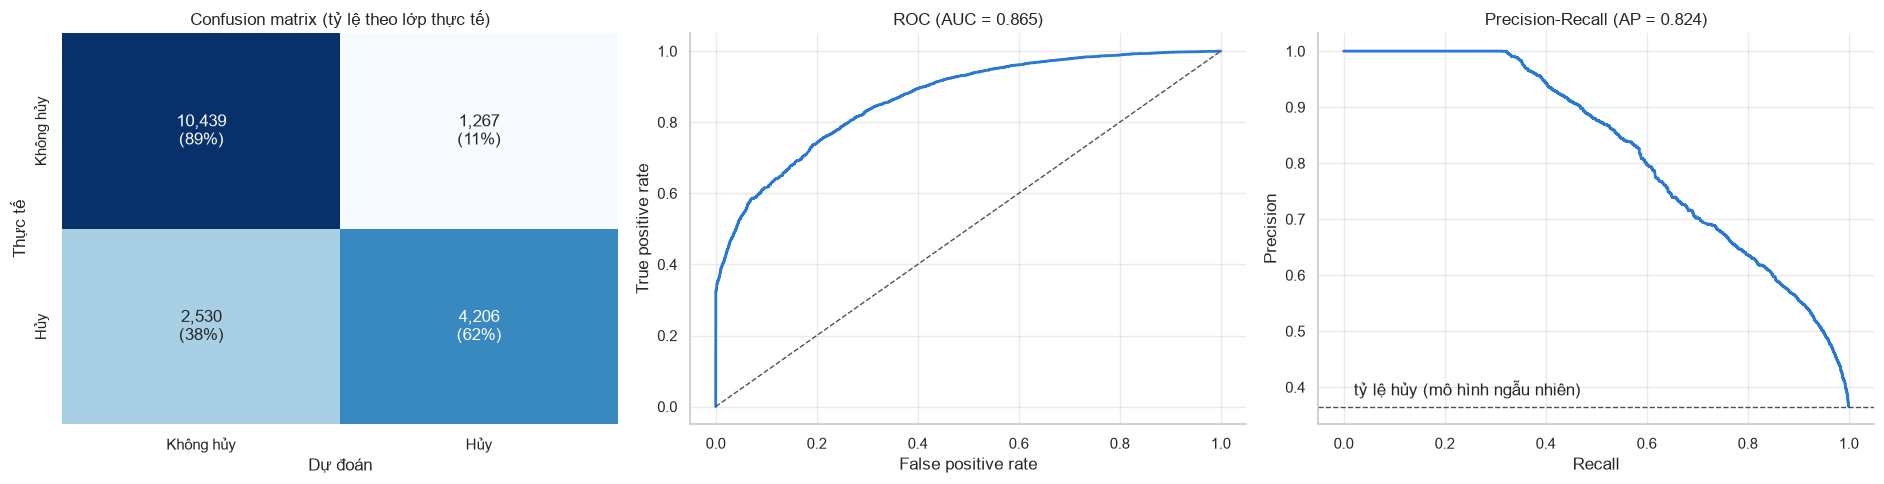

In [79]:
LABELS = ["Không hủy", "Hủy"]
display(pd.DataFrame(classification_report(y_test, test_pred, target_names=LABELS, output_dict=True)).T)

counts = confusion_matrix(y_test, test_pred)
shares = confusion_matrix(y_test, test_pred, normalize="true")
cells = np.array([[f"{n:,}\n({p:.0%})" for n, p in zip(row_n, row_p)] for row_n, row_p in zip(counts, shares)])
fpr, tpr, _ = roc_curve(y_test, test_proba)
curve_precision, curve_recall, _ = precision_recall_curve(y_test, test_proba)

fig, axes = plt.subplots(1, 3, figsize=(19, 5))
sns.heatmap(shares, annot=cells, fmt="", cmap="Blues", cbar=False, xticklabels=LABELS, yticklabels=LABELS, ax=axes[0])
axes[0].set(title="Confusion matrix (tỷ lệ theo lớp thực tế)", xlabel="Dự đoán", ylabel="Thực tế")
axes[1].plot(fpr, tpr, color=COLORS["primary"], linewidth=2)
axes[1].plot([0, 1], [0, 1], color=COLORS["reference"], linestyle="--", linewidth=1)
axes[1].set(title=f"ROC (AUC = {test_metrics['roc_auc']:.3f})", xlabel="False positive rate", ylabel="True positive rate")
axes[2].plot(curve_recall, curve_precision, color=COLORS["primary"], linewidth=2)
axes[2].axhline(y_test.mean(), color=COLORS["reference"], linestyle="--", linewidth=1)
axes[2].annotate("tỷ lệ hủy (mô hình ngẫu nhiên)", (0.02, y_test.mean() + 0.02))
axes[2].set(title=f"Precision-Recall (AP = {test_metrics['average_precision']:.3f})", xlabel="Recall", ylabel="Precision")
plt.tight_layout()
plt.show()

### Theo khách sạn và theo tháng

Nếu chất lượng giảm dần theo tháng, đó là dấu hiệu dữ liệu đang thay đổi so với giai đoạn huấn
luyện. Hai khách sạn có tỷ lệ hủy khác nhau nhiều (notebook 01 mục 2) nên được báo cáo riêng.

In [80]:
by_hotel = evaluation.metrics_by_group(y_test, test_proba, test_df["hotel"], decision_threshold)
display(by_hotel[["group", "rows", "cancel_rate", "roc_auc", "average_precision", "f1", "precision", "recall", "accuracy"]])

by_month = evaluation.metrics_by_group(y_test, test_proba, test_df[config.TIME_COLUMN].dt.to_period("M"), decision_threshold)
display(by_month[["group", "rows", "cancel_rate", "roc_auc", "f1"]])

,group,rows,cancel_rate,roc_auc,average_precision,f1,precision,recall,accuracy
0,City Hotel,12255,0.4252,0.8654,0.8567,0.7222,0.7774,0.6743,0.7794
1,Resort Hotel,6187,0.2465,0.8467,0.7010,0.5585,0.7261,0.4538,0.8232


,group,rows,cancel_rate,roc_auc,f1
0,2017-01,3673,0.3400,0.8794,0.6717
1,2017-02,4168,0.3258,0.8437,0.6340
2,2017-03,4948,0.3377,0.8613,0.6885
3,2017-04,5653,0.4348,0.8707,0.7277


# 17. Giải thích mô hình

Permutation importance đo mức giảm ROC-AUC trên test khi xáo trộn ngẫu nhiên **một cột đầu vào
gốc** (tài liệu: *how much the model performance deteriorates if a feature is removed*). Khác với
độ quan trọng sẵn có của cây ở các section trước, cách này áp dụng được cho mọi mô hình và đo trên
dữ liệu chưa dùng để huấn luyện. Bước này chỉ để diễn giải, không dùng để chỉnh mô hình.

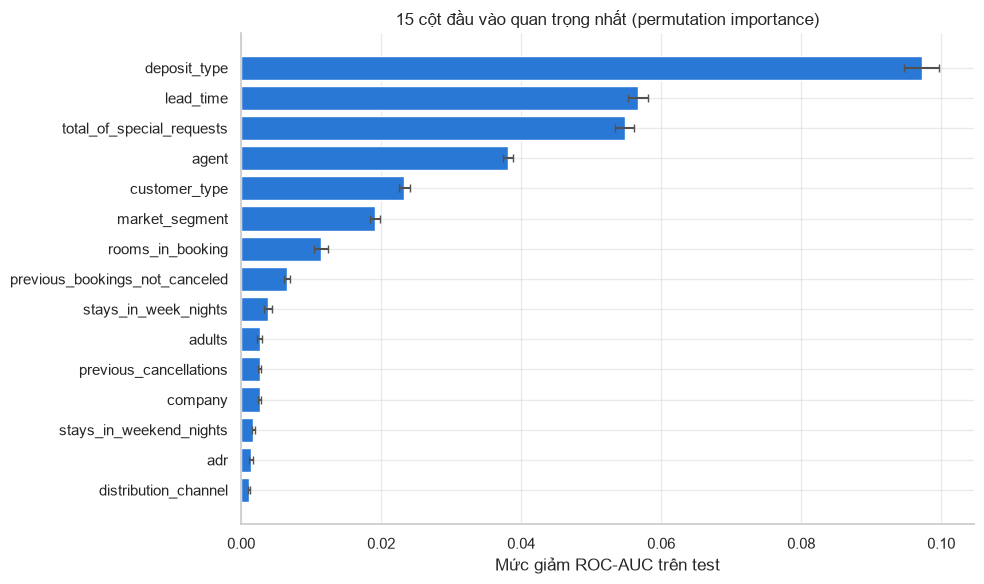

,input,importance_mean,importance_std
0,deposit_type,0.0972,0.0025
1,lead_time,0.0567,0.0014
2,total_of_special_requests,0.0548,0.0014
3,agent,0.0382,0.0007
4,customer_type,0.0233,0.0007
5,market_segment,0.0191,0.0007
6,rooms_in_booking,0.0114,0.0010
7,previous_bookings_not_canceled,0.0065,0.0005
8,stays_in_week_nights,0.0038,0.0005
9,adults,0.0026,0.0004


In [81]:
importance = permutation_importance(champion, X_test, y_test, scoring="roc_auc", n_repeats=5,
                                    random_state=RANDOM_STATE, n_jobs=1)
importance_df = pd.DataFrame({"input": INPUTS, "importance_mean": importance.importances_mean,
                              "importance_std": importance.importances_std}
                             ).sort_values("importance_mean", ascending=False).reset_index(drop=True)

top = importance_df.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top["input"], top["importance_mean"], xerr=top["importance_std"],
        color=COLORS["primary"], error_kw={"ecolor": COLORS["reference"], "capsize": 3})
ax.set(title="15 cột đầu vào quan trọng nhất (permutation importance)", xlabel="Mức giảm ROC-AUC trên test")
plt.tight_layout()
plt.show()
display(importance_df.head(10))

# 18. Lưu mô hình

Mô hình được lưu nguyên khối (tạo đặc trưng + mã hóa + mô hình + trọng số) cùng
`model_card.json`: cột đầu vào, schema, cấu hình để huấn luyện lại, ngưỡng, kết quả CV và test,
phiên bản thư viện. Sau đó kiểm tra: nạp lại cho cùng kết quả, dựng lại từ `model_spec` tái lập
đúng mô hình, và một bản ghi gốc dạng dict dự đoán được trực tiếp.

In [82]:
MODELS_DIR.mkdir(exist_ok=True)
model_path = MODELS_DIR / "hotel_cancellation_pipeline.joblib"
joblib.dump(champion, model_path)

model_card = experiments.to_builtin({
    "model_name": CHAMPION,
    "created_at": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "artifact": model_path.name,
    "task": "Dự đoán is_canceled tại thời điểm đặt phòng được xác nhận",
    "input_columns": INPUTS,
    "input_schema": feature_spec["input_schema"],
    "model_spec": champion_spec,
    "decision_threshold": decision_threshold,
    "cv_roc_auc": champion_summary["cv_roc_auc"],
    "cv_summary": champion_summary,
    "test_metrics": test_metrics,
    "test_metrics_by_booking": booking_metrics,
    "test_metrics_deduplicated": dedup_metrics,
    "test_metrics_by_hotel": by_hotel.set_index("group")[["roc_auc", "f1", "precision", "recall"]].to_dict(orient="index"),
    "data": {"raw_sha256": feature_spec["raw_sha256"], **{name: feature_spec["splits"][name] for name in config.SPLITS}},
    "environment": {"python": platform.python_version(),
                    **{package: version(package) for package in
                       ["scikit-learn", "pandas", "numpy", "lightgbm", "xgboost", "catboost"]}},
})
card_path = MODELS_DIR / "model_card.json"
card_path.write_text(json.dumps(model_card, indent=2, ensure_ascii=False), encoding="utf-8")
print(f"Đã lưu {model_path} ({model_path.stat().st_size / 1e6:.1f} MB) và {card_path}")

Đã lưu .\models\hotel_cancellation_pipeline.joblib (70.4 MB) và .\models\model_card.json


In [83]:
reloaded = joblib.load(model_path)
assert np.allclose(reloaded.predict_proba(X_test.head(500))[:, 1], test_proba[:500])

# Huấn luyện 1 luồng giống mục 15 để kết quả trùng khớp chính xác.
rebuilt = modeling.set_model_threads(modeling.build_from_spec(model_card["model_spec"]), 1).fit(X_train, y_train)
max_difference = np.abs(rebuilt.predict_proba(X_test)[:, 1] - test_proba).max()
print(f"Chênh lệch lớn nhất giữa mô hình dựng lại và mô hình đã lưu: {max_difference:.2e}")
assert max_difference < 1e-6

booking = {
    "hotel": "City Hotel", "arrival_date_month": "March", "meal": "BB", "market_segment": "Online TA",
    "distribution_channel": "TA/TO", "reserved_room_type": "A", "deposit_type": "No Deposit",
    "customer_type": "Transient", "lead_time": 45, "arrival_date_year": 2017, "arrival_date_week_number": 11,
    "arrival_date_day_of_month": 14, "stays_in_weekend_nights": 1, "stays_in_week_nights": 2, "adults": 2,
    "children": 0, "babies": 0, "is_repeated_guest": 0, "previous_cancellations": 0,
    "previous_bookings_not_canceled": 0, "agent": 9.0, "company": None, "days_in_waiting_list": 0,
    "adr": 95.0, "total_of_special_requests": 1, "rooms_in_booking": 1,
}
probability = reloaded.predict_proba(pd.DataFrame([booking])[INPUTS])[0, 1]
print(f"Xác suất hủy của bản ghi mẫu: {probability:.3f} → dự đoán: {'Hủy' if probability >= decision_threshold else 'Không hủy'}")

Chênh lệch lớn nhất giữa mô hình dựng lại và mô hình đã lưu: 2.22e-16
Xác suất hủy của bản ghi mẫu: 0.299 → dự đoán: Không hủy


# 19. Kết luận

_Điền sau khi chạy notebook:_

- Mô hình được chọn, cấu hình và lý do (mục 13), so với mốc Logistic Regression và Dummy.
- Kỹ thuật xử lý dữ liệu nào giúp mô hình nào (bước X.2), trọng số theo thời gian giúp bao nhiêu
  (bước X.3), tinh chỉnh giúp bao nhiêu (bước X.4).
- Ensemble và stacking có đáng không (mục 12); kết quả ablation, giá tương đối, huấn luyện theo
  lượt đặt và độ dài lịch sử (mục 14).
- Kết quả trên test so với CV, theo dòng và theo lượt đặt, theo khách sạn và theo tháng (mục 16).